In [1]:
%cd /sdf/group/neutrino/pgranger/larnd-sim-jax
import sys
!{sys.executable} -m pip install -e .

/sdf/group/neutrino/pgranger/larnd-sim-jax


/sdf/home/p/pgranger/.local/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


Defaulting to user installation because normal site-packages is not writeable
Obtaining file:///sdf/group/neutrino/pgranger/larnd-sim-jax
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for larndsim (pyproject.toml) ... done
  Created wheel for larndsim: filename=larndsim-0.1.dev316+g368f6c8b0.d20260128-py3-none-any.whl size=10154 sha256=32931fb9b122ee28f4e13cde8d66f788c221196b163ef493b2c0dcac73966eaa
  Stored in directory: /lscratch/pgranger/tmp/pip-ephem-wheel-cache-0wyrm2tf/wheels/e7/e6/52/708c2eabf9d963fabdda3635808ffba6fe643aaaafd1316c9c
Successfully built larndsim
  Attempting uninstall: larndsim
    Found existing installation: larndsim 0.1.dev316+g368f6c8b0.d20260126
    Uninstalling larndsim-0.1.dev316+g368f6c8b0.d20260126:
      Successfully uninstalled lar

In [2]:
import h5py
import numpy as np
from jax import lax, jit
from jax.scipy.special import erf
import jax.numpy as jnp
from functools import partial
import jax
from tqdm import tqdm
import matplotlib.pyplot as plt

def load_wfs(fname):
    with h5py.File(fname, 'r') as f:
        wfs = f['wfs'][:]
        unique_pixels = f['unique_pixels'][:]
    return wfs, unique_pixels

def load_mc(fname):
    with h5py.File(fname, 'r') as f:
        mc_adcs = f['results'][:]
        mc_ticks = f['results_ticks'][:]
    return mc_adcs, mc_ticks

def filter_mc():
    mask = (np.sum(results_ticks < 1998, axis=(0, 2)) > 0) & (np.sum(results > digitize(ref_params, ref_params.DISCRIMINATION_THRESHOLD), axis=(0, 2)) > 0) & (unique_pixels >= 0)

def get_summary_stats(mc_adcs, mc_ticks):
    triggered = (mc_ticks < 1998)
    fraction_triggered = jnp.sum(triggered, axis=0)/triggered.shape[0]
    tick_avg = jnp.mean(mc_ticks, where=triggered, axis=0)
    adcs_avg = jnp.mean(mc_adcs, where=triggered, axis=0)
    return fraction_triggered, tick_avg, adcs_avg

def estimate_distrib(wfs, sigma=900, threshold=7000):
    q_sum = np.cumsum(wfs[:, 1:], axis=1)*0.1 #0.1 for sampling

    eps = 1e-10

    _, Nticks = q_sum.shape

    erf_term = erf((q_sum - threshold)/(jnp.sqrt(2)*sigma)) # erf_term[Nvalues, Nticks]

    erf_term_signal = lax.cummax(erf_term, axis=1)  # erf_term_signal[Nvalues, Nticks]
    # max_future_signal = jnp.frompyfunc(jnp.maximum, 2, 1).accumulate(q_sum_loc[:, ::-1], axis=-1)[:, ::-1]
    max_future_signal = lax.cummax(q_sum, axis=1, reverse=True)  # max_future_signal[Nvalues, Nticks]
    
    guess = 0.5*(erf_term_signal[..., 1:] - erf_term_signal[..., :-1]) # guess[Nvalues, Nticks - 1]
    # guess = jnp.clip(guess, 0, 1)  # Ensure guess is between 0 and 1, should not be needed but erf got odd behavior for some reason

    interval = 18
    shifted_ticks = jnp.arange(Nticks - 1) + interval + 1 # shifted_ticks[Nticks - 1]
    shifted_ticks = jnp.clip(shifted_ticks, 0, Nticks - 1)

    prob_event = jnp.clip(0.5*(erf_term[..., shifted_ticks] - erf_term[..., :-1]), 0, guess)
    esperance_value = q_sum[..., shifted_ticks] + threshold - 0.5*(q_sum[..., 1:] + q_sum[..., :-1]) # esperance_value[Nvalues, Nticks - 1]
    return prob_event


th = 7000

wfs, unique_pixels = load_wfs("/sdf/group/neutrino/pgranger/larnd-sim-jax-bak/old_wfs.h5")
mc_adcs, mc_ticks = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_thresh{th}.h5")

estimated = estimate_distrib(wfs, threshold=th)
fraction_triggered, mc_tick_avg, mc_adcs_avg = get_summary_stats(mc_adcs, mc_ticks)

%config InlineBackend.figure_format='retina'
        

In [3]:
def get_summary_distribs(mc_adcs, mc_ticks):
    gain = 4e-3
    v_pedestal = 580
    v_ref = 1300
    v_cm = 288
    adc_counts = 2**8
    dig_adcs = jnp.minimum((jnp.maximum((mc_adcs*gain+v_pedestal - v_cm), 0) * adc_counts/(v_ref-v_cm)), adc_counts)
    
    adc_bins = jnp.linspace(-0.5, 200.5, 202)
    tick_bins = jnp.linspace(-0.5, 2000.5, 2002)
    indices_adc = jnp.digitize(dig_adcs, adc_bins)
    
    histograms_adc = jnp.zeros((dig_adcs.shape[1], dig_adcs.shape[2], len(adc_bins)-1))
    for i,index in enumerate(jnp.unique(indices_adc)):
        histograms_adc = histograms_adc.at[:, :, index].set(jnp.sum( indices_adc==index, axis=0 ))

    indices_ticks = jnp.digitize(mc_ticks, tick_bins)
    histograms_ticks = jnp.zeros((mc_ticks.shape[1], mc_ticks.shape[2], len(tick_bins)-1))
    for i,index in enumerate(jnp.unique(indices_ticks)):
        histograms_ticks = histograms_ticks.at[:, :, index].set(jnp.sum( indices_ticks==index, axis=0 ))
    return histograms_adc, histograms_ticks

In [5]:
adc_hists, ticks_hists = get_summary_distribs(mc_adcs, mc_ticks)

In [33]:
jnp.linspace(69.5, 125.5, 57)

Array([ 69.5    ,  70.5    ,  71.5    ,  72.5    ,  73.5    ,  74.5    ,
        75.5    ,  76.5    ,  77.5    ,  78.5    ,  79.5    ,  80.5    ,
        81.5    ,  82.5    ,  83.5    ,  84.5    ,  85.5    ,  86.5    ,
        87.5    ,  88.5    ,  89.5    ,  90.5    ,  91.5    ,  92.5    ,
        93.5    ,  94.5    ,  95.5    ,  96.5    ,  97.5    ,  98.5    ,
        99.5    , 100.5    , 101.5    , 102.5    , 103.5    , 104.5    ,
       105.5    , 106.5    , 107.5    , 108.5    , 109.5    , 110.5    ,
       111.5    , 112.5    , 113.5    , 114.5    , 115.5    , 116.5    ,
       117.49999, 118.5    , 119.5    , 120.5    , 121.5    , 122.5    ,
       123.5    , 124.5    , 125.5    ], dtype=float32)

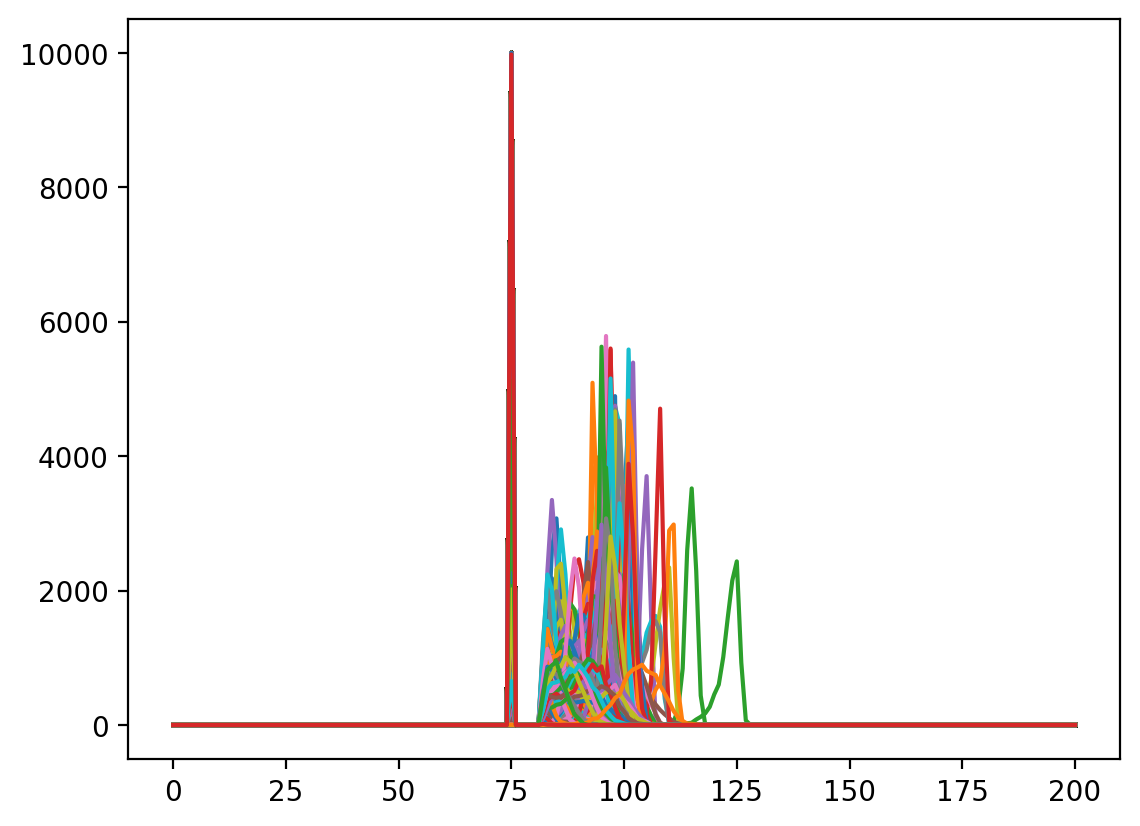

In [6]:
for j in range(0, adc_hists.shape[0]):
    plt.plot(adc_hists[j, 1, :])
# plt.xlim(0, 10)

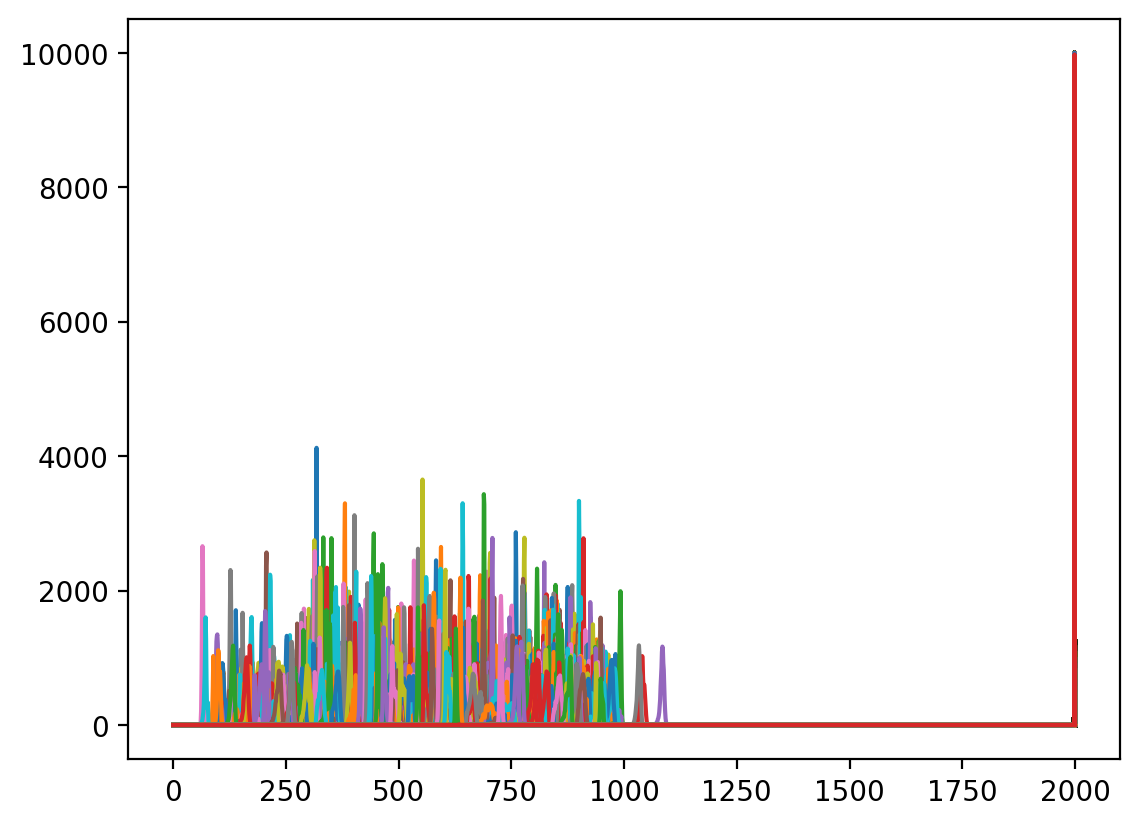

In [43]:
for j in range(0, ticks_hists.shape[0]):
    plt.plot(ticks_hists[j, 1, :])

In [6]:
thlist = np.arange(3000, 10001, 1000)

mean_triggered_fraction = np.zeros((10, len(thlist)))

rstart = 50
rend = 100

ihit = 50
tbins = np.arange(0, 2001)

ticks_of_hit = np.zeros((len(thlist), 10, 2000))


for i, th in tqdm(enumerate(thlist)):
    
    mc_adcs, mc_ticks = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_thresh{th}.h5")

    fraction_triggered, tick_avg, adcs_avg = get_summary_stats(mc_adcs, mc_ticks)

    mean_triggered_fraction[:, i] = np.mean(fraction_triggered, axis=0)
    for n in range(10):
        values, _ = np.histogram(mc_ticks[:, ihit, n], bins=tbins)
        ticks_of_hit[i, n] = values
    
    

8it [00:17,  2.18s/it]


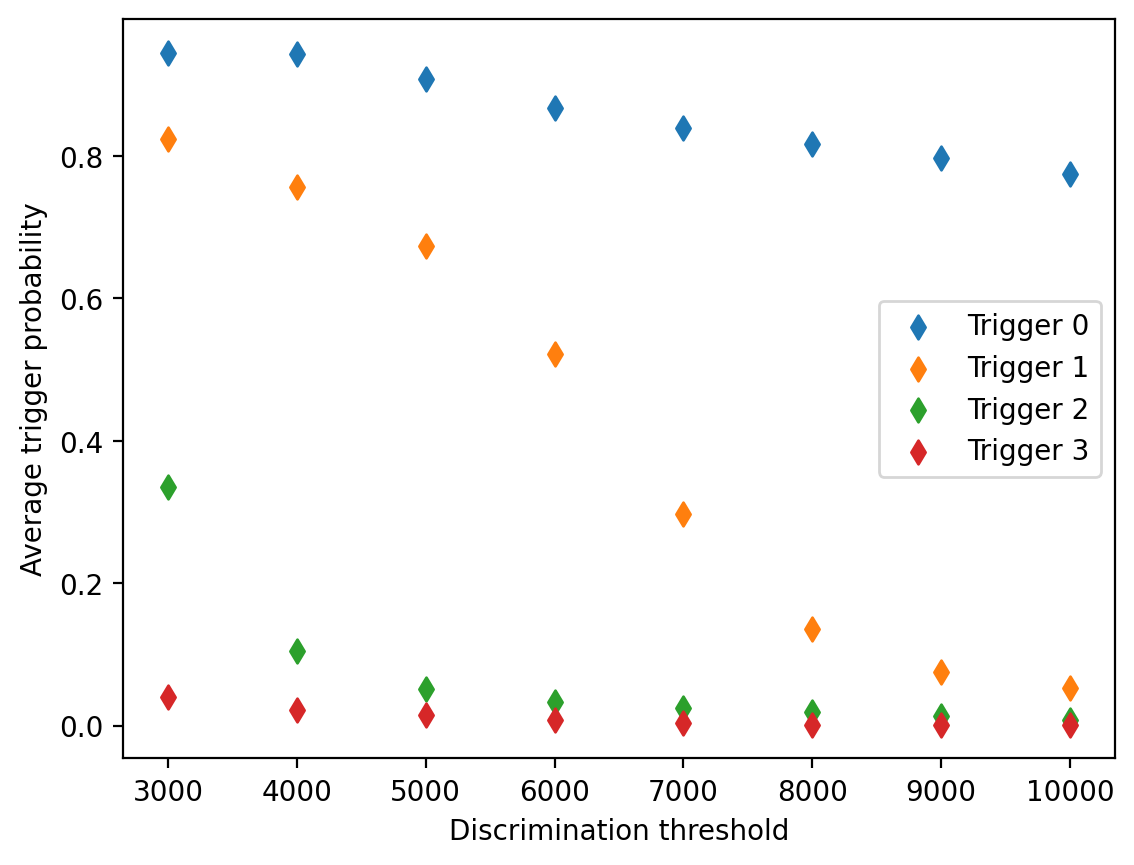

In [3]:
for i in range(4):
    plt.scatter(thlist, mean_triggered_fraction[i], marker='d', label=f'Trigger {i}')
plt.xlabel("Discrimination threshold")
plt.ylabel("Average trigger probability")
plt.legend()

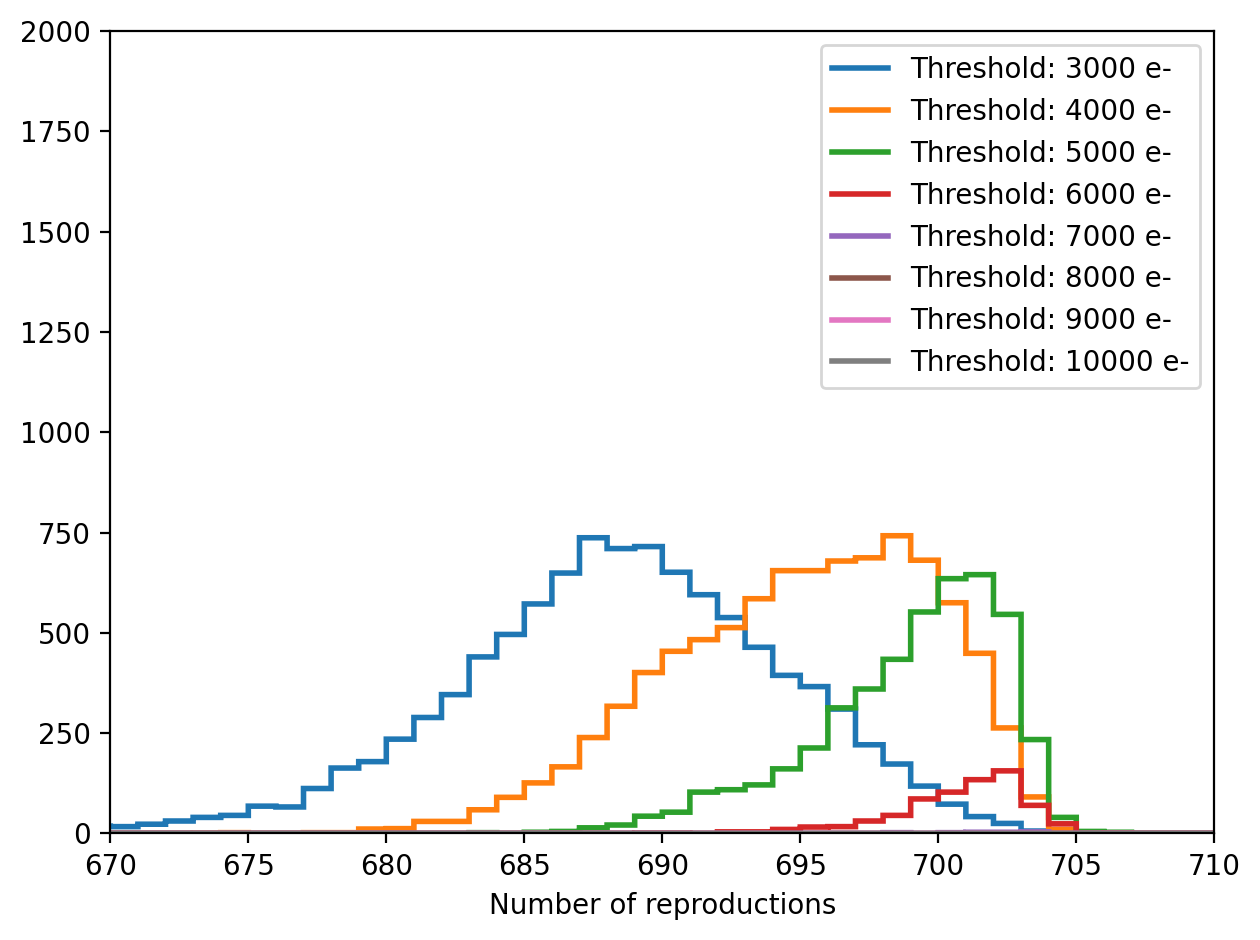

In [3]:

for i, th in enumerate(thlist):
    plt.stairs(ticks_of_hit[i, 1], tbins, label=f"Threshold: {th} e-", linewidth=2)
plt.legend()
plt.xlim(670, 710)
plt.ylim(0, 2000)
plt.xlabel("Tick")
plt.xlabel("Number of reproductions")
plt.tight_layout()

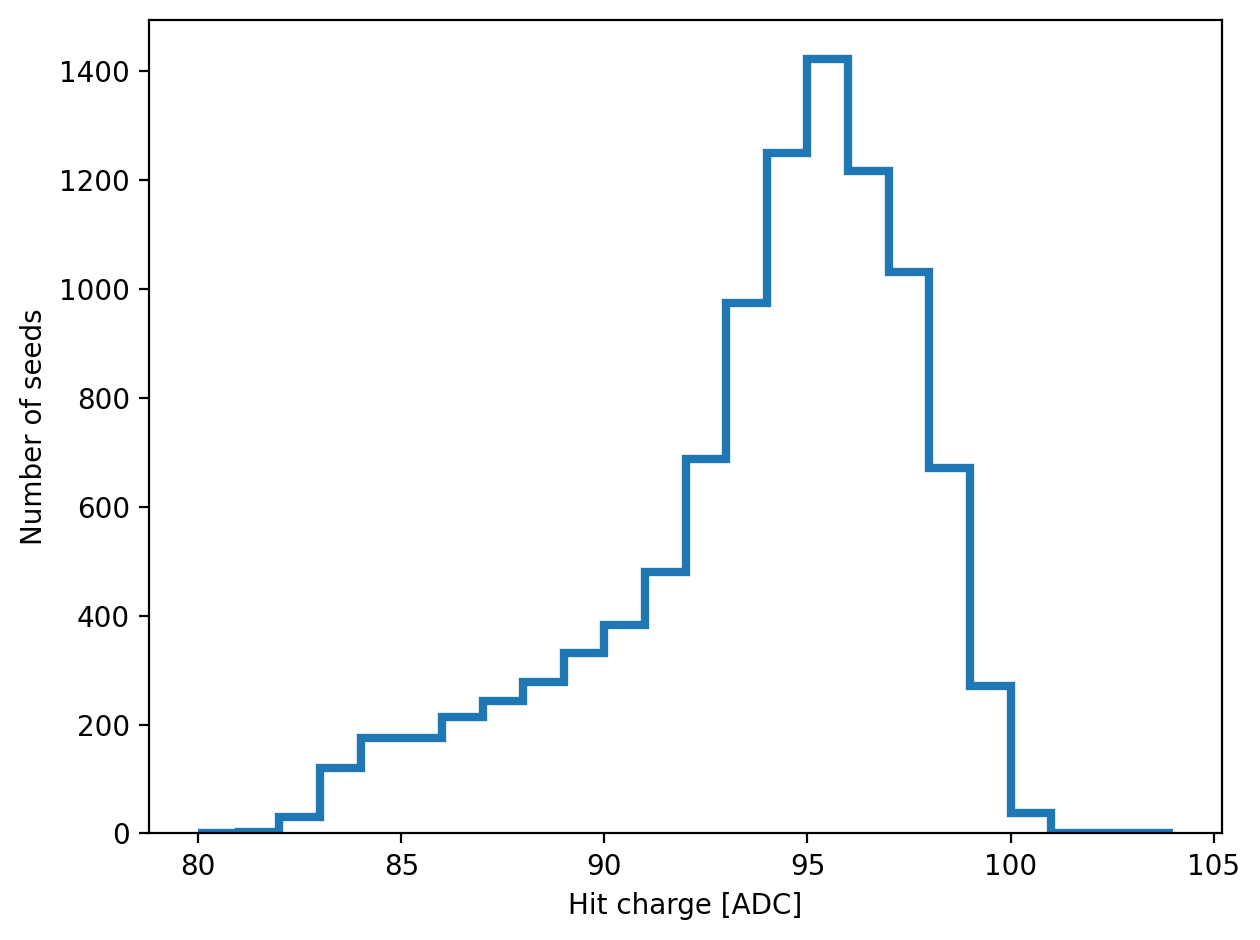

In [2]:
mc_adcs, mc_ticks = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_thresh7000.h5")
gain = 4e-3
v_pedestal = 580
v_ref = 1300
v_cm = 288
adc_counts = 2**8
dig_adcs = jnp.minimum((jnp.maximum((mc_adcs*gain+v_pedestal - v_cm), 0) * adc_counts/(v_ref-v_cm)), adc_counts)
plt.hist(dig_adcs[:, 560, 0], bins=np.arange(80, 105), histtype='step', linewidth=3)
plt.xlabel("Hit charge [ADC]")
plt.ylabel("Number of seeds")
plt.tight_layout()

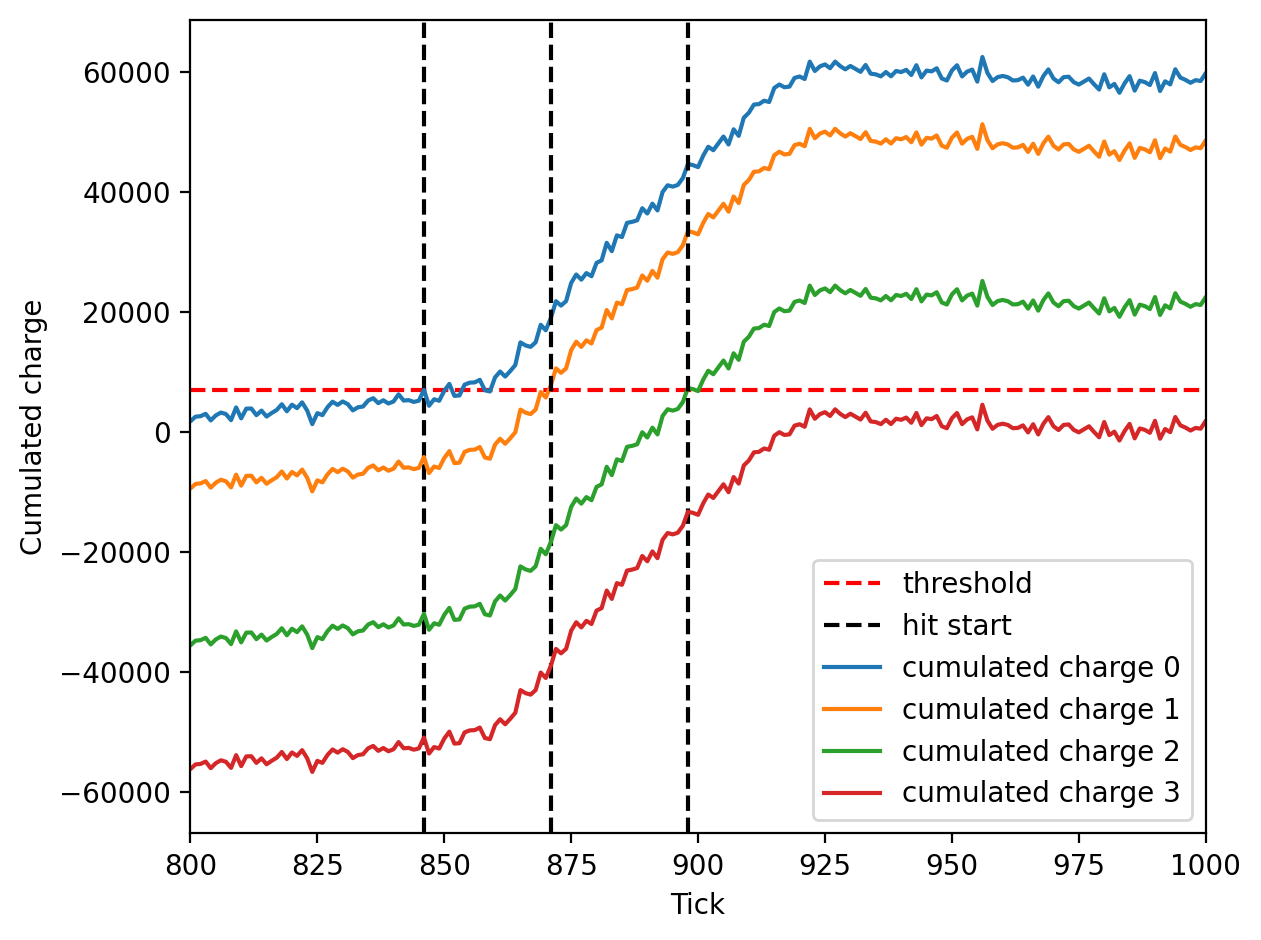

In [43]:
pixid = 560
# adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100)

noisy_wf = np.cumsum(wfs[pixid, :])*0.1
noisy_wf += np.random.normal(0, 900, len(noisy_wf))

plt.axhline(th, linestyle='--', color='red', label='threshold')

trig0 = np.argwhere(noisy_wf - th > 0)[0][0]
plt.axvline(trig0, color='k', linestyle='dashed', label="hit start")
# plt.axvline(trig0 + 18, color='g', linestyle='dashed', label="hit end")
plt.plot(noisy_wf, label="cumulated charge 0")
noisy_wf -= noisy_wf[trig0 + 18]

plt.plot(noisy_wf, label="cumulated charge 1")
trig1 = np.argwhere(noisy_wf - th > 0)[0][0]
plt.axvline(trig1, color='k', linestyle='dashed')
# plt.axvline(trig1 + 18, color='g', linestyle='dashed')
noisy_wf -= noisy_wf[trig1 + 18]
plt.plot(noisy_wf, label="cumulated charge 2")
trig1 = np.argwhere(noisy_wf - th > 0)[0][0]
plt.axvline(trig1, color='k', linestyle='dashed')
# plt.axvline(trig1 + 18, color='g', linestyle='dashed')
noisy_wf -= noisy_wf[trig1 + 18]
plt.plot(noisy_wf, label="cumulated charge 3")

plt.xlim(800, 1000)
# plt.ylim(0, 14000)
plt.legend()
plt.xlabel("Tick")
plt.ylabel("Cumulated charge")
plt.tight_layout()
# plt.twinx()
# for hitid in range(3):
#     plt.hist(mc_ticks[:, pixid, hitid], bins=np.arange(0, 2000), histtype='step', density=True);
    # plt.plot(prob_distrib[:, pixid, hitid])
# plt.ylim(0, 0.01)

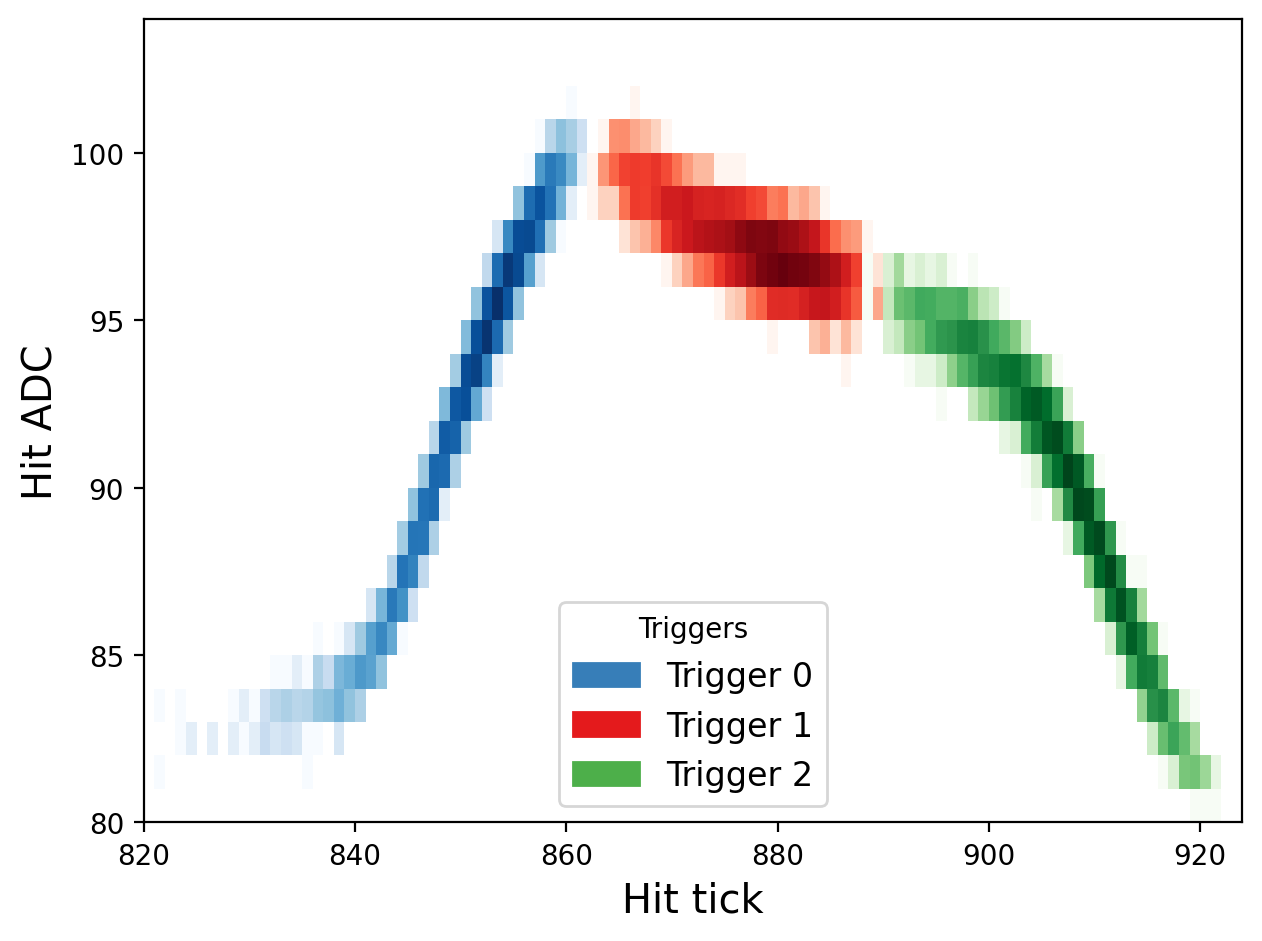

In [6]:
import matplotlib.patches as mpatches # Import the patches module
ihit = 560
plt.figure()
plt.hist2d(mc_ticks[:, ihit, 0], dig_adcs[:, ihit, 0], bins=(np.arange(820, 925), np.arange(80, 105)), cmap='Blues', vmin=1, norm='log', label="Trigger 0");
plt.hist2d(mc_ticks[:, ihit, 1], dig_adcs[:, ihit, 1], bins=(np.arange(820, 925), np.arange(80, 105)), cmap='Reds', vmin=1, norm='log', label="Trigger 1");
plt.hist2d(mc_ticks[:, ihit, 2], dig_adcs[:, ihit, 2], bins=(np.arange(820, 925), np.arange(80, 105)), cmap='Greens', vmin=1, norm='log', label="Trigger 1");

plt.xlabel("Hit tick", fontsize='x-large')
plt.ylabel("Hit ADC", fontsize='x-large')

blue_patch = mpatches.Patch(color='#377eb8', label='Trigger 0') # Using a distinct blue
red_patch = mpatches.Patch(color='#e41a1c', label='Trigger 1')   # Using a distinct red
green_patch = mpatches.Patch(color='#4daf4a', label='Trigger 2') # Using a distinct green

# 2. Add the legend to the plot using the 'handles' argument
plt.legend(handles=[blue_patch, red_patch, green_patch], fontsize='large', title='Triggers', loc="lower center")
plt.tight_layout()

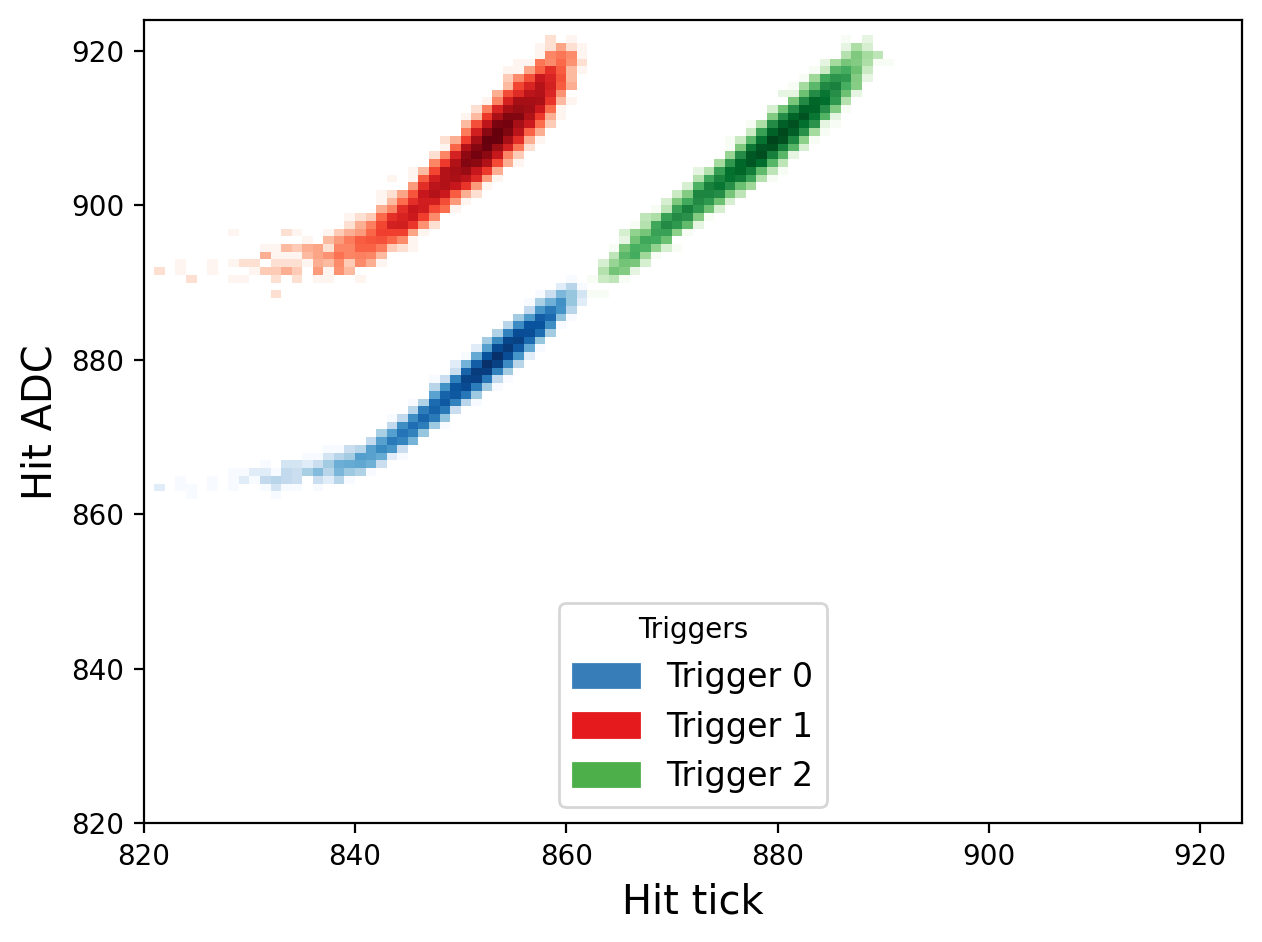

In [6]:
import matplotlib.patches as mpatches # Import the patches module
ihit = 560
plt.figure()
mat1, _, _, _ = plt.hist2d(mc_ticks[:, ihit, 0], mc_ticks[:, ihit, 1], bins=(np.arange(820, 925), np.arange(820, 925)), cmap='Blues', norm='log', label="Trigger 0");

mat3, _, _, _ = plt.hist2d(mc_ticks[:, ihit, 0], mc_ticks[:, ihit, 2], bins=(np.arange(820, 925), np.arange(820, 925)), cmap='Reds', norm='log', label="Trigger 0");
mat2, _, _, _ = plt.hist2d(mc_ticks[:, ihit, 1], mc_ticks[:, ihit, 2], bins=(np.arange(820, 925), np.arange(820, 925)), cmap='Greens', norm='log', label="Trigger 0");
mat1 = mat1/np.sum(mat1)
mat2 = mat2/np.sum(mat2)
mat3 = mat3/np.sum(mat3)
plt.xlabel("Hit tick", fontsize='x-large')
plt.ylabel("Hit ADC", fontsize='x-large')

blue_patch = mpatches.Patch(color='#377eb8', label='Trigger 0') # Using a distinct blue
red_patch = mpatches.Patch(color='#e41a1c', label='Trigger 1')   # Using a distinct red
green_patch = mpatches.Patch(color='#4daf4a', label='Trigger 2') # Using a distinct green

# 2. Add the legend to the plot using the 'handles' argument
plt.legend(handles=[blue_patch, red_patch, green_patch], fontsize='large', title='Triggers', loc="lower center")
plt.tight_layout()

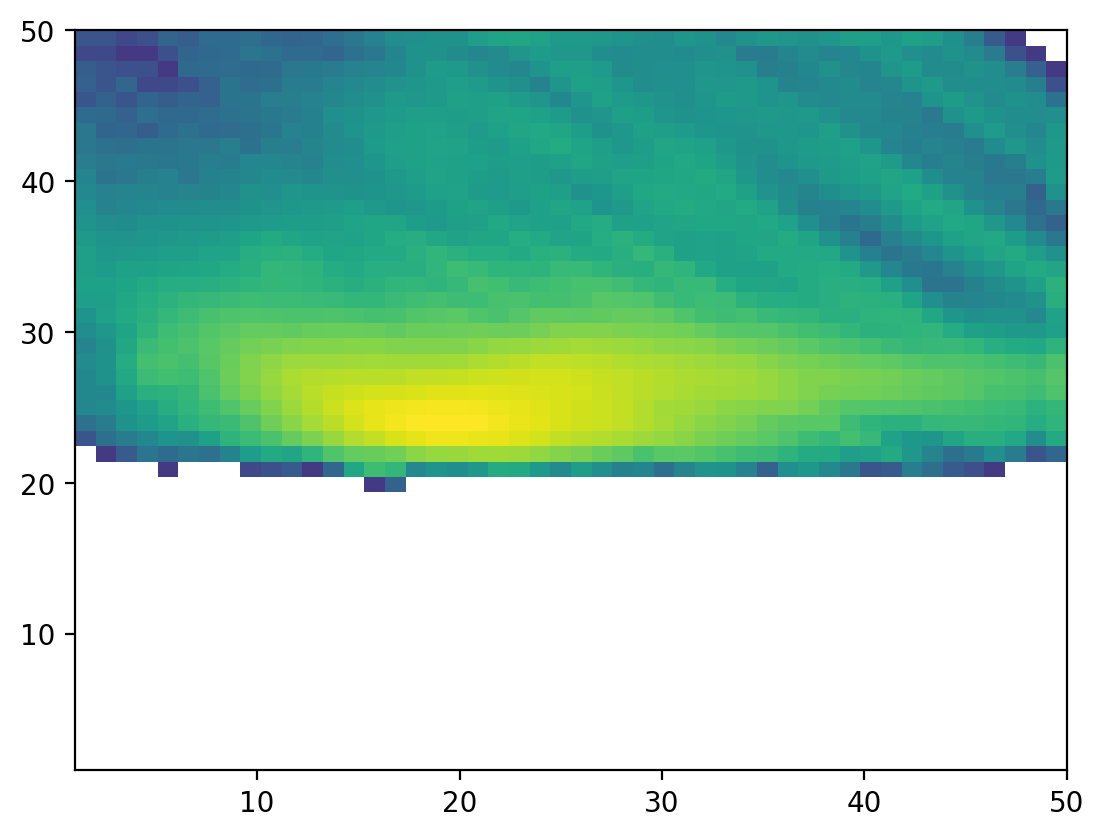

In [26]:
ihit = 560
filtered = mc_ticks[mc_ticks < 1750]
plt.hist2d((mc_ticks[:, :, 0] - jnp.min(mc_ticks[:, :, 0], axis=0)).flatten(), (mc_ticks[:, :, 1] - mc_ticks[:, :, 0]).flatten(), bins=np.linspace(1, 50, 49), vmin=0.1, norm='log');

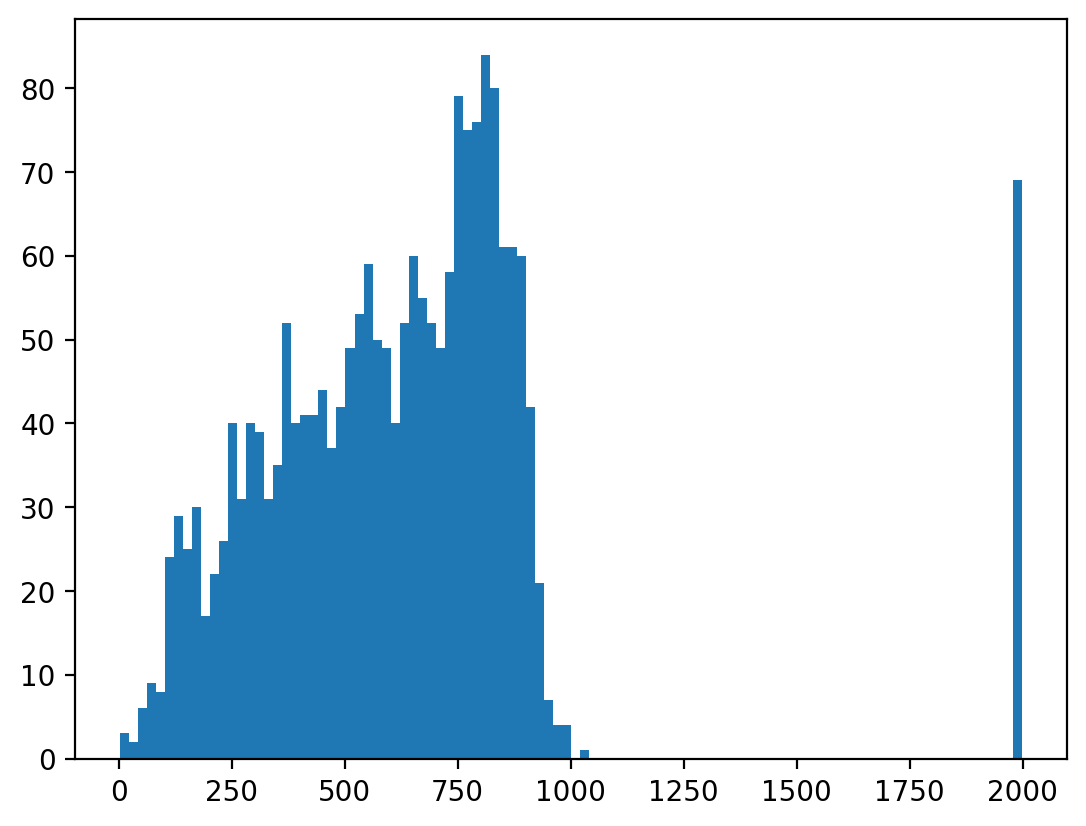

In [16]:
plt.hist(jnp.min(mc_ticks[:, :, 0], axis=0), bins=100);

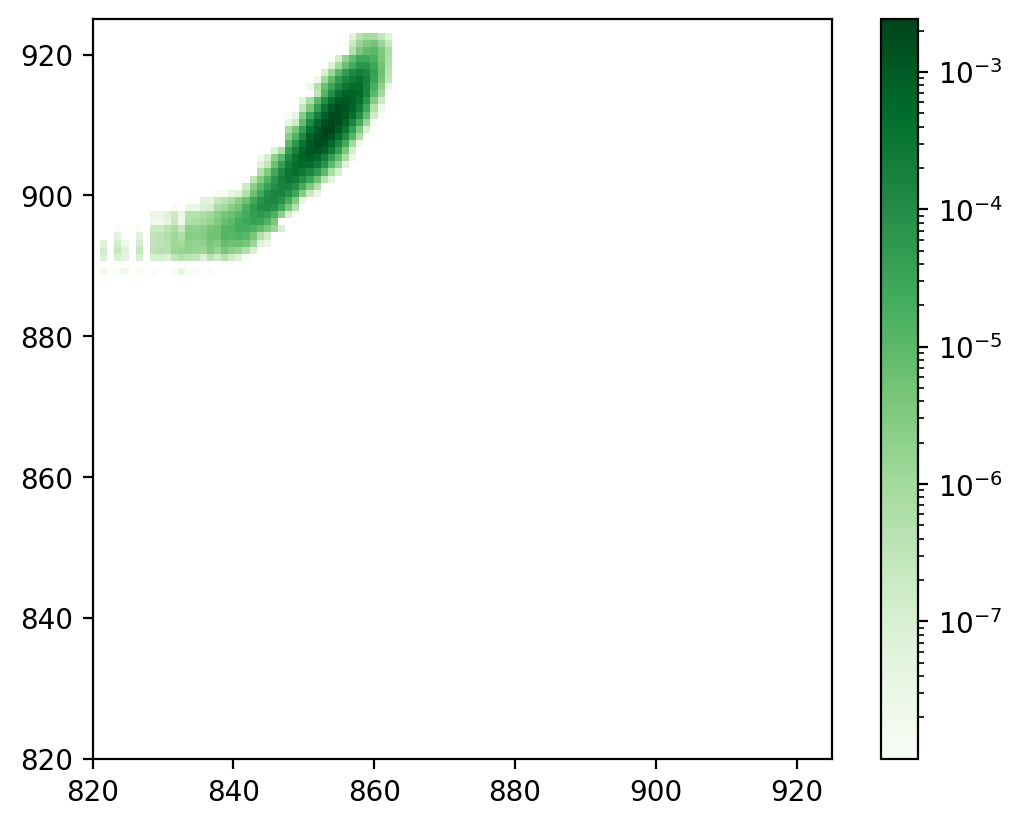

In [16]:
plt.imshow((mat1@mat2).T, origin='lower', extent=(820, 925, 820, 925), cmap='Greens', norm='log')
# plt.imshow(mat3.T, origin='lower', extent=(820, 925, 820, 925), cmap='Reds', norm='log')
plt.colorbar()

In [33]:
def get_adc_values_average_noise_local_old(wfs, sigma=900, threshold=7000, Nvalues_scaling=20):
    q = wfs*0.1
    q_sum = q.cumsum(axis=-1)  # Cumulative sum over time ticks

    Npix = wfs.shape[0]
    Nvalues = Nvalues_scaling*Npix

    def find_hit(carry, _):
        #TODO: Maybe consider removing the -1 pixel to avoid it using too many weights
        q_sum_loc, previous_prob, pixid = carry # q_sum_loc[Nvalues, Nticks] ; previous_prob[Nvalues] ; pixid[Nvalues]

        eps = 1e-10

        _, Nticks = q_sum_loc.shape

        erf_term = erf((q_sum_loc - threshold)/(jnp.sqrt(2)*sigma)) # erf_term[Nvalues, Nticks]

        erf_term_signal = lax.cummax(erf_term, axis=1)  # erf_term_signal[Nvalues, Nticks]
        max_future_signal = lax.cummax(q_sum_loc, axis=1, reverse=True)  # max_future_signal[Nvalues, Nticks]
        
        guess = 0.5*(erf_term_signal[..., 1:] - erf_term_signal[..., :-1]) # guess[Nvalues, Nticks - 1]
        # guess = jnp.clip(guess, 0, 1)  # Ensure guess is between 0 and 1, should not be needed but erf got odd behavior for some reason

        interval = 18
        shifted_ticks = jnp.arange(Nticks - 1) + interval + 1 # shifted_ticks[Nticks - 1]
        shifted_ticks = jnp.clip(shifted_ticks, 0, Nticks - 1)

        prob_event = jnp.clip(0.5*(erf_term[..., shifted_ticks] - erf_term[..., :-1]), 0, guess)

        esperance_value = q_sum_loc[..., shifted_ticks] + threshold - 0.5*(q_sum_loc[..., 1:] + q_sum_loc[..., :-1]) # esperance_value[Nvalues, Nticks - 1]

        norm = jnp.clip(jnp.sum(prob_event, axis=-1) + eps, 0, 1)  # Adding a small epsilon to avoid division by zero ; norm[Nvalues]

        previous_prob_norm = jnp.full(Npix, eps, dtype=jnp.float32)  # Avoid division by zero
        previous_prob_norm = previous_prob_norm.at[pixid].add(previous_prob)

        no_hit_prob_across = jnp.ones(Npix, dtype=jnp.float32)  # Initialize no-hit probability across universes
        no_hit_prob_across = no_hit_prob_across.at[pixid].subtract(norm*previous_prob)  # No-hit probability across universes

        prob_distrib = prob_event*previous_prob[:, None] # prob_distrib[Nvalues, Nticks - 1]

        prob_distrib_across = jnp.zeros((Npix, Nticks - 1), dtype=jnp.float32)  # Initialize probability distribution across universes
        prob_distrib_across = prob_distrib_across.at[pixid].add(prob_distrib)  # prob_distrib_across[Npix, Nticks - 1]

        norm_across = jnp.sum(prob_distrib_across, axis=-1)  # Normalize across universes ; norm_across[Npix]

        tick_avg = jnp.sum(prob_distrib_across/(norm_across[:, None])*jnp.arange(Nticks - 1), axis=-1)  # + 0.5

        charge_avg = jnp.sum(prob_event*esperance_value, axis=-1) # charge_avg[Nvalues]

        charge_avg_across = jnp.zeros((Npix,), dtype=jnp.float32)  # Initialize average charge across universes
        charge_avg_across = charge_avg_across.at[pixid].add(charge_avg*previous_prob)/norm_across  # charge_avg_across[Npix]

        future_hit_earliest_end = jnp.clip(shifted_ticks + interval + 1, 0, Nticks - 1) #We shift again
        future_hit_prob = 0.5*(1 + erf((max_future_signal[:, future_hit_earliest_end] - q_sum_loc[:, jnp.clip(shifted_ticks + 1, 0, Nticks - 1)] - threshold)/(jnp.sqrt(2)*sigma)))
        best_paths = jnp.argsort(prob_distrib*future_hit_prob, axis=None, descending=True)[:Nvalues] # best_paths[Nvalues]
        fraction_ignored = jnp.sum(jnp.sort(prob_distrib*future_hit_prob, axis=None, descending=True)[Nvalues:])/jnp.sum(prob_distrib*future_hit_prob)*100
        
        jax.debug.print("Fraction discarded: {a}%", a=fraction_ignored)
        best_path_universe = best_paths // (Nticks - 1)
        best_path_ticks = best_paths % (Nticks - 1)
        best_path_pixid = pixid[best_path_universe]  # best_path_pixid[Nvalues]

        best_path_next_ticks = jnp.clip(shifted_ticks + 1, 0, Nticks - 1) # best_path_next_ticks[Nticks - 1]
        best_path_esperance = q_sum_loc[best_path_universe, best_path_next_ticks[best_path_ticks]]  # best_path_esperance[Nvalues]
        best_path_wfs = q_sum_loc[best_path_universe, :]
        q_sum_new = best_path_wfs - best_path_esperance[..., None]
        # q_sum_new = jnp.clip(q_sum_new, 0, None)  # Ensure no negative values
        new_prob = prob_distrib[best_path_universe, best_path_ticks] # new_prob[Nvalues]
        return (q_sum_new, new_prob, best_path_pixid), (charge_avg_across, tick_avg, no_hit_prob_across, prob_distrib_across)
    
    q_sum_multi = jnp.zeros((Nvalues, q_sum.shape[1]), dtype=jnp.float32)  # Initialize q_sum for multiple universes
    q_sum_multi = q_sum_multi.at[:q_sum.shape[0], :].set(q_sum)
    previous_prob = jnp.zeros(Nvalues, dtype=jnp.float32)  # Initialize previous probability
    previous_prob = previous_prob.at[:q_sum.shape[0]].set(1.0)  # Set the first universe probability to 1.0
    pixid = jnp.full((Nvalues,), -1, dtype=jnp.int32)  # Initialize pixel IDs for multiple universes
    pixid = pixid.at[:q_sum.shape[0]].set(jnp.arange(q_sum.shape[0]))  # Set pixel IDs for the first universe

    init_loop = (q_sum_multi, previous_prob, pixid)  # Initialize previous_prob
    _, (charge_avg, tick_avg, no_hit_prob, prob_distrib) = lax.scan(find_hit, init_loop, jnp.arange(0, 5))

    return (charge_avg.T, tick_avg.T, no_hit_prob.T, prob_distrib.T)

In [7]:



@partial(jit, static_argnames=['Nvalues_scaling'])
def get_adc_values_average_noise_local(wfs, sigma=900, threshold=7000, Nvalues_scaling=20):
    """
    Estimates hit probability distributions using a high-performance beam search.
    This version uses a direct selection method for maximum performance.

    Args:
        wfs (jax.Array): Input waveforms with shape (Npix, Nticks).
        sigma (float): The standard deviation of the electronic noise.
        threshold (float): The ADC threshold for a trigger.
        Nvalues_scaling (int): A scaling factor to determine the beam width (K).

    Returns:
        A tuple containing aggregated results for each pixel.
    """
    # --- Initialization --
    q = wfs * 0.1
    q_sum = q.cumsum(axis=-1)
    Npix, Nticks = wfs.shape
    Nvalues = Nvalues_scaling * Npix

    inv_sqrt2_sigma = 1.0 / (jnp.sqrt(2) * sigma)
    eps = 1e-10
    interval = 18

    def find_hit(carry, _):
        """A single step of the beam search algorithm, executed within lax.scan."""
        q_sum_loc, previous_prob, pixid = carry

        # --- Steps 1-2: Calculate Event Probabilities for all possible next states ---
        erf_term = erf((q_sum_loc - threshold) * inv_sqrt2_sigma)
        erf_term_signal = lax.cummax(erf_term, axis=1)
        max_future_signal = lax.cummax(q_sum_loc, axis=1, reverse=True)
        guess = 0.5 * jnp.diff(erf_term_signal, axis=-1)

        shifted_ticks = jnp.arange(Nticks - 1) + interval + 1
        shifted_ticks = jnp.clip(shifted_ticks, 0, Nticks - 1)
        prob_event = jnp.clip(0.5 * (erf_term[..., shifted_ticks] - erf_term[..., :-1]), 0, guess)
        esperance_value = q_sum_loc[..., shifted_ticks] + threshold - 0.5 * (q_sum_loc[..., 1:] + q_sum_loc[..., :-1])

        # --- 3. Aggregate Results for This Step's Output ---
        prob_distrib = prob_event * previous_prob[:, None]
        
        # We calculate the total probability of a hit for each path, then aggregate per pixel.
        total_hit_prob_per_path = jnp.sum(prob_event, axis=-1) * previous_prob
        # segment_sum correctly ignores paths where pixid is -1.
        total_hit_prob_per_pixel = jax.ops.segment_sum(total_hit_prob_per_path, pixid, num_segments=Npix)
        no_hit_prob_across = 1.0 - total_hit_prob_per_pixel

        prob_distrib_across = jax.ops.segment_sum(prob_distrib, pixid, num_segments=Npix)
        norm_across = jnp.sum(prob_distrib_across, axis=-1)
        safe_norm_across = jnp.maximum(norm_across, eps)
        tick_avg = jnp.sum(prob_distrib_across * jnp.arange(Nticks - 1), axis=-1) / safe_norm_across
        charge_avg = jnp.sum(prob_event * esperance_value, axis=-1)
        charge_avg_across = jax.ops.segment_sum(charge_avg * previous_prob, pixid, num_segments=Npix) / safe_norm_across
        
        # --- 4. High-Performance Path Selection ---
        # Calculate the selection metric that guides the search toward globally optimal paths.
        future_hit_earliest_end = jnp.clip(shifted_ticks + interval + 1, 0, Nticks - 1)
        next_q_sum = q_sum_loc[:, jnp.clip(shifted_ticks + 1, 0, Nticks - 1)]
        future_hit_prob = 0.5 * (1 + erf((max_future_signal[:, future_hit_earliest_end] - next_q_sum - threshold) * inv_sqrt2_sigma))
        path_selection_prob = prob_distrib * future_hit_prob

        # Select the top K paths from the entire pool of possibilities.
        # This replaces a full sort with a much faster top-k selection.
        flat_probs = path_selection_prob.flatten()
        _, top_k_indices = lax.top_k(flat_probs, k=Nvalues)
        
        best_path_universe = top_k_indices // (Nticks - 1)
        best_path_ticks = top_k_indices % (Nticks - 1)
        
        # --- 5. Construct the State for the Next Iteration ---
        new_pixid = pixid[best_path_universe]
        # The probability for the new path carries over the full history.
        new_prob = prob_distrib[best_path_universe, best_path_ticks]

        # Reconstruct the new waveform based on the selected path.
        best_path_next_ticks_indices = jnp.clip(shifted_ticks[best_path_ticks] + 1, 0, Nticks - 1)
        best_path_esperance = q_sum_loc[best_path_universe, best_path_next_ticks_indices]
        best_path_wfs = q_sum_loc[best_path_universe, :]
        q_sum_new = best_path_wfs - best_path_esperance[..., None]
        
        # --- 6. Prepare and Return Outputs ---
        next_carry = (q_sum_new, new_prob, new_pixid)
        scan_outputs = (charge_avg_across, tick_avg, no_hit_prob_across, prob_distrib_across)
        
        return next_carry, scan_outputs

    # --- Setup and Execute the Scan ---
    q_sum_multi = jnp.zeros((Nvalues, q_sum.shape[1]), dtype=jnp.float32).at[:Npix].set(q_sum)
    previous_prob = jnp.zeros(Nvalues, dtype=jnp.float32).at[:Npix].set(1.0)
    pixid = jnp.full((Nvalues,), -1, dtype=jnp.int32).at[:Npix].set(jnp.arange(Npix))

    init_loop = (q_sum_multi, previous_prob, pixid)
    _, (charge_avg, tick_avg, no_hit_prob, prob_distrib) = lax.scan(find_hit, init_loop, jnp.arange(0, 5))

    return (charge_avg.T, tick_avg.T, no_hit_prob.T, prob_distrib.T)

In [4]:
@partial(jax.jit, static_argnums=(3, 4))
def get_adc_values_average_noise_test(wfs, sigma=900, threshold=7000, Nvalues_scaling=20, preselection_factor=10):
    """
    Estimates hit probability distributions using a high-performance beam search
    with a two-stage selection and path merging strategy for improved performance.

    Args:
        wfs (jax.Array): Input waveforms with shape (Npix, Nticks).
        sigma (float): The standard deviation of the electronic noise.
        threshold (float): The ADC threshold for a trigger.
        Nvalues_scaling (int): A scaling factor to determine the beam width (K).
        preselection_factor (int): A factor to determine the size of the pre-selection
                                   pool (K * preselection_factor) before merging.

    Returns:
        A tuple containing aggregated results for each pixel.
    """
    # --- Initialization ---
    q = wfs * 0.1
    q_sum = q.cumsum(axis=-1)
    Npix, Nticks = wfs.shape
    Nvalues = Nvalues_scaling * Npix
    preselection_size = Nvalues * preselection_factor

    inv_sqrt2_sigma = 1.0 / (jnp.sqrt(2) * sigma)
    eps = 1e-10
    interval = 18

    def find_hit(carry, _):
        """A single step of the beam search algorithm, executed within lax.scan."""
        q_sum_loc, previous_prob, pixid = carry

        # --- Steps 1-2: Calculate Event Probabilities for all possible next states ---
        erf_term = erf((q_sum_loc - threshold) * inv_sqrt2_sigma)
        erf_term_signal = lax.cummax(erf_term, axis=1)
        max_future_signal = lax.cummax(q_sum_loc, axis=1, reverse=True)
        guess = 0.5 * jnp.diff(erf_term_signal, axis=-1)

        shifted_ticks = jnp.arange(Nticks - 1) + interval + 1
        shifted_ticks = jnp.clip(shifted_ticks, 0, Nticks - 1)
        prob_event = jnp.clip(0.5 * (erf_term[..., shifted_ticks] - erf_term[..., :-1]), 0, guess)
        esperance_value = q_sum_loc[..., shifted_ticks] + threshold - 0.5 * (q_sum_loc[..., 1:] + q_sum_loc[..., :-1])

        # --- 3. Aggregate Results for This Step's Output (based on pre-selection state) ---
        prob_distrib = prob_event * previous_prob[:, None]
        norm = jnp.sum(prob_event, axis=-1)
        no_hit_prob_across = jnp.ones(Npix, dtype=jnp.float32)
        no_hit_prob_across = no_hit_prob_across.at[pixid].add(-norm * previous_prob)
        prob_distrib_across = jax.ops.segment_sum(prob_distrib, pixid, num_segments=Npix)
        norm_across = jnp.sum(prob_distrib_across, axis=-1)
        safe_norm_across = jnp.maximum(norm_across, eps)
        tick_avg = jnp.sum(prob_distrib_across * jnp.arange(Nticks - 1), axis=-1) / safe_norm_across
        charge_avg = jnp.sum(prob_event * esperance_value, axis=-1)
        charge_avg_across = jax.ops.segment_sum(charge_avg * previous_prob, pixid, num_segments=Npix) / safe_norm_across
        
        # --- 4. High-Performance Merging with Two-Stage Selection ---
        # Calculate the selection metric for all possible next steps.
        future_hit_earliest_end = jnp.clip(shifted_ticks + interval + 1, 0, Nticks - 1)
        next_q_sum = q_sum_loc[:, jnp.clip(shifted_ticks + 1, 0, Nticks - 1)]
        future_hit_prob = 0.5 * (1 + erf((max_future_signal[:, future_hit_earliest_end] - next_q_sum - threshold) * inv_sqrt2_sigma))
        path_selection_prob = prob_distrib * future_hit_prob

        # STAGE 1: Pre-select the top K*preselection best candidates from the entire pool of possibilities.
        flat_selection_prob = path_selection_prob.flatten()
        _, preselection_indices = lax.top_k(flat_selection_prob, k=preselection_size)

        test1, test2 = lax.top_k(flat_selection_prob, k=Nvalues)

        # jax.debug.print("Total probability without merge: {a}", a=jnp.sum(test1))
        
        # Gather only the data for these top candidates, creating a much smaller pool.
        flat_prob_distrib = prob_distrib.flatten()
        candidate_selection_probs = flat_selection_prob[preselection_indices]
        candidate_distrib_probs = flat_prob_distrib[preselection_indices]
        
        next_state_ids_full = (pixid[:, None] * Nticks + jnp.arange(Nticks - 1)).flatten()
        candidate_state_ids = next_state_ids_full[preselection_indices]
        
        # STAGE 2: Merge the smaller candidate pool.
        unique_states, representative_indices, inverse_indices = jnp.unique(
            candidate_state_ids, return_index=True, return_inverse=True, size=preselection_size, fill_value=-1
        )

        # jax.debug.print("Fraction of repeating indices: {a}", a=jnp.sum(unique_states == -1)/preselection_size)
        
        merged_selection_prob = jax.ops.segment_sum(candidate_selection_probs, inverse_indices, num_segments=preselection_size)
        merged_distrib_prob = jax.ops.segment_sum(candidate_distrib_probs, inverse_indices, num_segments=preselection_size)

        # STAGE 3: Select the final top K paths from the merged pool.
        _, top_k_indices = lax.top_k(merged_selection_prob, k=Nvalues)
        
        # --- 5. Construct the State for the Next Iteration ---
        # Map the final selections back to their original paths to reconstruct the state.
        winning_rep_candidate_indices = representative_indices[top_k_indices]
        winning_rep_flat_indices = preselection_indices[winning_rep_candidate_indices]
        valid_mask = winning_rep_candidate_indices != -1

        new_prob = jnp.where(valid_mask, merged_distrib_prob[top_k_indices], 0.0)
        new_pixid = jnp.where(valid_mask, unique_states[top_k_indices] // Nticks, -1)

        # jax.debug.print("Total probability after cut: {a}", a=jnp.sum(new_prob))

        best_path_universe = jnp.where(valid_mask, winning_rep_flat_indices // (Nticks - 1), 0)
        best_path_ticks = jnp.where(valid_mask, winning_rep_flat_indices % (Nticks - 1), 0)
        
        representative_q_sum_loc = q_sum_loc[best_path_universe, :]
        next_ticks_indices = jnp.clip(shifted_ticks[best_path_ticks] + 1, 0, Nticks - 1)
        esperance = representative_q_sum_loc[jnp.arange(Nvalues), next_ticks_indices]
        unique_q_sum_new = representative_q_sum_loc - esperance[:, None]
        
        q_sum_new = jnp.where(valid_mask[:, None], unique_q_sum_new, 0.0)

        # --- 6. Prepare and Return Outputs ---
        next_carry = (q_sum_new, new_prob, new_pixid)
        scan_outputs = (charge_avg_across, tick_avg, no_hit_prob_across, prob_distrib_across)
        
        return next_carry, scan_outputs

    # --- Setup and Execute the Scan ---
    q_sum_multi = jnp.zeros((Nvalues, q_sum.shape[1]), dtype=jnp.float32).at[:Npix].set(q_sum)
    previous_prob = jnp.zeros(Nvalues, dtype=jnp.float32).at[:Npix].set(1.0)
    pixid = jnp.full((Nvalues,), -1, dtype=jnp.int32).at[:Npix].set(jnp.arange(Npix))

    init_loop = (q_sum_multi, previous_prob, pixid)
    _, (charge_avg, tick_avg, no_hit_prob, prob_distrib) = lax.scan(find_hit, init_loop, jnp.arange(0, 10))

    return (charge_avg.T, tick_avg.T, no_hit_prob.T, prob_distrib.T)

NameError: name 'estimate_distrib' is not defined

In [302]:
mc_tick_avg.shape

(2064, 10)

In [21]:
import time 

# Helper function to make the output readable
def format_bytes(size_bytes):
    if size_bytes < 1024:
        return f"{size_bytes} B"
    elif size_bytes < 1024**2:
        return f"{size_bytes/1024:.2f} KB"
    elif size_bytes < 1024**3:
        return f"{size_bytes/1024**2:.2f} MB"
    else:
        return f"{size_bytes/1024**3:.2f} GB"

device = jax.devices()[0]
start = time.time()

# --- Moment 1: Clear the stats ---
print("Clearing memory stats...")
jnp.zeros(1).block_until_ready()
initial_stats = device.memory_stats()
initial_peak = initial_stats['peak_bytes_in_use']

# --- Run the code you want to profile ---
print("Running function...")
a, b, c, d = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100)
# a, b, c, d = get_adc_values_average_noise_vmap(wfs, threshold=th, Nvalues_scaling=100)
a.block_until_ready() # CRITICAL: Wait for JAX to finish
print("Function finished.")

# --- Moment 2: Get final peak memory ---
final_stats = device.memory_stats()
final_peak = final_stats['peak_bytes_in_use']

# --- Calculate the difference ---
peak_usage_by_function = final_peak - initial_peak

print(f"\n--- Results ---")
print(f"Final peak memory:     {format_bytes(final_peak)}")
print(f"Peak memory used by function: {format_bytes(peak_usage_by_function)}")

# for i in range(10):
#     a, b, c, d = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100)
#     print(c[0][0])
# stop = time.time()

# print("Duration:", stop - start)

Clearing memory stats...
Running function...


Function finished.

--- Results ---
Final peak memory:     13.55 GB
Peak memory used by function: 315.41 MB


In [ ]:
from jax import vmap, checkpoint

def _find_one_hit_step(q_sum, prev_charges, previous_prob, sigma, threshold, interval, Nvalues):
    """
    Calculates a single hit-finding step for one pixel. This function is designed
    to be vmapped across all pixels.
    """
    # This function contains the logic from the previous `_active_branch`.
    Nticks = q_sum.shape[0]
    inv_sqrt2_sigma = 1.0 / (jnp.sqrt(2) * sigma)
    shifted_ticks = jnp.arange(Nticks - 1) + interval + 1
    shifted_ticks = jnp.clip(shifted_ticks, 0, Nticks - 1)
    tick_indices = jnp.arange(Nticks - 1)

    q_sum_loc = q_sum - prev_charges[..., None]

    # Steps 1-2: Calculate Event Probabilities
    erf_term = erf((q_sum_loc - threshold) * inv_sqrt2_sigma)
    erf_term_signal = lax.cummax(erf_term, axis=1)
    max_future_signal = lax.cummax(q_sum_loc, axis=1, reverse=True)
    guess = 0.5 * jnp.diff(erf_term_signal, axis=-1)
    prob_event = jnp.clip(0.5 * (erf_term[..., shifted_ticks] - erf_term[..., :-1]), 0, guess)
    # esperance_value = q_sum_loc[..., shifted_ticks] + threshold - 0.5 * (q_sum_loc[..., 1:] + q_sum_loc[..., :-1])
    esperance_value = q_sum[..., shifted_ticks] + threshold - 0.5 * (q_sum[..., 1:] + q_sum[..., :-1])

    # Step 3: Aggregate Results
    prob_distrib = prob_event * previous_prob[:, None]
    total_distrib_prob_per_tick = jnp.sum(prob_distrib, axis=0)
    norm_across = jnp.sum(total_distrib_prob_per_tick)
    no_hit_prob = 1.0 - norm_across
    safe_norm_across = jnp.maximum(norm_across, 1e-9)
    
    tick_avg = jnp.sum(total_distrib_prob_per_tick * tick_indices) / safe_norm_across
    
    charge_avg_paths = jnp.sum(prob_event * esperance_value, axis=-1)
    charge_avg = jnp.sum(charge_avg_paths * previous_prob) / safe_norm_across
    
    # Step 4: Optimized Merging & Selection
    future_hit_earliest_end = jnp.clip(shifted_ticks + interval + 1, 0, Nticks - 1)
    next_q_sum = q_sum_loc[:, jnp.clip(shifted_ticks + 1, 0, Nticks - 1)]
    future_hit_prob = 0.5 * (1 + erf((max_future_signal[:, future_hit_earliest_end] - next_q_sum - threshold) * inv_sqrt2_sigma))
    path_selection_prob = prob_distrib * future_hit_prob
    total_prob_per_tick = jnp.sum(path_selection_prob, axis=0)
   
    
    # Step 5: Construct the State for the Next Iteration
    _, top_k_ticks = lax.top_k(total_prob_per_tick, k=Nvalues)
    new_prob = total_distrib_prob_per_tick[top_k_ticks]
    best_path_next_ticks_indices = jnp.clip(shifted_ticks[top_k_ticks] + 1, 0, Nticks - 1)
    charges_new = q_sum[best_path_next_ticks_indices]
    
    # Return the new state and the outputs for this step for this pixel
    return (charges_new, new_prob), (charge_avg, tick_avg, no_hit_prob, total_distrib_prob_per_tick, esperance_value)
    # return (charges_new, new_prob), (charge_avg_across, tick_avg, no_hit_prob_across, prob_distrib_across)

@partial(jit, static_argnums=(2))
def get_adc_values_average_noise_vmap(params, wfs, stop_threshold=1e-9):
    """
    A globally-stopped, vmap-based implementation of the beam search. This is a
    highly optimized pattern for parallel hardware.
    """
    Npix, Nticks = wfs.shape
    Nvalues = params.fee_paths_scaling
    interval = round((3 * params.CLOCK_CYCLE + params.ADC_HOLD_DELAY * params.CLOCK_CYCLE) / params.t_sampling)
    
    # --- Vectorize the single-step function ---
    vmapped_step_fun = vmap(
        _find_one_hit_step,
        in_axes=(0, 0, 0, None, None, None, None) # Map over q_sum, charges, probs
    )

    # --- Pre-calculate q_sum for all pixels ---
    q = wfs * params.t_sampling
    q_sum_all = q.cumsum(axis=-1)
    

    def global_scan_fun(carry, _):
        """The main scan function with a global conditional stop."""
        prev_charges_all, prev_probs_all, is_active_global = carry

        # Apply jax.checkpoint to the expensive branch of the computation.
        # This tells JAX not to store intermediate values from this function,
        # saving memory at the cost of some re-computation.
        @checkpoint
        def _active_branch(operand):
            """The expensive vmapped computation, only run when globally active."""
            charges, probs, _ = operand
            # Run one hit-finding step for all pixels in parallel
            (new_charges, new_probs), (charge_avg, tick_avg, no_hit_prob, prob_dist, charge_dist) = vmapped_step_fun(
                q_sum_all, charges, probs, params.RESET_NOISE_CHARGE, params.DISCRIMINATION_THRESHOLD, interval, 
                Nvalues
            )
            # Check if ANY pixel is still active for the next iteration
            new_active_flag = jnp.any(jnp.sum(new_probs, axis=1) > stop_threshold)

            return (new_charges, new_probs, new_active_flag), (charge_avg, tick_avg, no_hit_prob, prob_dist, charge_dist)

        def _inactive_branch(operand):
            """A cheap pass-through, executed when the whole batch is inactive."""
            return operand, (
                jnp.zeros((Npix,), dtype=jnp.float32),
                jnp.zeros((Npix,), dtype=jnp.float32),
                jnp.ones((Npix,), dtype=jnp.float32),  # Fixed: no_hit_prob should be 1.0 when inactive
                jnp.zeros((Npix, Nticks - 1), dtype=jnp.float32),
                jnp.zeros((Npix, Nticks - 1), dtype=jnp.float32),
                )

        # --- Global Conditional Execution ---
        final_carry, final_outputs = lax.cond(
            is_active_global,
            _active_branch,
            _inactive_branch,
            carry
        )
        return final_carry, final_outputs

    # --- Setup and Execute the Global Scan ---
    initial_charges = jnp.zeros((Npix, Nvalues), dtype=jnp.float32)
    initial_probs = jnp.zeros((Npix, Nvalues), dtype=jnp.float32).at[:, 0].set(1.0)
    initial_active = jnp.array(True)
    
    init_loop = (initial_charges, initial_probs, initial_active)

    _, (charge_avg, tick_avg, no_hit_prob, prob_distrib, charge_distrib) = lax.scan(global_scan_fun, init_loop, jnp.arange(0, params.MAX_ADC_VALUES))
    return jnp.moveaxis(charge_avg, 0, 1), jnp.moveaxis(tick_avg, 0, 1), jnp.moveaxis(no_hit_prob, 0, 1), jnp.moveaxis(prob_distrib, 0, 1), jnp.moveaxis(charge_distrib, 0, 1)

In [50]:
# pdist = get_adc_values_average_noise_vmap(params, wfs)

# fraction_triggered_guess = jnp.sum(pdist, axis=2)
# for ihit in range(3):
#     plt.scatter(fraction_triggered[:, ihit], fraction_triggered_guess[:, ihit], s=5)

# plt.figure()
# eps = 1e-10
# tick_avg_guess = jnp.sum(pdist*jnp.arange(-1, pdist.shape[2]-1), axis=2)/jnp.maximum(fraction_triggered_guess, eps)
# for ihit in range(3):
#     # plt.scatter(mc_tick_avg[:, ihit], tick_avg_guess[:, ihit], s=5)
#     plt.hist(mc_tick_avg[:, ihit] - tick_avg_guess[:, ihit], histtype='step', bins=np.linspace(-4, 4, 40))
# # mc_tick_avg, mc_adcs_avg

TypeError: sum requires ndarray or scalar arguments, got <class 'tuple'> at position 0.

In [35]:
jnp.mean(pdist*jnp.arange(pdist.shape[2]), axis=2).shape

(2064, 10)

In [37]:
jnp.arange(pdist.shape[2])

Array([   0,    1,    2, ..., 1997, 1998, 1999], dtype=int32)

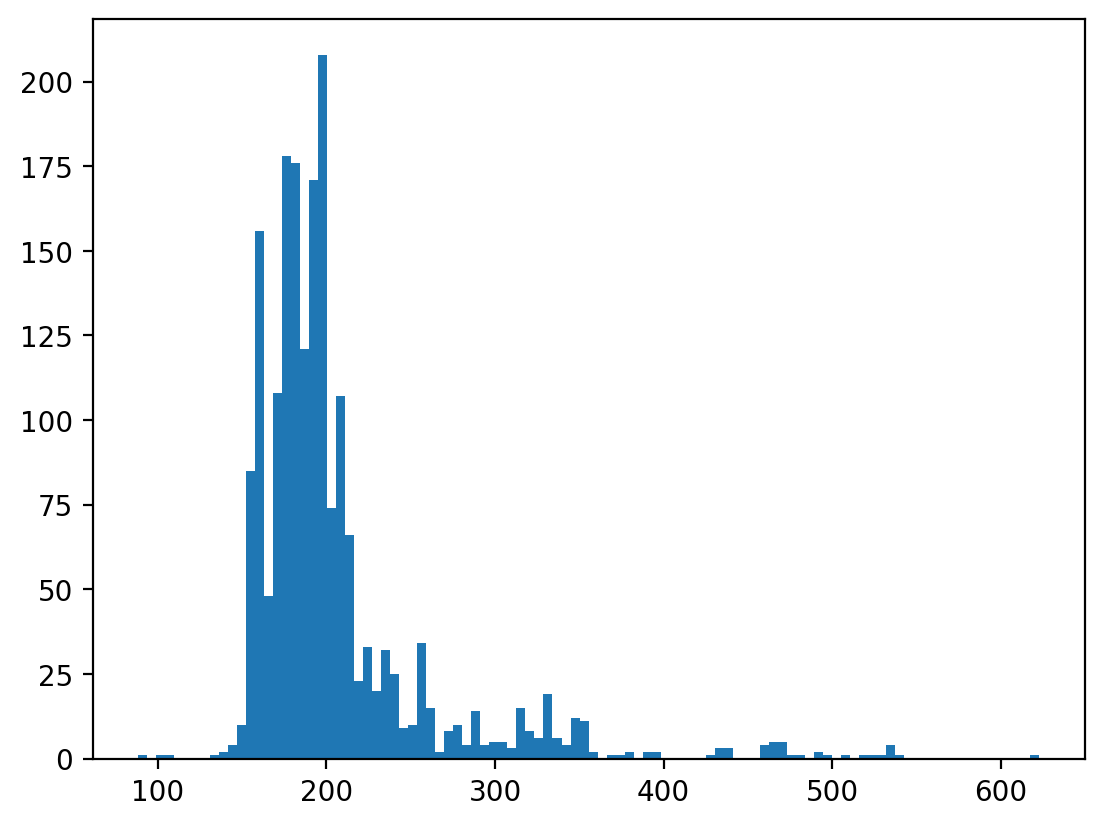

In [8]:
sigma = 900
roi_threshold = 0.0001
wfs_filtered = jnp.array(wfs)

Npix = wfs_filtered.shape[0]
Nticks = wfs_filtered.shape[1] - 1

roi_start = jnp.argmax(wfs_filtered[:, 1:] > roi_threshold, axis=1)
roi_end = wfs_filtered.shape[1] - jnp.argmax(wfs_filtered[:, :1:-1] > roi_threshold, axis=1)

with_roi = roi_start > 0

largest_roi = jnp.max((roi_end-roi_start)[with_roi])

wfs_with_roi = wfs_filtered[:, 1:].at[jnp.arange(Npix)[:, None], (jnp.arange(largest_roi) + roi_start[:, None])].get(unique_indices=True)
plt.hist((roi_end-roi_start)[with_roi], bins=100);

In [13]:
import time
start = time.time()

for i in range(10):
    adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_vmap(local_params, wfs)
    print(prob_distrib[0][0])
adcs_avg.block_until_ready()
stop = time.time()

print("Duration:", stop - start)

[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
[0. 0. 0. ... 0. 0. 0.]
Duration: 2.827268123626709


In [14]:
import time

start = time.time()

for i in range(10):
    pdist = get_adc_values_average_noise_vmap(wfs, threshold=th, Nvalues_scaling=50)
    print(pdist.shape)
    # print(c[0][0])
pdist.block_until_ready()
stop = time.time()

print("Duration:", stop - start)

(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
(2064, 10, 2000)
Duration: 1.3854985237121582


  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:12<00:00,  1.27s/it]


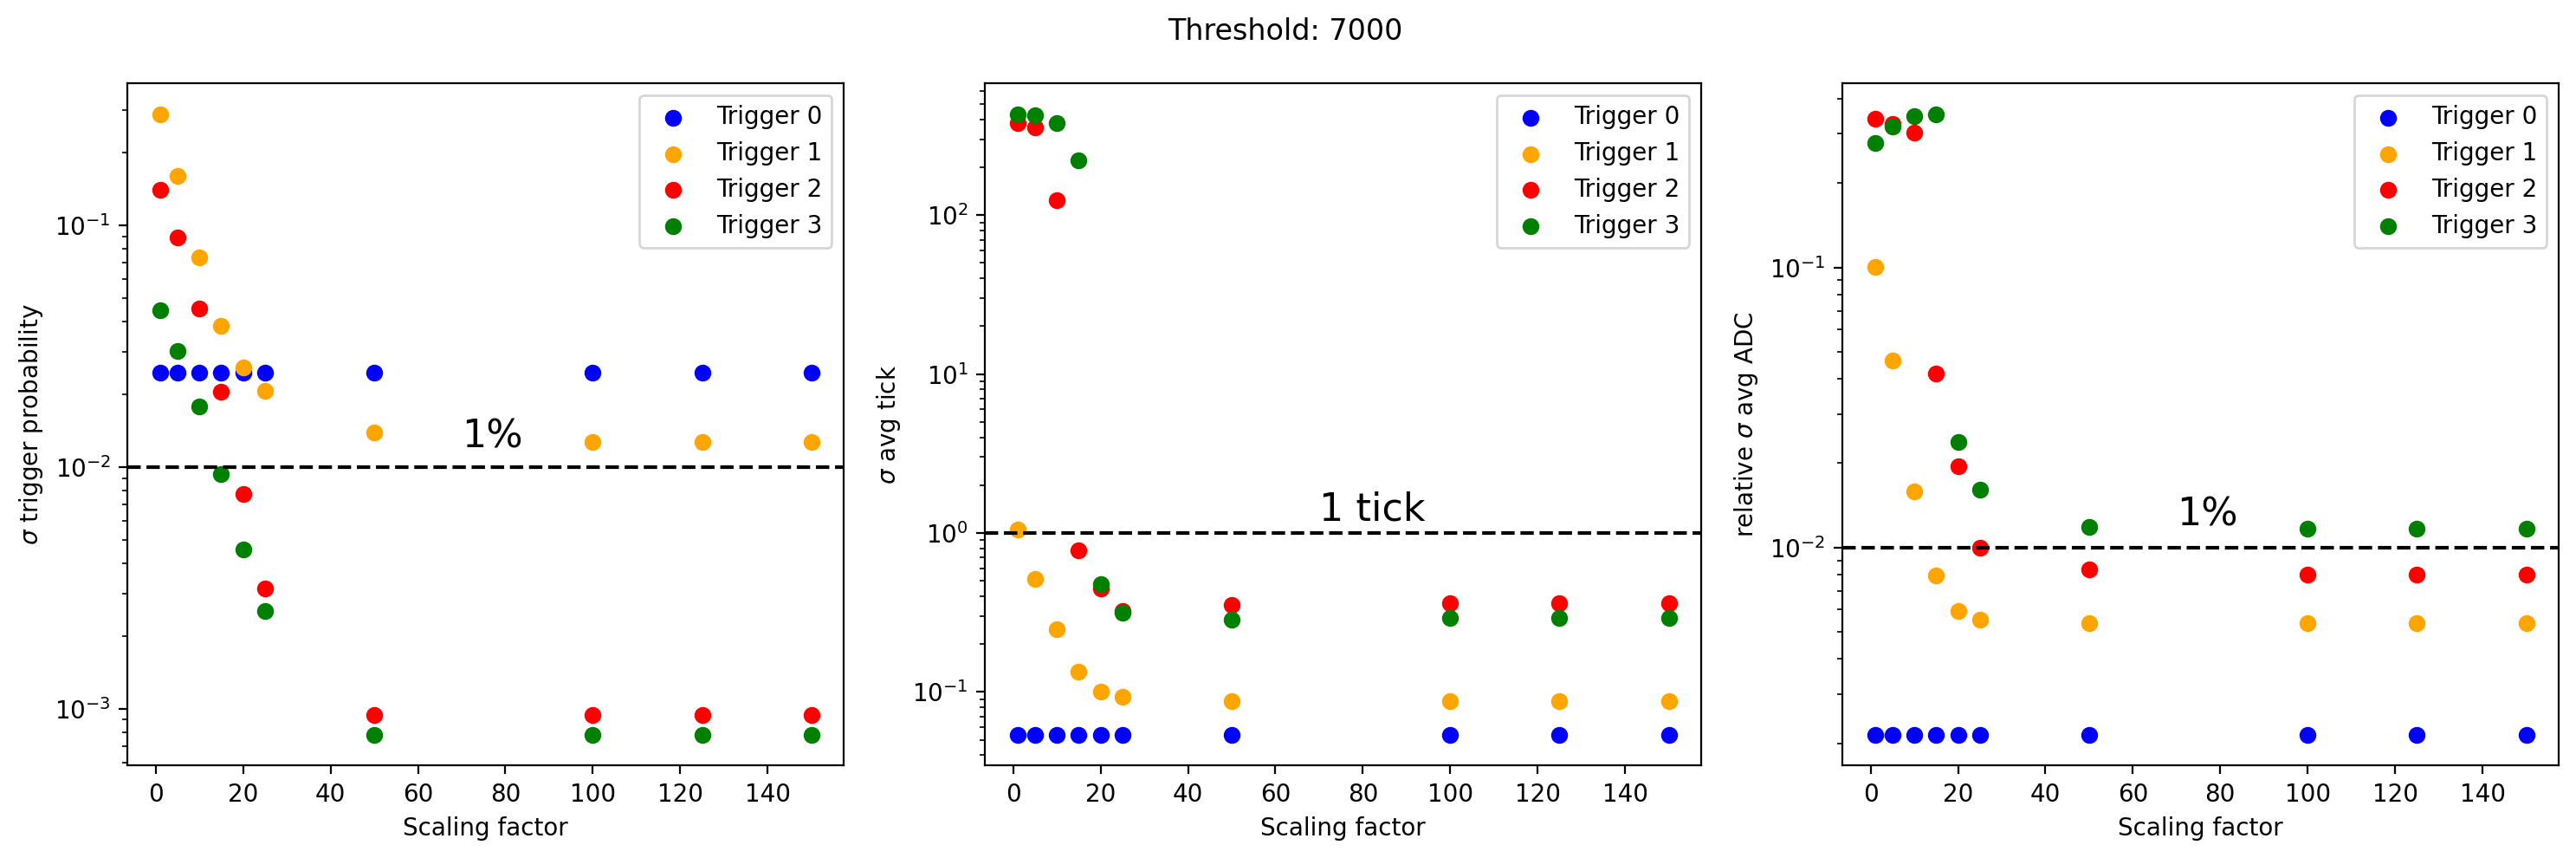

In [47]:
from tqdm import tqdm
from pprint import pprint
import matplotlib.pyplot as plt

def manual_std(data:np.ndarray, quant=np.array([0.16,0.84])) -> float:
    a, b = jnp.nanquantile(data, quant, method='linear')
    return (b - a)/2

fig, axs = plt.subplots(1, 3, figsize=(15, 5))


for n_scaling in tqdm([1, 5, 10, 15, 20, 25, 50, 100, 125, 150]):
    # adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=n_scaling, preselection_factor=30)
    local_params = params.replace(fee_paths_scaling=n_scaling, DISCRIMINATION_THRESHOLD=7000)
    adcs_avg, tick_avg, no_hit_prob, prob_distrib, _ = get_adc_values_average_noise_vmap(local_params, wfs)
    # plt.hist(1 - fraction_triggered[:, 1] - no_hit_prob[:, 1], range=(-1, 1), bins=100, histtype='step', label=n_scaling)
    for ihit, color in zip(range(4), ['blue', 'orange', 'red', 'green']):
        std =  manual_std(1 - fraction_triggered[:, ihit] - no_hit_prob[:, ihit])
        std =  jnp.std(1 - fraction_triggered[:, ihit] - no_hit_prob[:, ihit])

        label = label=f"Trigger {ihit}"
        if n_scaling != 1:
            label = None
        
        # print("std", std)
        axs[0].scatter(n_scaling,std, color=color, label=label)

        std =  manual_std(tick_avg[:, ihit] - mc_tick_avg[:, ihit] - 1)
        # std = jnp.nanstd(tick_avg[:, ihit] - mc_tick_avg[:, ihit] - 1)

        axs[1].scatter(n_scaling,std, color=color, label=label)

        std =  manual_std(mc_adcs_avg[:, ihit] - adcs_avg[:, ihit])/np.nanmean(mc_adcs_avg[:, ihit])
        axs[2].scatter(n_scaling,std, color=color, label=label)
        
        

    
    # adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_local(wfs, threshold=th, Nvalues_scaling=n_scaling)
    # for ihit, color in zip(range(4), ['blue', 'orange', 'red', 'green']):
    #     std =  manual_std(1 - fraction_triggered[:, ihit] - no_hit_prob[:, ihit])
    #     std =  jnp.std(1 - fraction_triggered[:, ihit] - no_hit_prob[:, ihit])
    #     # print("std", std)
    #     axs[0].scatter(n_scaling,std, color=color, marker='d')

    #     std =  manual_std(tick_avg[:, ihit] - mc_tick_avg[:, ihit] - 1)
    #     # std = jnp.nanstd(tick_avg[:, ihit] - mc_tick_avg[:, ihit] - 1)

    #     axs[1].scatter(n_scaling,std, color=color, marker='d')

    #     std =  manual_std(mc_adcs_avg[:, ihit] - adcs_avg[:, ihit])/np.nanmean(mc_adcs_avg[:, ihit])
    #     axs[2].scatter(n_scaling,std, color=color, marker='d')


for ax in axs:
    ax.set_yscale('log')
    ax.set_xlabel("Scaling factor")
    ax.legend()
axs[0].set_ylabel(r"$\sigma$ trigger probability")
axs[1].set_ylabel(r"$\sigma$ avg tick")
axs[2].set_ylabel(r"relative $\sigma$ avg ADC")
axs[0].axhline(0.01, linestyle='dashed', color='k')
axs[0].text(70, 0.012, r"1%", fontsize=16)

axs[1].axhline(1, linestyle='dashed', color='k')
axs[1].text(70, 1.2, r"1 tick", fontsize=16)

axs[2].axhline(0.01, linestyle='dashed', color='k')
axs[2].text(70, 0.012, r"1%", fontsize=16)

fig.suptitle(f"Threshold: {th}")
plt.tight_layout()

In [ ]:
adcs_avg, tick_avg, no_hit_prob, prob_distrib, charge_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100)

In [5]:
from larndsim.consts_jax import build_params_class, load_detector_properties
from larndsim.detsim_jax import id2pixel, get_pixel_coordinates, get_hit_z
from larndsim.sim_jax import parse_output
from larndsim.losses_jax import mse_adc, adc2charge, mse_loss, mmd
from larndsim.fee_jax import digitize

Params = build_params_class([])
params = load_detector_properties(Params, "./src/larndsim/detector_properties/module0.yaml",
                                "./src/larndsim/pixel_layouts/multi_tile_layout-2.4.16_v4.yaml")

def mse_adc(params, Q, x, y, z, ticks, hit_prob, event, ref_Q, ref_x, ref_y, ref_z, ref_ticks, ref_hit_prob, ref_event, sigma=1):
    ref_stacked = jnp.stack((ref_x + ref_event*1e5, ref_y, ref_z, ref_Q), axis=-1)
    stacked = jnp.stack((x + event*1e5, y, z, Q), axis=-1)
    return mmd(stacked, ref_stacked, hit_prob, ref_hit_prob, sigma), dict()
    # return mse_loss(adcs, pixels, ref, pixels_ref)

def loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels, sigma=1):
    adcs_mc = digitize(params, integral_mc)
    adcs = digitize(params, integral)

    pixel_x, pixel_y, pixel_plane, event = id2pixel(params, unique_pixels)
    pixel_coords = get_pixel_coordinates(params, pixel_x, pixel_y, pixel_plane)
    pixel_x = pixel_coords[:, 0]
    pixel_y = pixel_coords[:, 1]
    
    pixel_z_mc  = get_hit_z(params, ticks_mc.flatten(), jnp.repeat(pixel_plane, 10))
    pixel_z  = get_hit_z(params, ticks.flatten(), jnp.repeat(pixel_plane, 10))

    adcs_mc, pixel_x_mc, pixel_y_mc, pixel_z_mc, ticks_mc, hit_prob_mc, event_mc, unique_pixels_mc, nb_valid_mc = parse_output(params, adcs_mc, pixel_x, pixel_y, pixel_z_mc, ticks, hit_prob_mc, event, unique_pixels)
    adcs, pixel_x, pixel_y, pixel_z, ticks, hit_prob, event, unique_pixels, nb_valid = parse_output(params, adcs, pixel_x, pixel_y, pixel_z, ticks, hit_prob, event, unique_pixels)
    

    Q = adc2charge(adcs, params)
    Q_mc = adc2charge(adcs_mc, params)

    loss_val = mse_adc(params, Q[:nb_valid], pixel_x[:nb_valid], pixel_y[:nb_valid], pixel_z[:nb_valid], ticks[:nb_valid], hit_prob[:nb_valid], event[:nb_valid], Q_mc[:nb_valid_mc], pixel_x_mc[:nb_valid_mc], pixel_y_mc[:nb_valid_mc], pixel_z_mc[:nb_valid_mc], ticks_mc[:nb_valid_mc], hit_prob_mc[:nb_valid_mc], event_mc[:nb_valid_mc], sigma=sigma) 
    
    return loss_val


In [53]:
def llhd_loss(ticks_prob_distrib, ticks_mc, no_hit_prob, charge_distrib, charge_mc, sigma=500):
    """
    Calculates a log-likelihood loss between predicted and reference hit distributions.
    Includes a Gaussian prior on the charge centered at the predicted charge with width sigma.
    """
    
    # Gather the predicted probabilities at the reference tick positions
    predicted_probs_at_mc_ticks = ticks_prob_distrib[jnp.arange(ticks_mc.shape[0]), ticks_mc]
    predicted_charges_at_mc_ticks = charge_distrib[jnp.arange(ticks_mc.shape[0]), ticks_mc]
    
    # Calculate the log-likelihood for tick positions
    eps = 1e-10  # Small constant to avoid log(0)
    log_likelihoods_tick = jnp.log(predicted_probs_at_mc_ticks + eps)
    log_likelihoods_tick = jnp.where(ticks_mc < 1900, log_likelihoods_tick, jnp.log(no_hit_prob + eps))
    
    # Add Gaussian prior on charge: log P(charge_mc | charge_pred, sigma)
    # log P = -0.5 * ((charge_mc - charge_pred) / sigma)^2 - 0.5 * log(2*pi*sigma^2)
    charge_diff = charge_mc - predicted_charges_at_mc_ticks
    log_likelihoods_charge = -0.5 * (charge_diff / sigma) ** 2 - 0.5 * jnp.log(2 * jnp.pi * sigma**2)
    
    # Only apply charge prior where we have actual hits (ticks < 1900)
    log_likelihoods_charge = jnp.where(ticks_mc < 1900, log_likelihoods_charge, 0.0)
    
    # Combine tick and charge log-likelihoods
    total_log_likelihood = log_likelihoods_tick + log_likelihoods_charge
    llhd = -jnp.sum(total_log_likelihood)
    
    return llhd

In [48]:
adcs_avg, tick_avg, no_hit_prob, prob_distrib, charge_distrib = get_adc_values_average_noise_vmap(params, wfs)

(2064, 10, 20, 2000)

(750.0, 1000.0)

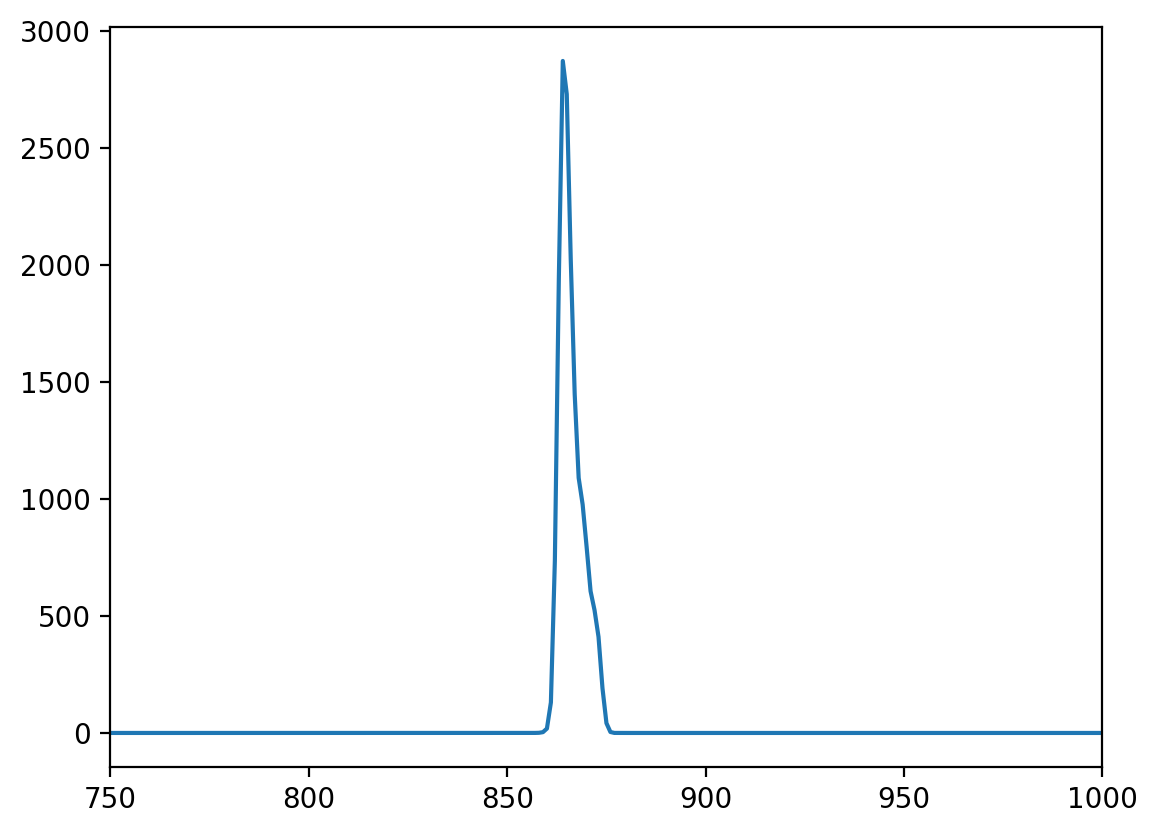

In [52]:
ipix = 560
plt.plot(charge_distrib[ipix, 1]*prob_distrib[ipix, 1])
# ax2 = plt.twinx()
# plt.plot(prob_distrib[ipix, 1], color='orange')
plt.xlim(750, 1000)

In [40]:
jnp.count_nonzero(jnp.abs(charge_distrib[:, 1] - charge_distrib[:, 0]) > 1e-1)

Array(0, dtype=int32)

In [60]:
from tqdm import tqdm
loss_values = {}
print(f"Threshold is {th}")
for local_th in tqdm(range(4000, 9001, 250)):
    mc_adcs, mc_ticks = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_thresh{th}.h5")
    local_params = params.replace(DISCRIMINATION_THRESHOLD=local_th, fee_paths_scaling=20)
    adcs_avg, tick_avg, no_hit_prob, prob_distrib, charge_distrib = get_adc_values_average_noise_vmap(local_params, wfs)

    loss_values[local_th] = []
    # for i in tqdm(range(mc_ticks.shape[0])):
    for i in tqdm(range(10)):
        loss_values[local_th].append(llhd_loss(prob_distrib[:, 0, :], mc_ticks[i, :, 0], no_hit_prob[:, 0], charge_distrib[:, 0, :], mc_adcs[i, :, 0], sigma=1000))

Threshold is 7000


100%|██████████| 21/21 [00:20<00:00,  1.02it/s]


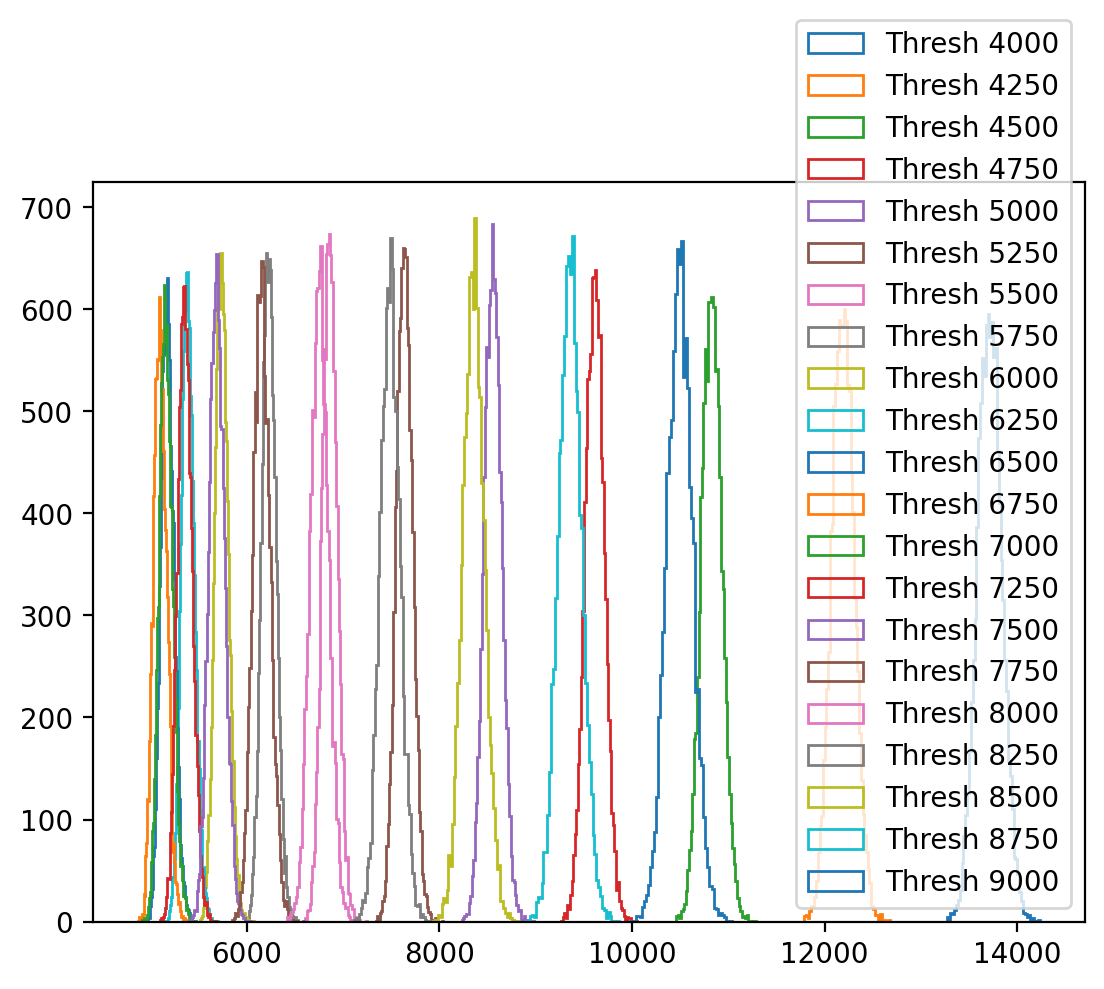

In [30]:
for local_th in loss_values:
    plt.hist(loss_values[local_th], bins=50, histtype='step', label=f"Thresh {local_th}")
plt.legend()

Text(0, 0.5, 'LLHD Loss')

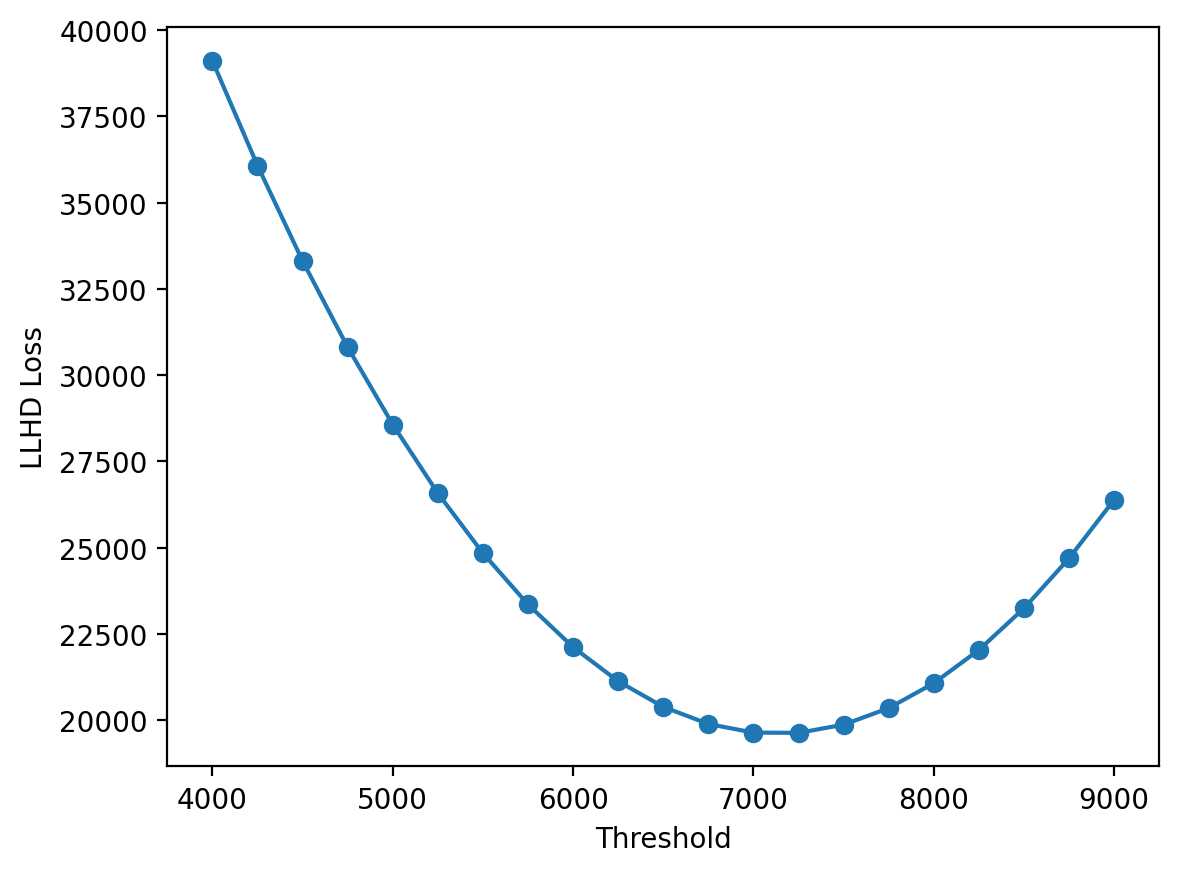

In [62]:

keys = list(loss_values.keys())
values = [jnp.mean(jnp.array(loss_values[k])) for k in keys]
plt.plot(keys, values, marker='o')
plt.xlabel("Threshold")
plt.ylabel("LLHD Loss")

In [24]:
# Toy fit: Optimize noise level (sigma) to best match MC data
import optax
from jax import grad

def fit_loss_function(sigma_log10, mc_data_idx=0):
    """
    Loss function for fitting: compare vmap estimate with given sigma to MC data.
    We'll fit log10(sigma) for numerical stability.
    """
    sigma = 10 ** sigma_log10
    
    # Get reference MC data
    integral_ref = mc_adcs[mc_data_idx]
    ticks_ref = mc_ticks[mc_data_idx]
    hit_prob_ref = jnp.where(ticks_ref < wfs.shape[1] - 3, 1., 0.)
    
    # Use vmap estimate
    integral_vmap = adcs_avg
    ticks_vmap = tick_avg
    hit_prob_vmap = 1 - no_hit_prob
    
    # Calculate loss at this sigma
    l, aux = loss(params, integral_vmap, ticks_vmap, hit_prob_vmap,
                 integral_ref, ticks_ref, hit_prob_ref, unique_pixels, sigma=sigma)
    return l

# Make it differentiable
fit_loss_jit = jit(grad(fit_loss_function))

# Initial guess: sigma = 900 (what's currently used) -> log10(900) ≈ 2.95
initial_sigma_log10 = jnp.log10(900.0)

print("Starting toy fit to optimize sigma...")
print(f"Initial sigma: {10**initial_sigma_log10:.1f}")

# Simple gradient descent
learning_rate = 0.01
sigma_log10 = initial_sigma_log10
n_iterations = 50

history = []
for i in range(n_iterations):
    grad_val = fit_loss_jit(sigma_log10, mc_data_idx=1)
    sigma_log10 = sigma_log10 - learning_rate * grad_val
    
    current_loss = fit_loss_function(sigma_log10, mc_data_idx=1)
    history.append((10**sigma_log10, current_loss))
    
    if i % 10 == 0:
        print(f"Iteration {i}: sigma = {10**sigma_log10:.1f}, loss = {current_loss:.4f}")

print(f"\nFinal sigma: {10**sigma_log10:.1f}")
print(f"Final loss: {history[-1][1]:.4f}")

# Plot convergence
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sigmas_hist = [h[0] for h in history]
losses_hist = [h[1] for h in history]

ax1.plot(sigmas_hist)
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Fitted sigma')
ax1.set_title('Sigma evolution during fit')
ax1.grid(True, alpha=0.3)

ax2.plot(losses_hist)
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Loss')
ax2.set_title('Loss evolution during fit')
ax2.grid(True, alpha=0.3)
plt.tight_layout()

Starting toy fit to optimize sigma...
Initial sigma: 900.0


TracerArrayConversionError: The numpy.ndarray conversion method __array__() was called on traced array with shape int32[]
The error occurred while tracing the function fit_loss_function at /lscratch/pgranger/tmp/ipykernel_1313969/971992531.py:5 for jit. This concrete value was not available in Python because it depends on the value of the argument mc_data_idx.
See https://docs.jax.dev/en/latest/errors.html#jax.errors.TracerArrayConversionError

In [5]:
from tqdm import tqdm
sigmas = np.logspace(-2, 2, 20)
n_seeds = 100

# Prepare data
print(f"Threshold is {th}")
local_params = params.replace(DISCRIMINATION_THRESHOLD=th, fee_paths_scaling=100)
mc_adcs, mc_ticks = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_thresh{th}.h5")
adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_vmap(local_params, wfs)
mc_adcs_nonoise, mc_ticks_nonoise = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_no_noise_thresh{th}.h5")

# Select seeds (excluding seed 1 which is used as reference)
available_seeds = [i for i in range(mc_adcs.shape[0]) if i != 1]
selected_seeds = available_seeds[:n_seeds] if len(available_seeds) >= n_seeds else available_seeds
print(f"Using {len(selected_seeds)} seeds for comparison (excluding seed 1)")

# Storage for losses: [sigma_idx, seed_idx]
values = []   # MC with noise (seed 0) vs MC with noise (different seeds)
values2 = []  # MC no noise (seed 0) vs MC with noise (different seeds)
values3 = []  # vmap estimate vs MC with noise (different seeds)

# Reference: always use seed 1 for comparison
integral_ref = mc_adcs[1]
ticks_ref = mc_ticks[1]
hit_prob_ref = jnp.where(ticks_ref < wfs.shape[1] - 3, 1., 0.)

for sigma in tqdm(sigmas, desc="Sigma loop"):
    losses_method1 = []
    losses_method2 = []
    losses_method3 = []
    
    for seed in tqdm(selected_seeds, desc="Seed loop"):
        # Method 1: MC with noise (seed) vs MC with noise (seed 1)
        integral_mc = mc_adcs[seed]
        ticks_mc = mc_ticks[seed]
        hit_prob_mc = jnp.where(ticks_mc < wfs.shape[1] - 3, 1., 0.)
        l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, 
                     integral_ref, ticks_ref, hit_prob_ref, unique_pixels, sigma=sigma)
        losses_method1.append(l)

        # Method 2: MC no noise (seed) vs MC with noise (seed 1)
        integral_mc_nonoise = mc_adcs_nonoise[seed]
        ticks_mc_nonoise = mc_ticks_nonoise[seed]
        hit_prob_mc_nonoise = jnp.where(ticks_mc_nonoise < wfs.shape[1] - 3, 1., 0.)
        l, aux = loss(params, integral_mc_nonoise, ticks_mc_nonoise, hit_prob_mc_nonoise,
                     integral_ref, ticks_ref, hit_prob_ref, unique_pixels, sigma=sigma)
        losses_method2.append(l)
        
        # Method 3: vmap estimate vs MC with noise (seed i) - compare against each different seed!
        integral_test = mc_adcs[seed]
        ticks_test = mc_ticks[seed]
        hit_prob_test = jnp.where(ticks_test < wfs.shape[1] - 3, 1., 0.)
        
        integral_vmap = adcs_avg
        ticks_vmap = tick_avg
        hit_prob_vmap = 1 - no_hit_prob
        l, aux = loss(params, integral_vmap, ticks_vmap, hit_prob_vmap,
                     integral_test, ticks_test, hit_prob_test, unique_pixels, sigma=sigma)
        losses_method3.append(l)
    
    # Store average loss for this sigma
    values.append(jnp.mean(jnp.array(losses_method1)))
    values2.append(jnp.mean(jnp.array(losses_method2)))
    values3.append(jnp.mean(jnp.array(losses_method3)))

print(f"\nCompleted loss calculation for {len(sigmas)} sigma values across {len(selected_seeds)} seeds")

Threshold is 7000
Using 100 seeds for comparison (excluding seed 1)


Sigma loop: 100%|██████████| 20/20 [02:54<00:00,  8.75s/it]


Completed loss calculation for 20 sigma values across 100 seeds


In [14]:
adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100, preselection_factor=30)
local_params = params.replace(DISCRIMINATION_THRESHOLD=th, fee_paths_scaling=100)
adcs_avg2, tick_avg2, no_hit_prob2, prob_distrib2 = get_adc_values_average_noise_vmap(local_params, wfs)

In [15]:
adcs_mc = digitize(params, adcs_avg)
adcs = digitize(params, adcs_avg2)

pixel_x, pixel_y, pixel_plane, event = id2pixel(params, unique_pixels)
pixel_coords = get_pixel_coordinates(params, pixel_x, pixel_y, pixel_plane)
pixel_x = pixel_coords[:, 0]
pixel_y = pixel_coords[:, 1]

pixel_z_mc  = get_hit_z(params, tick_avg.flatten(), jnp.repeat(pixel_plane, 10))
pixel_z  = get_hit_z(params, tick_avg2.flatten(), jnp.repeat(pixel_plane, 10))

adcs_mc, pixel_x_mc, pixel_y_mc, pixel_z_mc, ticks_mc, hit_prob_mc, event_mc, unique_pixels_mc, nb_valid_mc = parse_output(params, adcs_mc, pixel_x, pixel_y, pixel_z_mc, tick_avg, 1-no_hit_prob, event, unique_pixels)
adcs, pixel_x, pixel_y, pixel_z, ticks, hit_prob, event, unique_pixels, nb_valid = parse_output(params, adcs, pixel_x, pixel_y, pixel_z, tick_avg2, 1-no_hit_prob2, event, unique_pixels)


Q = adc2charge(adcs, params)
Q_mc = adc2charge(adcs_mc, params)

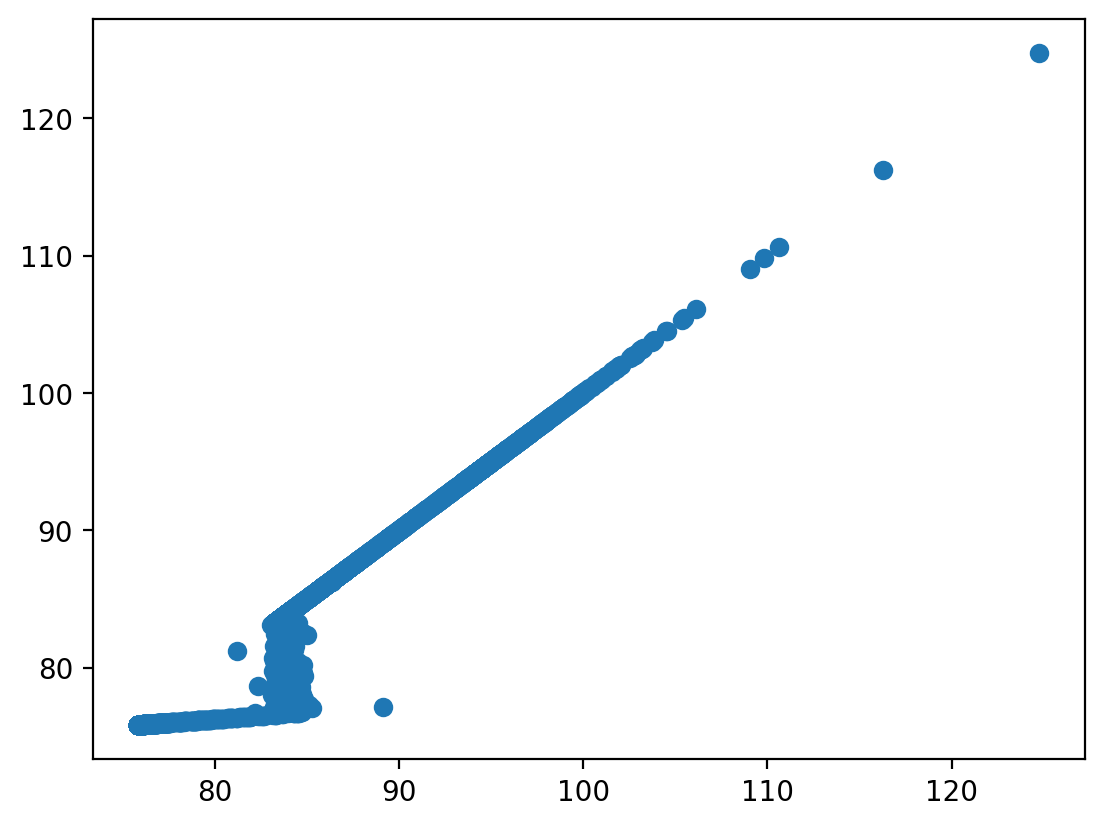

In [16]:
plt.scatter(digitize(params, adcs_avg[:, 0:10]), digitize(params, adcs_avg2[:, 0:10]))

In [26]:
adcs_avg2.shape

(2064, 10)

In [15]:
Q_mc.shape

(20640,)

NameError: name 'adcs_avg_meas' is not defined

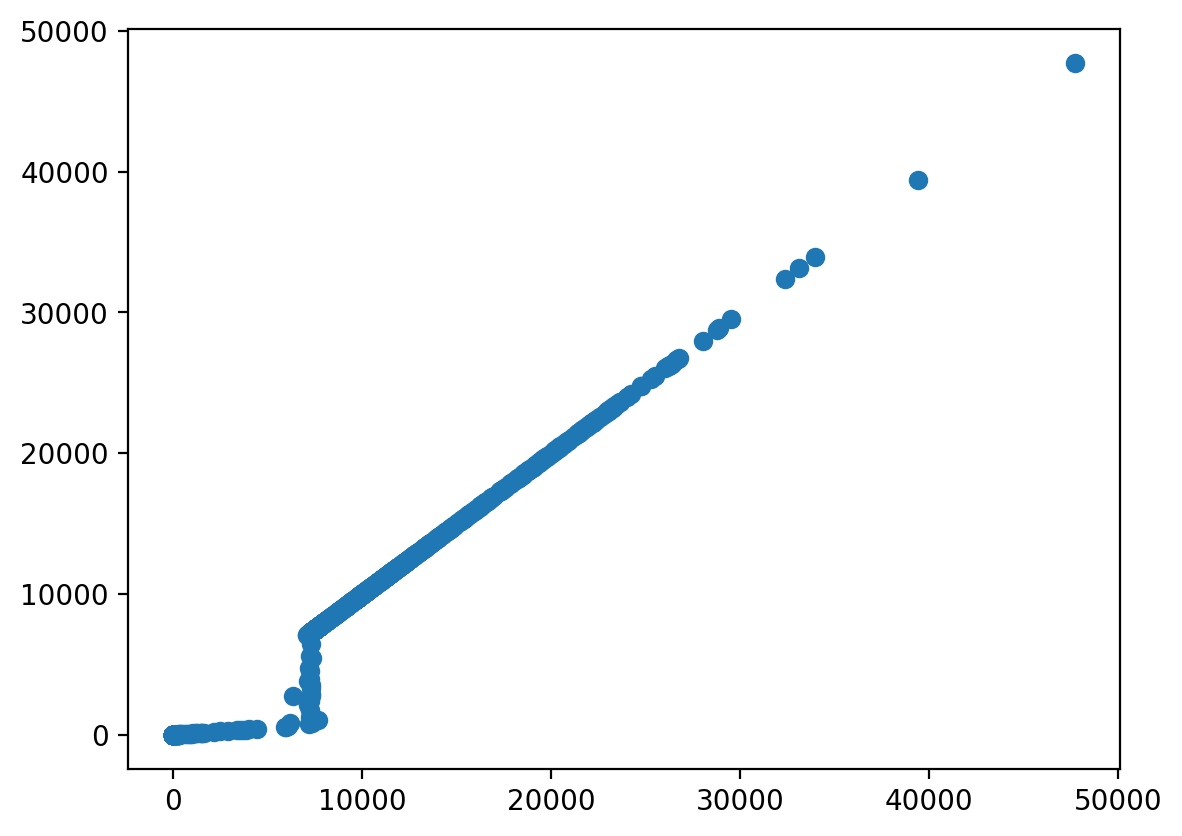

In [18]:
plt.scatter(adcs_avg[:, 1], adcs_avg2[:, 1])
plt.scatter(adcs_avg[:, 1], adcs_avg_meas[:, 1])
plt.xlim(0, 10000)
plt.ylim(0, 10000)

NameError: name 'tick_avg2' is not defined

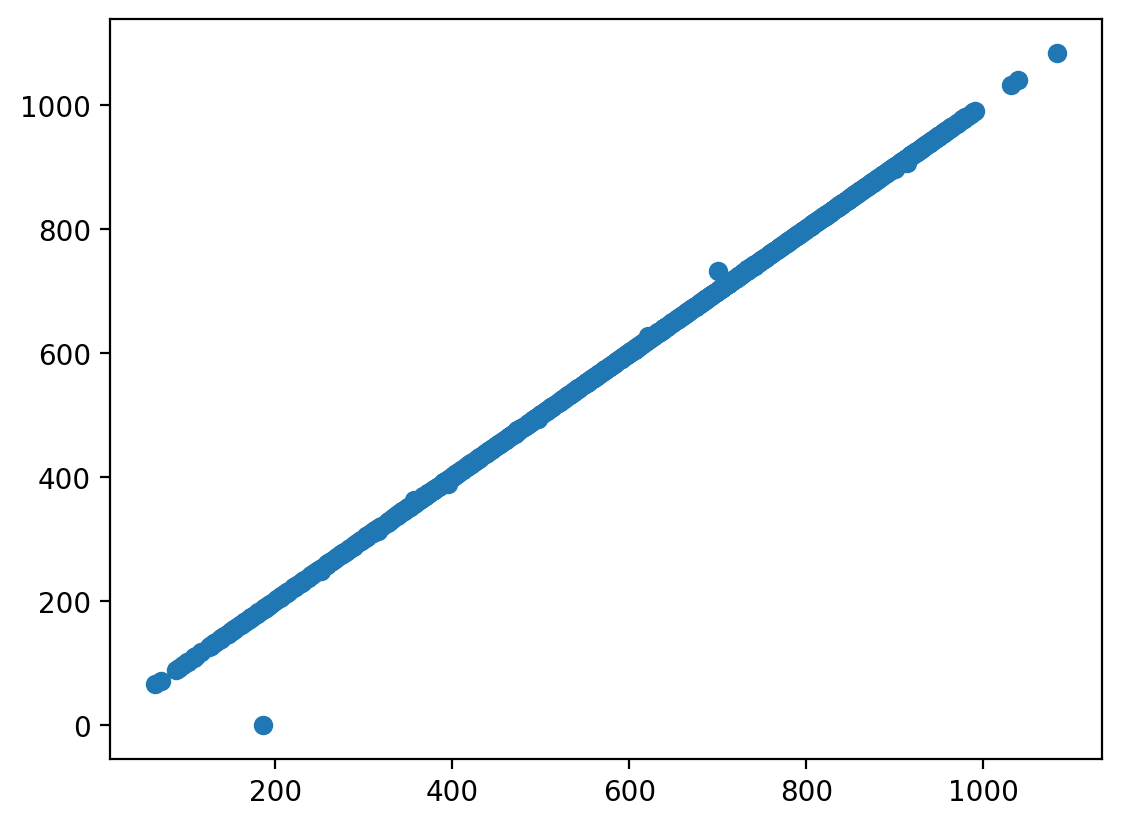

In [37]:
fraction_triggered, tick_avg_meas, adcs_avg_meas = get_summary_stats(mc_adcs, mc_ticks)
plt.scatter(tick_avg_meas[:, 1], tick_avg[:, 1], )
# plt.scatter(tick_avg_meas[:, 1], tick_avg2[:, 1], )
plt.scatter(tick_avg2[:, 1], tick_avg[:, 1], )

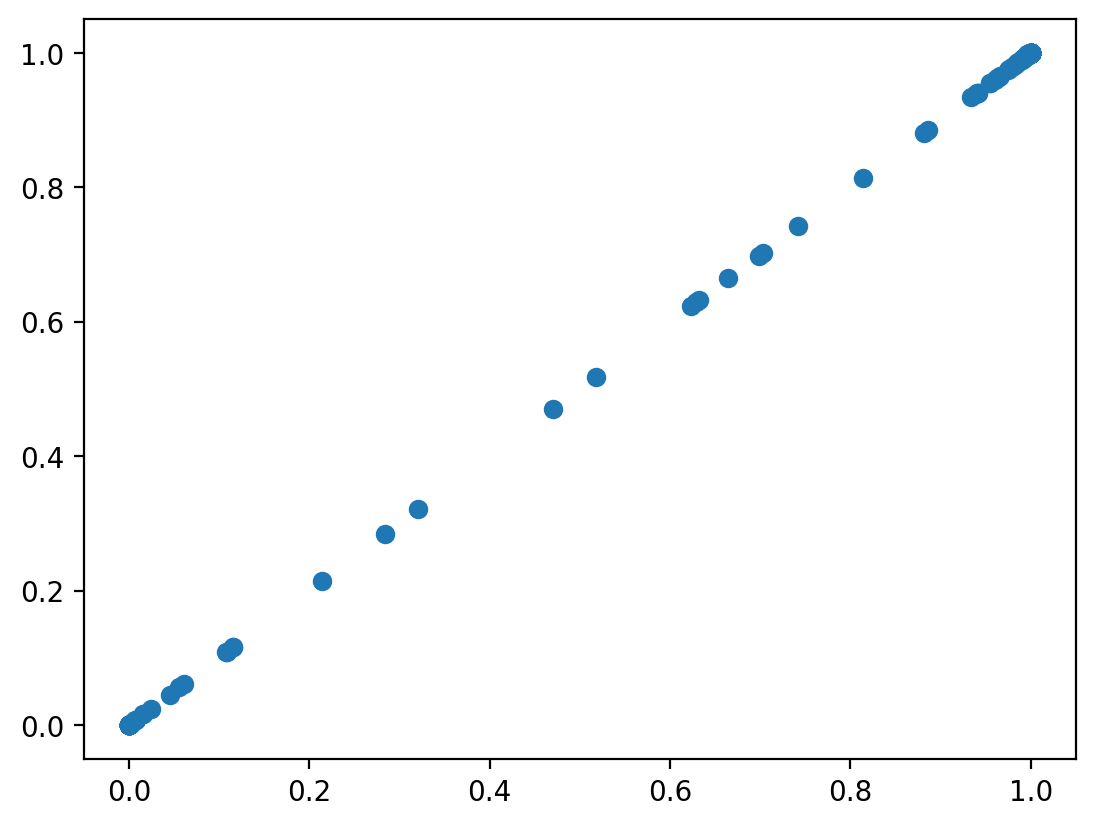

In [47]:
plt.scatter(no_hit_prob[:, 2], no_hit_prob2[:, 2])
# plt.xlim(0, 0.01)

In [39]:
jnp.nanmean(tick_avg_meas[:, 2] - tick_avg2[:, 2])

Array(-0.7605767, dtype=float32)

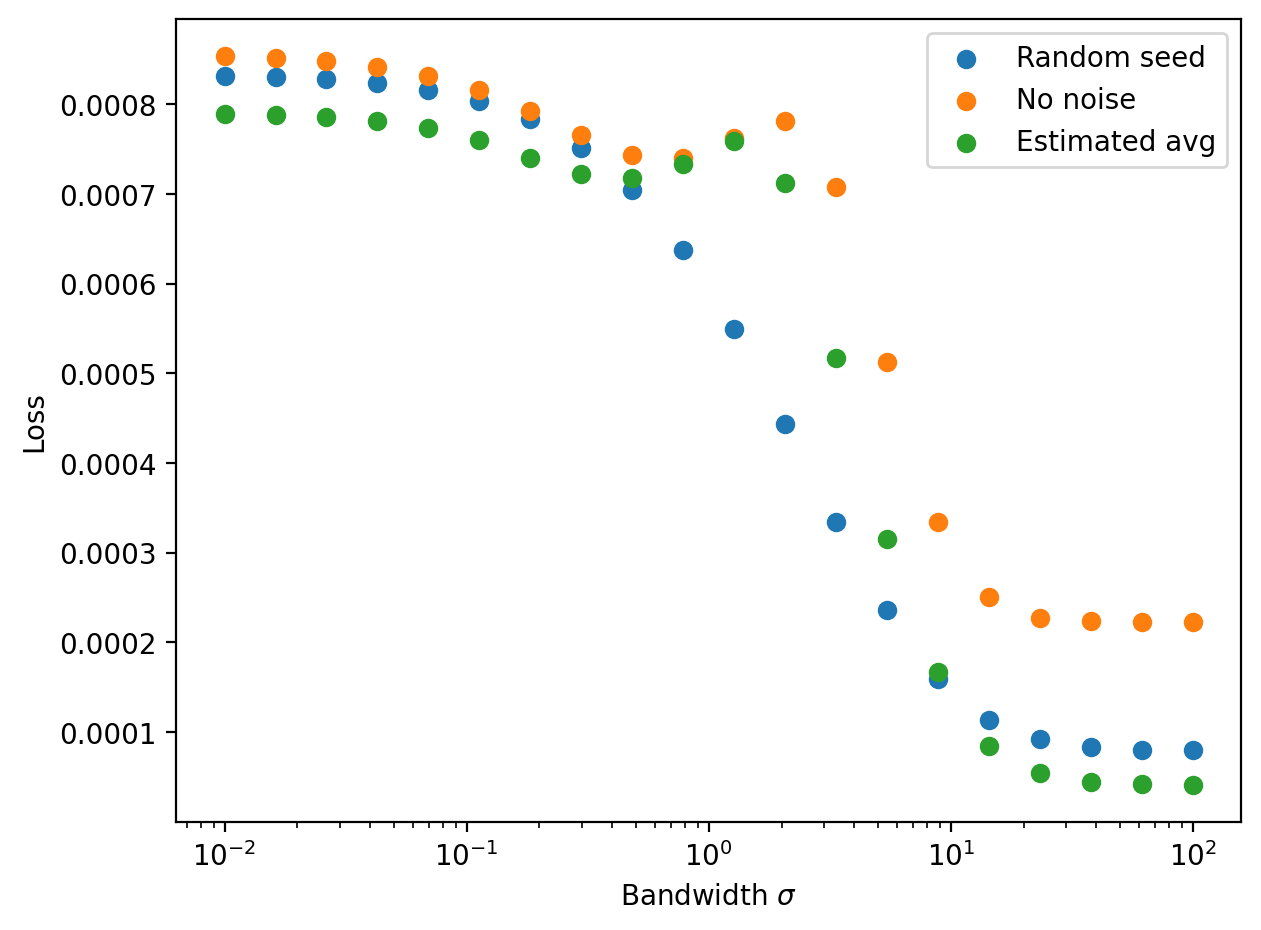

In [6]:
plt.scatter(sigmas, values, label='Random seed')
plt.scatter(sigmas, values2, label='No noise')
plt.scatter(sigmas, values3, label='Estimated avg')
plt.xscale('log')
plt.xlabel(r'Bandwidth $\sigma$')
plt.ylabel(r'Loss')
plt.legend()
plt.tight_layout()

In [8]:
from jax import value_and_grad, checkpoint

def loss_full(integral, ticks, hit_prob, noise, sigma=1):
    # adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, sigma=noise, threshold=th, Nvalues_scaling=50, preselection_factor=10)
    adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_vmap(wfs, sigma=noise, threshold=th, Nvalues_scaling=50)
    
    integral_mc = adcs_avg
    ticks_mc = tick_avg
    hit_prob_mc = 1 - no_hit_prob
    l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels,sigma=sigma)
    return l

noise_levels = np.linspace(100, 2000, 50)
loss_noise1 = []
loss_grads1 = []
loss_noise10 = []
for noise in tqdm(noise_levels):
    integral_mc = mc_adcs[0]
    ticks_mc = mc_ticks[0]
    hit_prob_mc = jnp.where(ticks_mc < wfs.shape[1] - 3, 1., 0.)

    l, g = value_and_grad(loss_full, argnums=3)(integral_mc, ticks_mc, hit_prob_mc, noise, sigma=10)
    
    loss_noise1.append(l)
    loss_grads1.append(g)
    # l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels,sigma=10)
    # loss_noise10.append(l)

100%|██████████| 50/50 [00:19<00:00,  2.50it/s]


In [7]:
def nll_loss(integral, ticks, hit_prob, noise):
    prob_distrib = get_adc_values_average_noise_vmap(wfs, sigma=noise, threshold=th, Nvalues_scaling=50)
    valid_hits_mask = hit_prob > 0
    # Ensure hit times are within the valid index range for the distribution
    safe_hit_times = jnp.clip(ticks, 0, prob_distrib.shape[-1] - 1)
    # 3. Use advanced indexing to look up the probabilities for each true hit
    # This is the core of the NLL calculation. We are "gathering" the probabilities
    # that our model assigned to the ticks where hits actually occurred.
    # We need to add a dimension to safe_hit_times for take_along_axis to work correctly.
    hit_probs = jnp.take_along_axis(prob_distrib, safe_hit_times[..., None], axis=2).squeeze(axis=2)
    # hit_probs now has shape: (Npix, num_steps)

    # 4. Calculate the log-likelihood
    # Add a small epsilon for numerical stability to avoid log(0).
    eps = 1e-5
    log_likelihoods = jnp.log(hit_probs + eps)

    # 5. Apply the mask and compute the final loss
    # We only sum the log-likelihoods for the valid hits.
    masked_log_likelihoods = log_likelihoods * valid_hits_mask
    
    # The total loss is the negative sum of these log-likelihoods.
    total_nll = -jnp.sum(masked_log_likelihoods)
    
    # It's good practice to normalize by the number of valid hits to get the mean.
    num_valid_hits = jnp.sum(valid_hits_mask)
    
    # Avoid division by zero if there are no hits in the batch
    mean_nll = jnp.where(num_valid_hits > 0, total_nll / num_valid_hits, 0.0)
    
    return mean_nll

nll_vmap = jax.vmap(
        nll_loss,
        in_axes=(0, 0, 0, None) # Map over q_sum, charges, probs
    )

noise_values = jnp.linspace(300, 3000, 50)
values = jnp.zeros((len(noise_values), mc_adcs.shape[0]))
# for i in tqdm(range(1000)):
for i, noise in enumerate(tqdm(noise_values)):
    integral = mc_adcs
    ticks = mc_ticks
    hit_prob = jnp.where(ticks < wfs.shape[1] - 3, 1., 0.)
    l = nll_vmap(integral, ticks, hit_prob, noise)
    values = values.at[i].set(l)

100%|██████████| 50/50 [00:20<00:00,  2.39it/s]


In [30]:
def get_adc_values_average_noise_vmap_nojit(wfs, sigma, threshold=7000, Nvalues_scaling=20, stop_threshold=1e-9):
    """
    A globally-stopped, vmap-based implementation of the beam search. This is a
    highly optimized pattern for parallel hardware.
    """
    Npix, Nticks = wfs.shape
    Nvalues = Nvalues_scaling
    
    # --- Vectorize the single-step function ---
    vmapped_step_fun = jax.vmap(
        _find_one_hit_step,
        in_axes=(0, 0, 0, None, None, None) # Map over q_sum, charges, probs
    )

    # --- Pre-calculate q_sum for all pixels ---
    q = wfs * 0.1
    q_sum_all = q.cumsum(axis=-1)
    

    def global_scan_fun(carry, _):
        """The main scan function with a global conditional stop."""
        prev_charges_all, prev_probs_all, is_active_global = carry

        # Apply jax.checkpoint to the expensive branch of the computation.
        # This tells JAX not to store intermediate values from this function,
        # saving memory at the cost of some re-computation.
        @jax.checkpoint
        def _active_branch(operand):
            """The expensive vmapped computation, only run when globally active."""
            charges, probs, _ = operand
            # Run one hit-finding step for all pixels in parallel
            (new_charges, new_probs), prob_dist = vmapped_step_fun(
                q_sum_all, charges, probs, sigma, threshold, Nvalues
            )
            # Check if ANY pixel is still active for the next iteration
            new_active_flag = jnp.any(jnp.sum(new_probs, axis=1) > stop_threshold)
            
            return (new_charges, new_probs, new_active_flag), prob_dist

        def _inactive_branch(operand):
            """A cheap pass-through, executed when the whole batch is inactive."""
            return operand, jnp.zeros((Npix, Nticks - 1), dtype=jnp.float32)

        # --- Global Conditional Execution ---
        final_carry, final_outputs = lax.cond(
            is_active_global,
            _active_branch,
            _inactive_branch,
            carry
        )
        return final_carry, final_outputs

    # --- Setup and Execute the Global Scan ---
    initial_charges = jnp.zeros((Npix, Nvalues), dtype=jnp.float32)
    initial_probs = jnp.zeros((Npix, Nvalues), dtype=jnp.float32).at[:, 0].set(1.0)
    initial_active = jnp.array(True)
    
    init_loop = (initial_charges, initial_probs, initial_active)
    
    _, prob_distrib = lax.scan(global_scan_fun, init_loop, jnp.arange(0, 10))
    
    # Transpose the outputs to match the desired shape (Npix, num_steps, ...)
    return jnp.moveaxis(prob_distrib, 0, 1)

prob_distrib_jac = jax.jacfwd(get_adc_values_average_noise_vmap_nojit, argnums=1)(wfs, noise, threshold=th, Nvalues_scaling=50)
prob_distrib = get_adc_values_average_noise_vmap_nojit(wfs, noise, threshold=th, Nvalues_scaling=50)

In [12]:
prob_distrib_jac.shape

(2064, 10, 2000)

(860.0, 960.0)

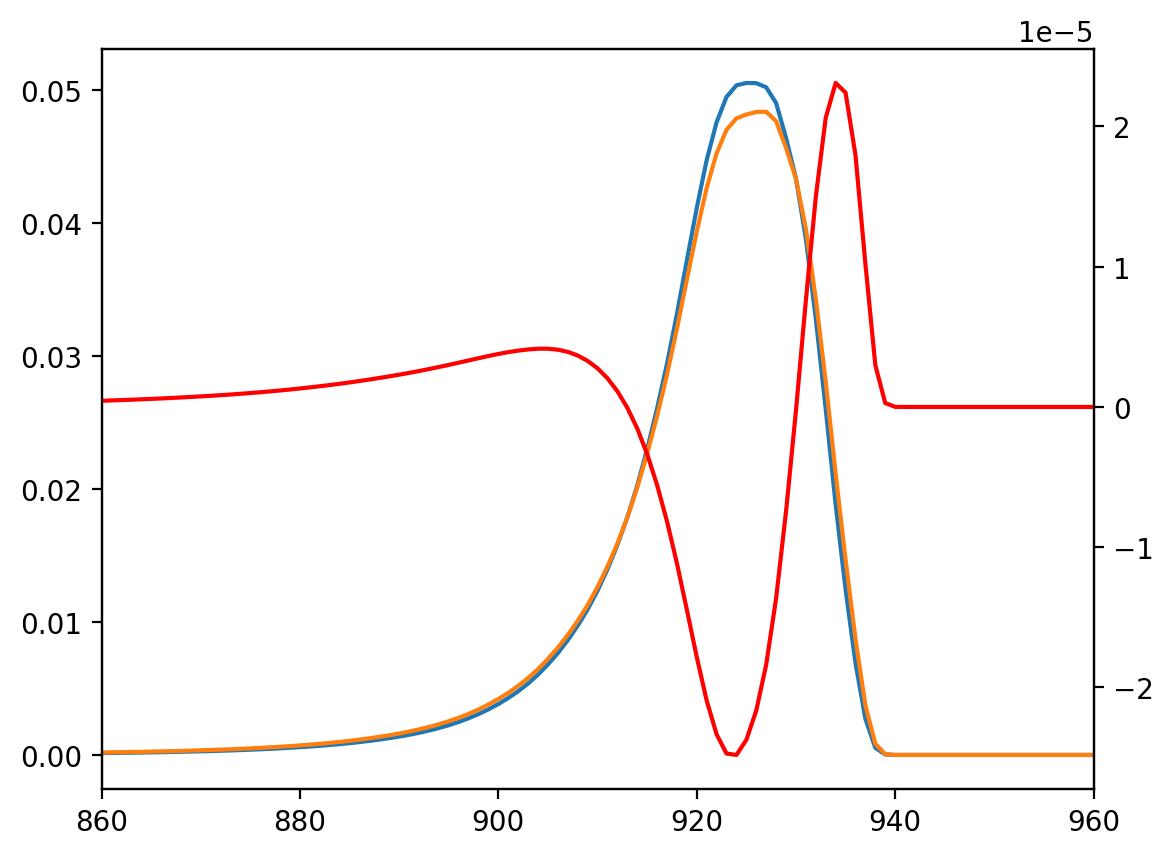

In [26]:
import matplotlib.pyplot as plt
for ipix in range(1051, 1052):
    # plt.plot(estimated[ipix, :])
    plt.plot(prob_distrib[ipix, 0, :])
    plt.plot(prob_distrib[ipix, 0, :] + 100*prob_distrib_jac[ipix, 0, :])
    plt.twinx()
    plt.plot(prob_distrib_jac[ipix, 0, :], color='red')
    # plt.axvline(tick_avg[ipix, 0])
plt.xlim(860, 960)

100%|██████████| 20/20 [00:00<00:00, 248.55it/s]


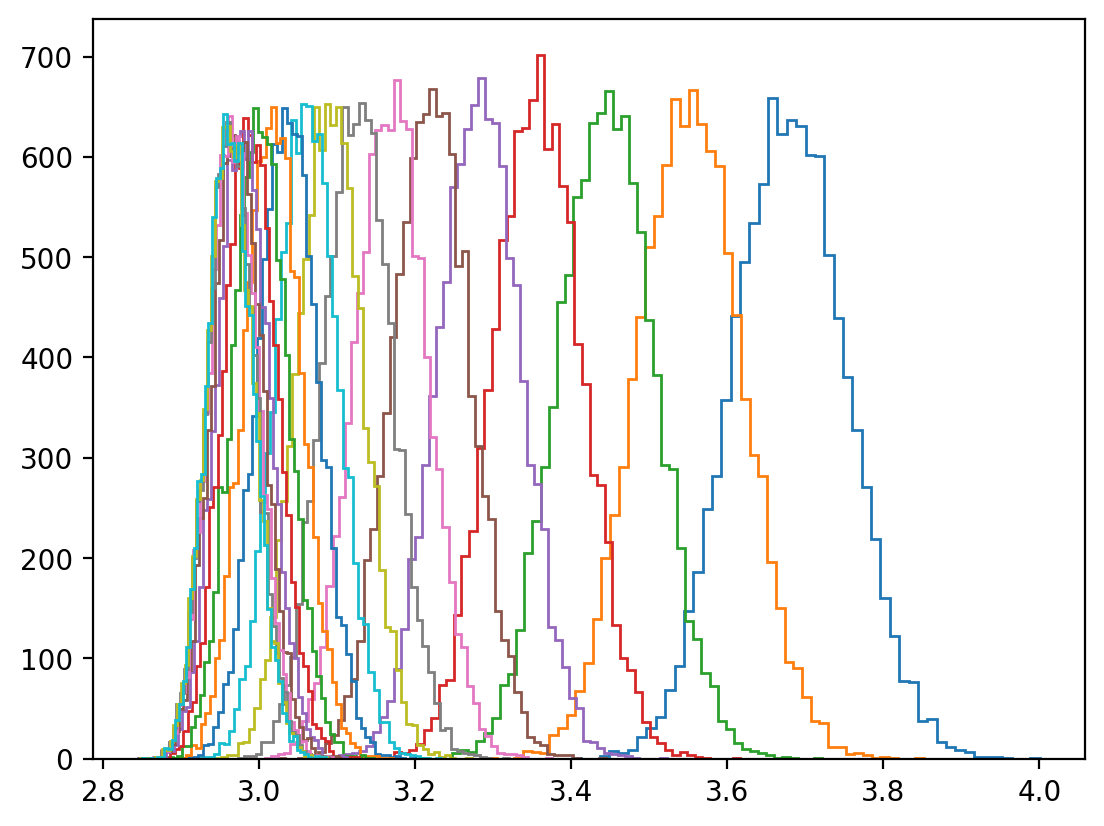

In [31]:
for i, noise in enumerate(tqdm(noise_values)):
    plt.hist(values[i], bins=50, histtype='step')

ValueError: x and y must be the same size

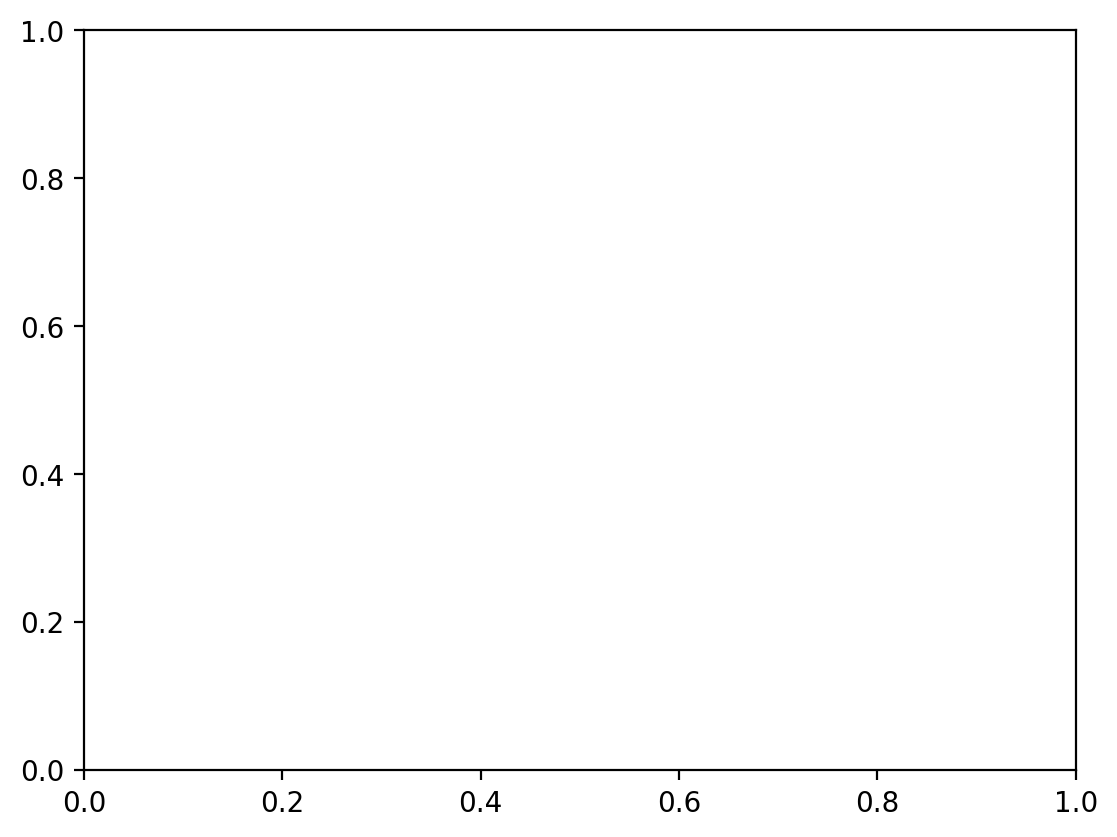

In [7]:
plt.scatter(noise_values, values)

In [8]:
from jax import value_and_grad, checkpoint

noise_levels = np.linspace(100, 2000, 50)
loss_noise1 = []
loss_grads1 = []
loss_noise10 = []
for noise in tqdm(noise_levels):
    integral_mc = mc_adcs[0]
    ticks_mc = mc_ticks[0]
    hit_prob_mc = jnp.where(ticks_mc < wfs.shape[1] - 3, 1., 0.)

    l, g = value_and_grad(nll_loss, argnums=3)(integral_mc, ticks_mc, hit_prob_mc, noise)
    
    loss_noise1.append(l)
    loss_grads1.append(g)
    # l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels,sigma=10)
    # loss_noise10.append(l)

100%|██████████| 50/50 [00:23<00:00,  2.10it/s]


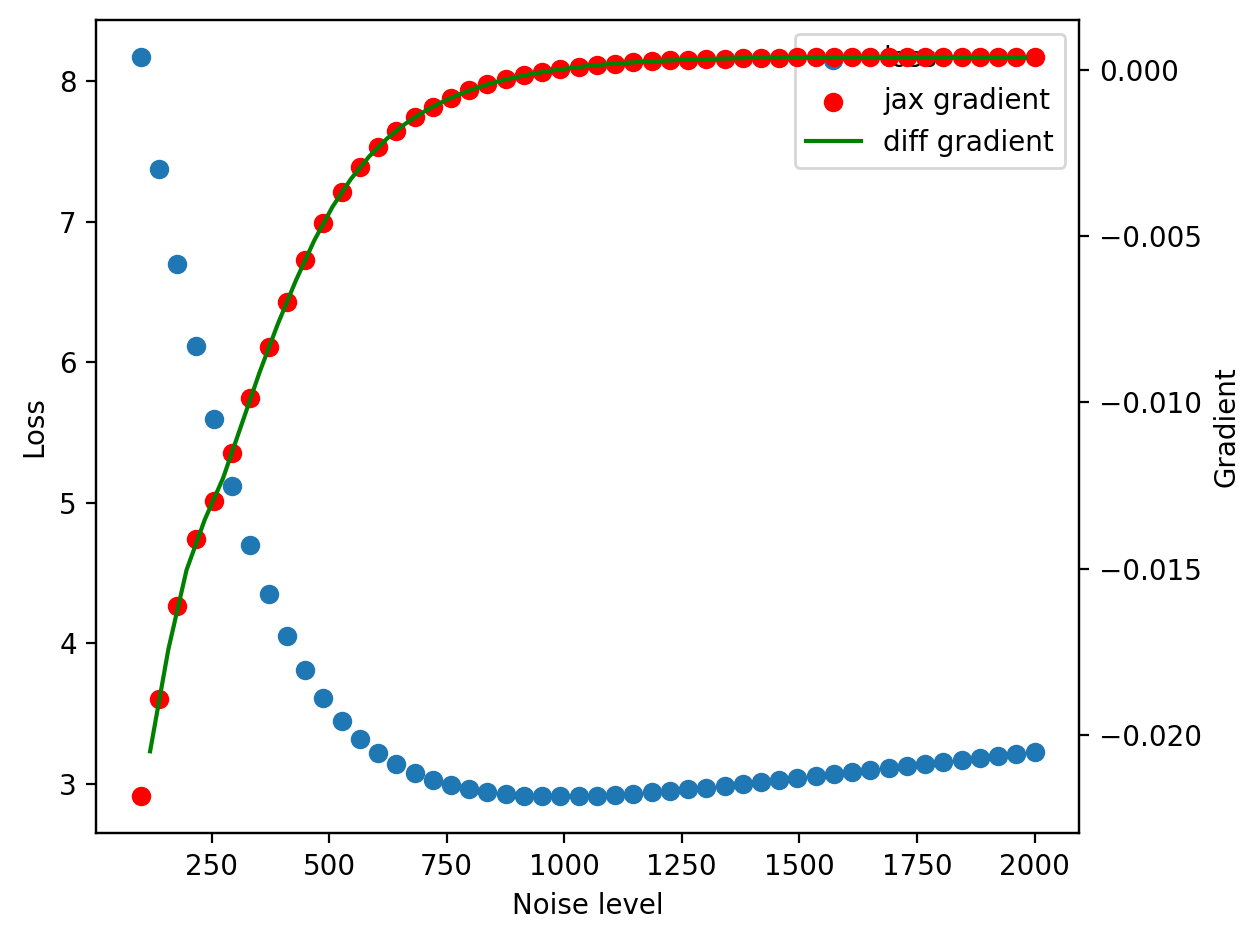

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# --- Assuming you have these variables defined ---
# noise_levels = ...
# loss_noise1 = ...
# loss_grads1 = ...
# -------------------------------------------------

# Create the first axis
fig, ax1 = plt.subplots()

# Plot on the first axis (ax1)
p1 = ax1.scatter(noise_levels, loss_noise1, label='loss')
ax1.set_xlabel("Noise level")
ax1.set_ylabel("Loss") # You should add a label for clarity

# Create the second axis
ax2 = ax1.twinx()

# Plot on the second axis (ax2)
p2 = ax2.scatter(noise_levels, loss_grads1, color='r', label='jax gradient')
p3 = ax2.plot(0.5*(noise_levels[1:] + noise_levels[:-1]), np.diff(loss_noise1)/np.diff(noise_levels), color='g', label='diff gradient')
ax2.set_ylabel("Gradient") # You should add a label for clarity

# --- This is the key part ---
# 1. Get handles and labels from both axes
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

# 2. Combine them
# Note: You can also use h1 + h2 and l1 + l2, but this way is more robust
# if you want to control the order.
handles = [p1, p2, p3[0]] # p3[0] is needed because plot returns a list
labels = [h.get_label() for h in handles]

# 3. Apply the combined legend to one of the axes
ax1.legend(handles, labels, loc='best') # 'loc' helps find the best spot

plt.tight_layout()
# plt.show() # Display the plot

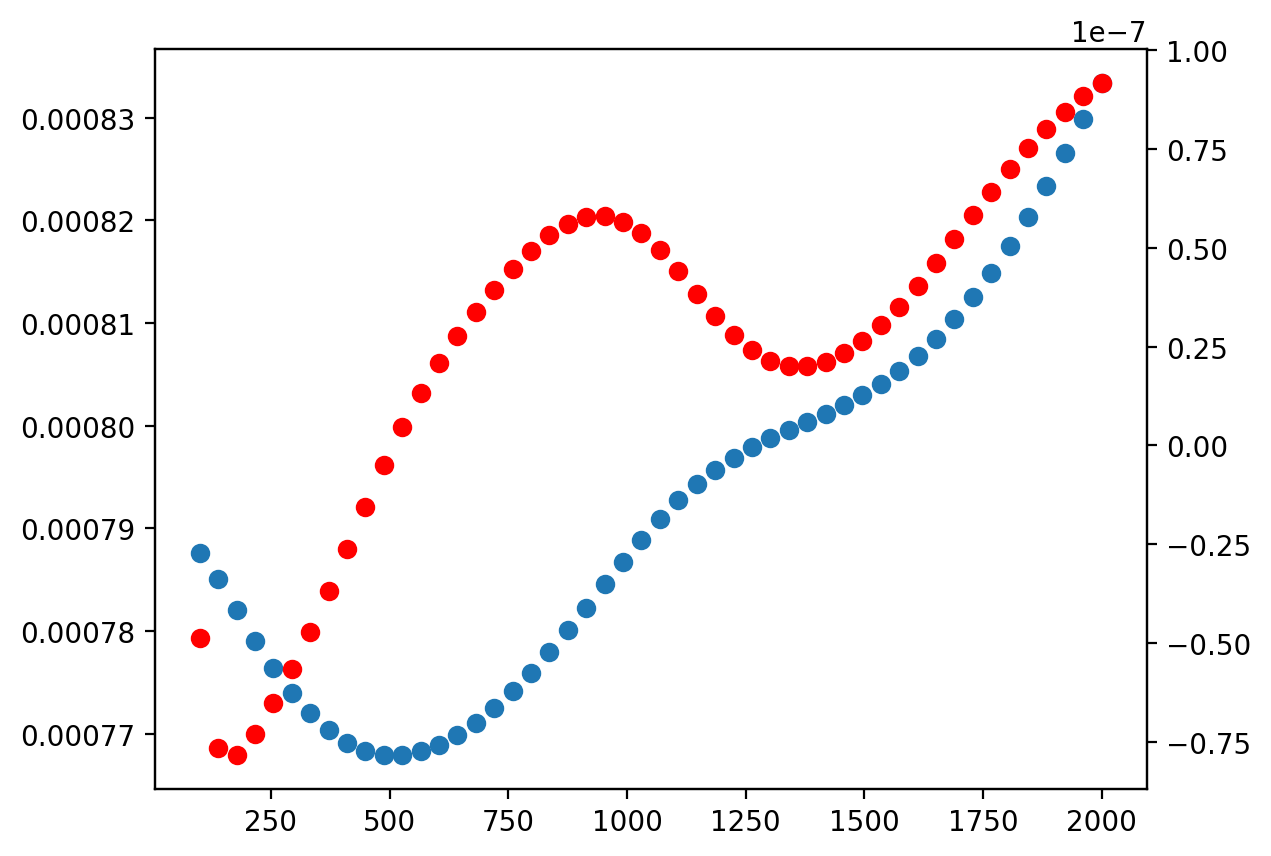

In [13]:
plt.scatter(noise_levels, loss_noise1)
plt.twinx()
plt.scatter(noise_levels, loss_grads1, color='r')
# plt.scatter(noise_levels, loss_noise10)

In [ ]:
integral_mc = mc_adcs[0]
ticks_mc = mc_ticks[0]
hit_prob_mc = jnp.where(ticks_mc < wfs.shape[1] - 3, 1., 0.)

losses10 = []

for i in tqdm(range(500)):
    integral = mc_adcs[i+1]
    ticks = mc_ticks[i+1]
    hit_prob = jnp.where(ticks < wfs.shape[1] - 3, 1., 0.)
    l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels)
    losses10.append(l)

In [ ]:
mc_adcs_nonoise, mc_ticks_nonoise = load_mc(f"/sdf/group/neutrino/pgranger/larnd-sim-jax/adc_output_no_noise_thresh{th}.h5")
# integral_mc = mc_adcs_nonoise[0]
# ticks_mc = mc_ticks_nonoise[0]
# hit_prob_mc = jnp.where(ticks_mc < wfs.shape[1] - 3, 1., 0.)

# losses_no_noise10 = []

# for i in tqdm(range(500)):
#     integral = mc_adcs[i+1]
#     ticks = mc_ticks[i+1]
#     hit_prob = jnp.where(ticks < wfs.shape[1] - 3, 1., 0.)
#     l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels)
#     losses_no_noise10.append(l)

In [5]:
adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100, preselection_factor=30)
integral_mc = adcs_avg
ticks_mc = tick_avg
hit_prob_mc = 1 - no_hit_prob

losses_new = []

for i in tqdm(range(500)):
    integral = mc_adcs[i+1]
    ticks = mc_ticks[i+1]
    hit_prob = jnp.where(ticks < wfs.shape[1] - 3, 1., 0.)
    l, aux = loss(params, integral_mc, ticks_mc, hit_prob_mc, integral, ticks, hit_prob, unique_pixels)
    losses_new.append(l)

100%|██████████| 500/500 [00:29<00:00, 16.78it/s]


(array([ 1.,  2., 21., 40., 50., 60., 68., 68., 64., 34., 25., 25., 15.,
         9.,  6.,  2.,  4.,  4.,  1.,  1.]),
 array([3.02977860e-05, 3.43576066e-05, 3.84174273e-05, 4.24772516e-05,
        4.65370722e-05, 5.05968928e-05, 5.46567135e-05, 5.87165341e-05,
        6.27763584e-05, 6.68361754e-05, 7.08959997e-05, 7.49558239e-05,
        7.90156409e-05, 8.30754652e-05, 8.71352822e-05, 9.11951065e-05,
        9.52549308e-05, 9.93147478e-05, 1.03374572e-04, 1.07434389e-04,
        1.11494213e-04]),
 [<matplotlib.patches.Polygon at 0x7f609da7cd90>])

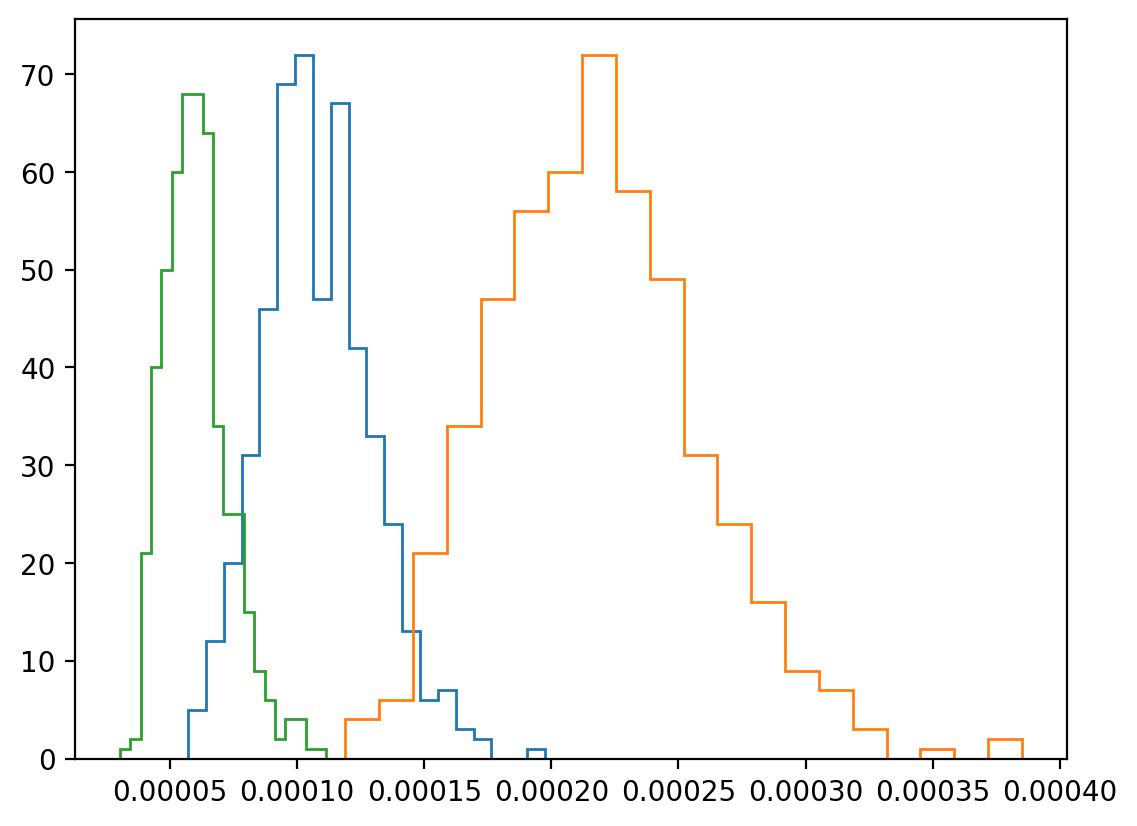

In [8]:
import matplotlib.pyplot as plt
plt.hist(losses10, histtype='step', bins=20)
plt.hist(losses_no_noise10, histtype='step', bins=20)
plt.hist(losses_new, histtype='step', bins=20)

In [328]:
# Lower the jitted function to get a "compiled" object
compiled_fn = jax.jit(get_adc_values_average_noise_test, static_argnums=(3, 4)).lower(wfs, threshold=th, Nvalues_scaling=100).compile()

# Get the cost analysis dictionary
cost = compiled_fn.cost_analysis()

# Print the results in a readable format
print(f"FLOPs: {cost['flops']:,}")
print(f"Bytes Accessed: {cost['bytes accessed']:,}")
print(f"Transcendentals: {cost['transcendentals']:,}")

FLOPs: 49,021,276,160.0
Bytes Accessed: 48,226,459,648.0
Transcendentals: 1,238,606,336.0


(Array(50, dtype=int32), Array(2000, dtype=int32)))
(Array(50, dtype=int32), Array(2000, dtype=int32)))
(Array(50, dtype=int32), Array(2000, dtype=int32)))
(Array(50, dtype=int32), Array(2000, dtype=int32)))
(Array(50, dtype=int32), Array(2000, dtype=int32)))
(Array(50, dtype=int32), Array(2000, dtype=int32)))


(860.0, 960.0)

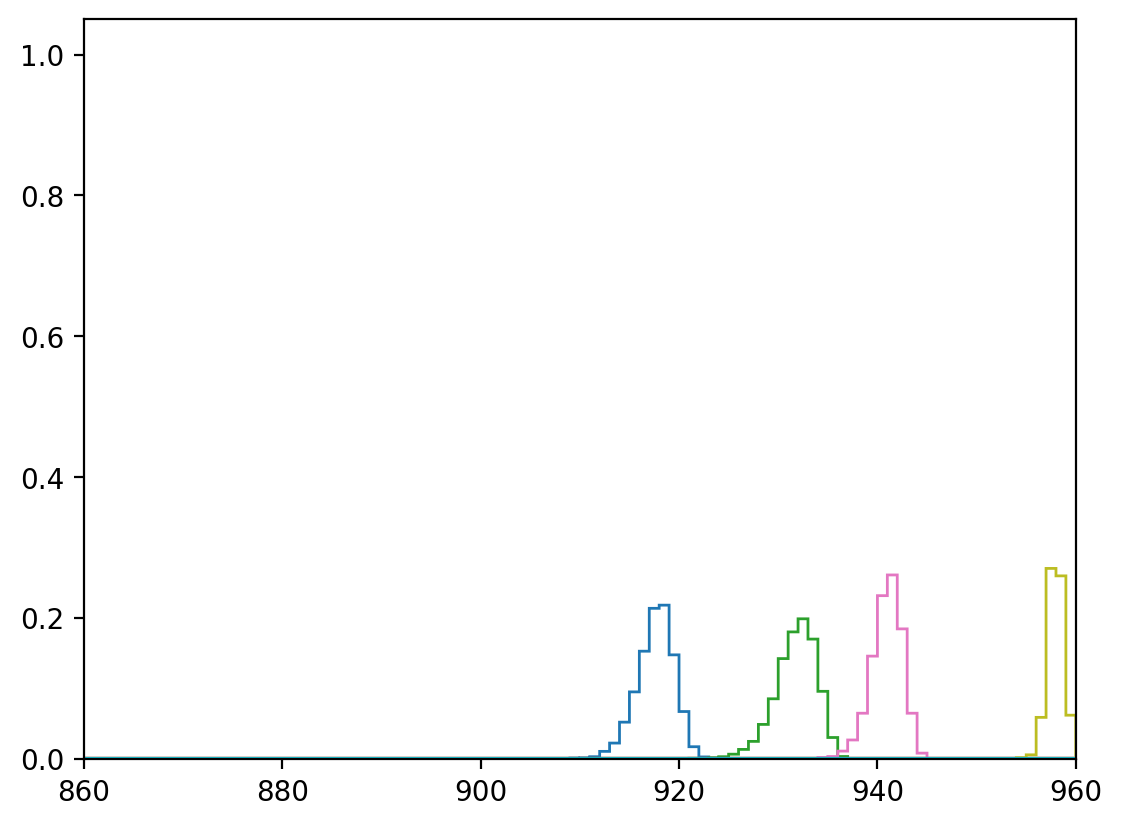

In [54]:
import matplotlib.pyplot as plt
prob_distrib = get_adc_values_average_noise_vmap(wfs, threshold=th, Nvalues_scaling=50)
for ipix in range(1050, 1055):
    plt.hist(mc_ticks[:, ipix, 0], bins=np.arange(0, 2000), histtype='step', density=True);
    # plt.plot(estimated[ipix, :])
    plt.plot(prob_distrib[:, ipix, 0])
    # plt.axvline(tick_avg[ipix, 0])
plt.xlim(860, 960)

(0.0, 0.1)

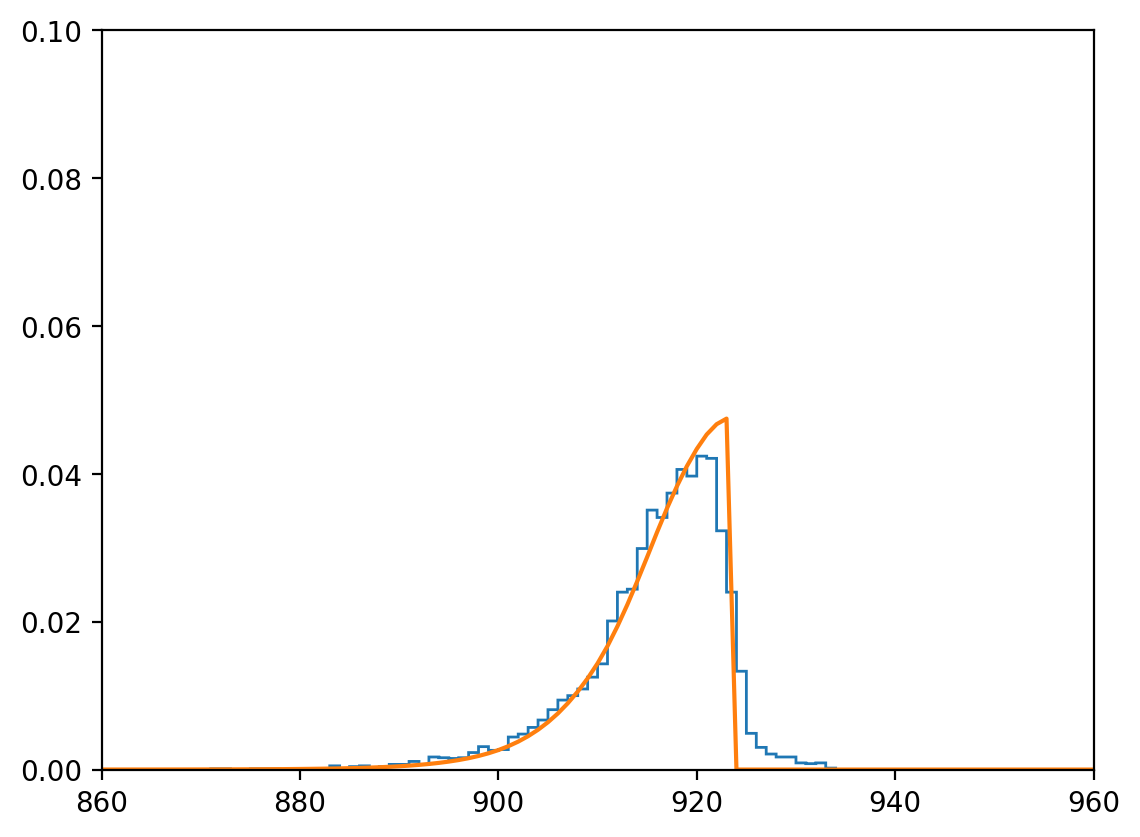

In [76]:
import matplotlib.pyplot as plt
adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100)
hitid = 0

for ipix in range(1052, 1053):
    plt.hist(mc_ticks[:, ipix, hitid], bins=np.arange(0, 2000), histtype='step', density=True);
    # plt.plot(estimated[ipix, :])
    plt.plot(prob_distrib[:, ipix, hitid])
    # plt.axvline(tick_avg[ipix, 0])
plt.xlim(860, 960)
plt.ylim(0, 0.1)

(0.0, 0.08)

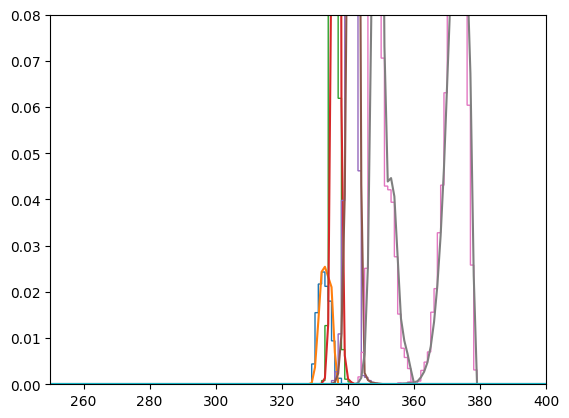

In [382]:
import matplotlib.pyplot as plt

hitid = 2

for ipix in range(1300, 1310):
    plt.hist(mc_ticks[:, ipix, hitid], bins=np.arange(0, 2000), histtype='step', density=True);
    # plt.plot(estimated[ipix, :])
    plt.plot(prob_distrib[:, ipix, hitid])
    # plt.axvline(tick_avg[ipix, 0])
plt.xlim(250, 400)
plt.ylim(0, 0.08)

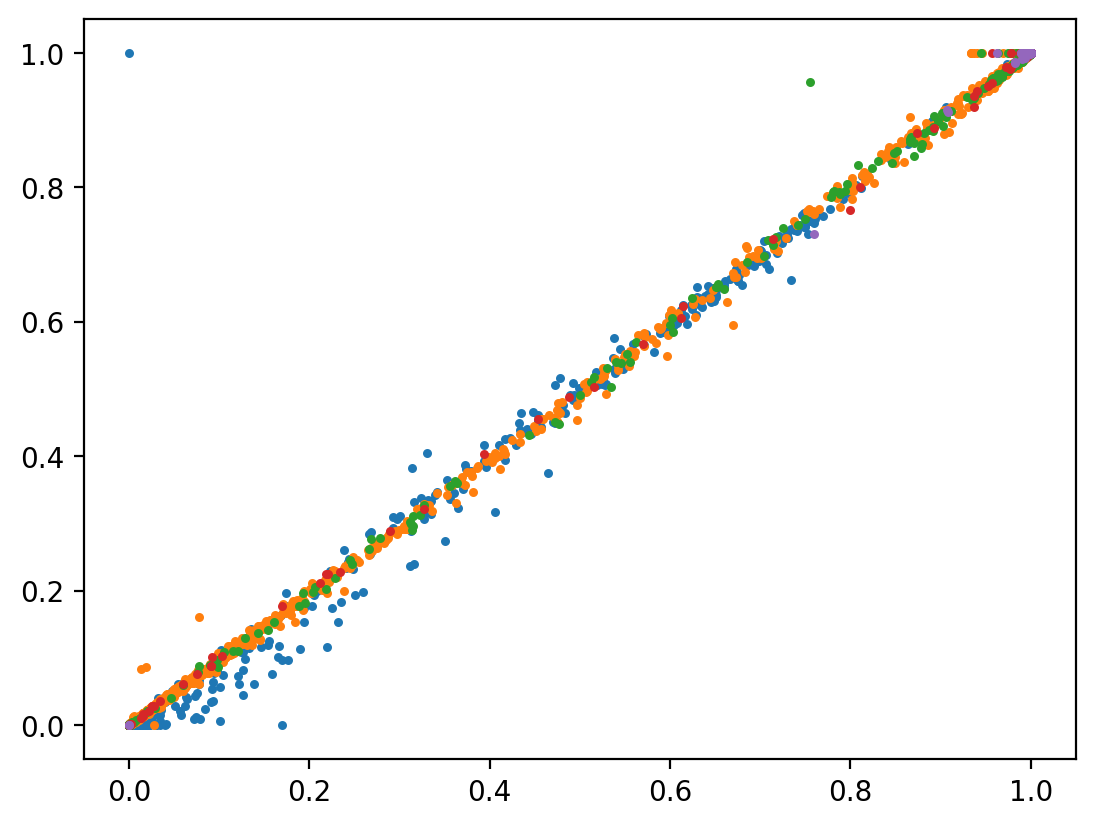

In [96]:
for ihit in range(5):
    plt.scatter(1 - fraction_triggered[:, ihit], no_hit_prob[:, ihit], s=5)

array([[ 160],
       [ 262],
       [ 311],
       [ 374],
       [ 376],
       [ 378],
       [ 451],
       [ 454],
       [ 464],
       [ 487],
       [ 819],
       [ 884],
       [ 902],
       [ 927],
       [ 961],
       [ 965],
       [1165],
       [1349],
       [1387],
       [1540],
       [1545],
       [1566],
       [1599],
       [1617],
       [1638],
       [1866]], dtype=int32)

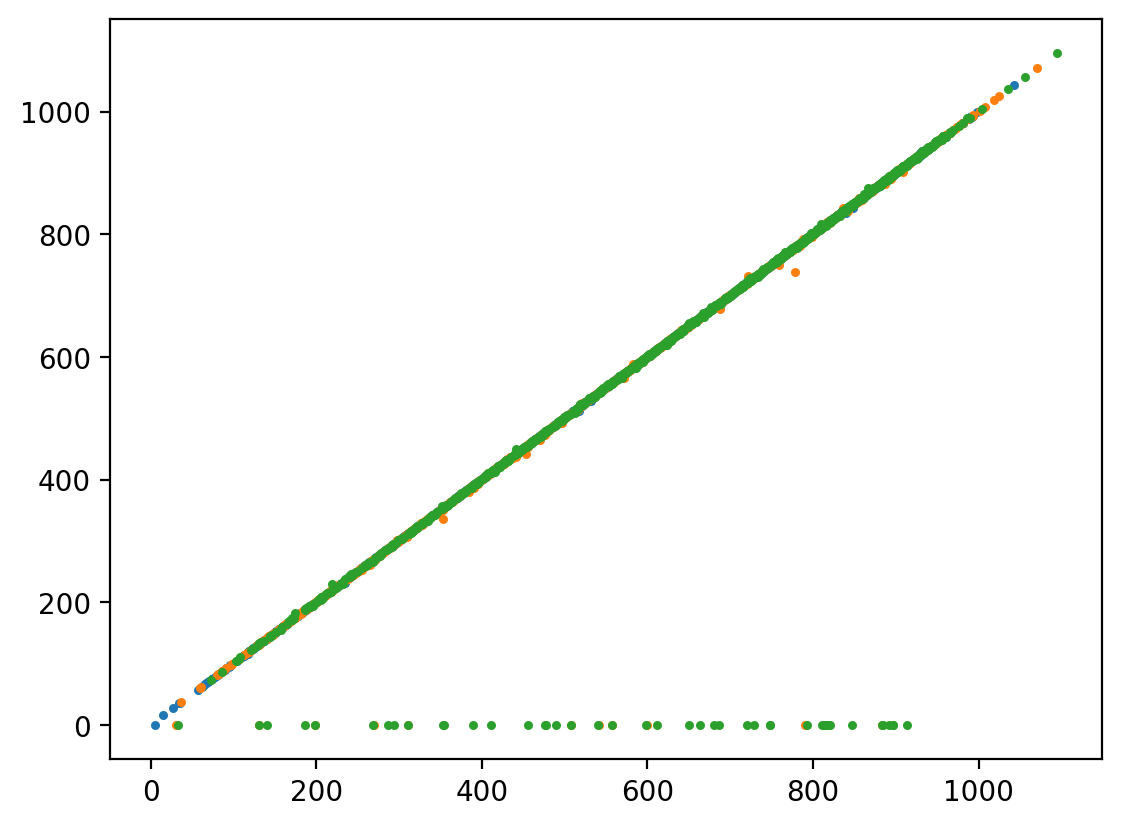

In [102]:
for ihit in range(3):
    plt.scatter(mc_tick_avg[:, ihit], tick_avg[:, ihit], s=5)
w = np.argwhere((mc_tick_avg[:, 2]>500) & (tick_avg[:, 2] < 5))
# print(mc_tick_avg[w, 2])
w

(array([ 2.,  0.,  2.,  1.,  0.,  2.,  4.,  6.,  2.,  5.,  6., 15.,  9.,
        13., 16., 11., 13.,  9., 18., 10.,  7., 14., 13., 15., 17., 15.,
        22., 15., 20., 19., 19., 26., 15., 12., 19., 23., 25., 22., 24.,
        25., 20., 28., 20., 21., 26., 22., 10., 24., 22., 29., 20., 29.,
        25., 29., 28., 25., 28., 30., 20., 26., 24., 24., 29., 26., 35.,
        31., 25., 23., 31., 29., 30., 31., 42., 34., 38., 37., 59., 38.,
        45., 36., 41., 33., 37., 31., 32., 34., 33., 29., 24., 12., 15.,
         3.,  1.,  2.,  5.,  2.,  0.,  0.,  0.,  1.]),
 array([   8.2809    ,   18.74347878,   29.2060585 ,   39.66863632,
          50.13121796,   60.59379578,   71.0563736 ,   81.51895142,
          91.98153687,  102.44411469,  112.9066925 ,  123.36927032,
         133.83184814,  144.29443359,  154.75700378,  165.21958923,
         175.68215942,  186.14474487,  196.60733032,  207.06990051,
         217.53248596,  227.99505615,  238.4576416 ,  248.92022705,
         259.3828125 ,  26

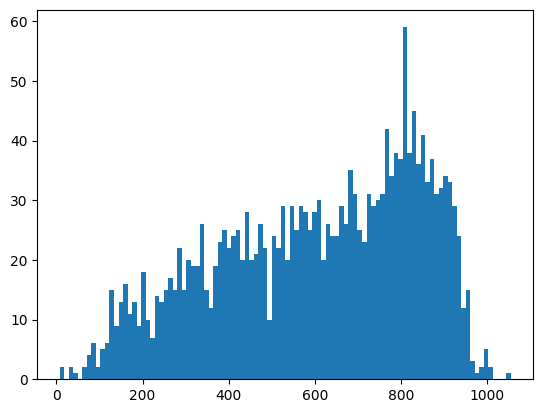

In [529]:
plt.hist(mc_tick_avg[:, 0], bins=100)

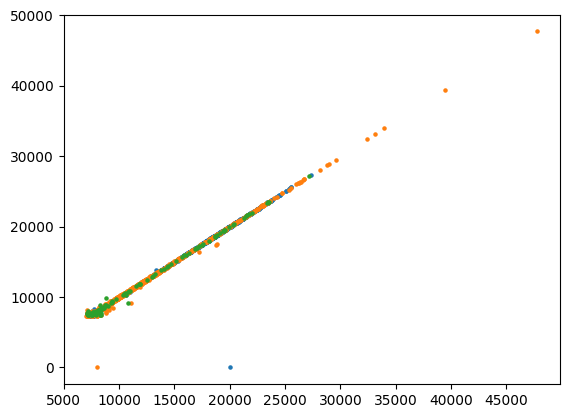

In [525]:
for ihit in range(3):
    plt.scatter(mc_adcs_avg[:, ihit], adcs_avg[:, ihit], s=5)

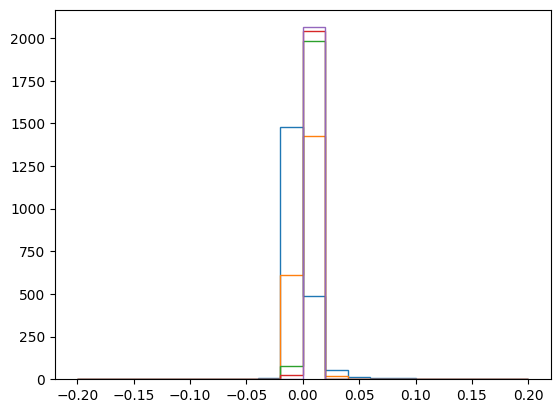

In [391]:
for ihit in range(5):
    plt.hist(1 - fraction_triggered[:, ihit] - no_hit_prob[:, ihit], histtype='step', range=(-0.2, 0.2), bins=20)
# plt.yscale('log')

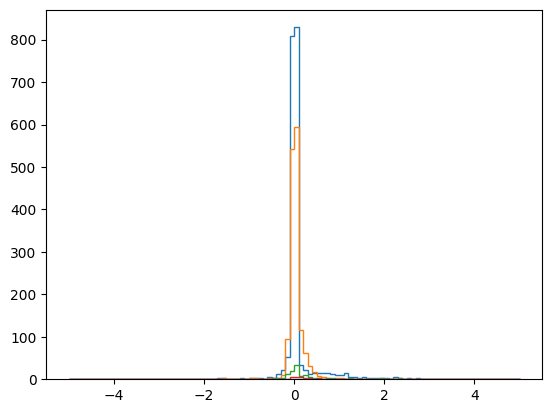

In [406]:
# _, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=200)
for ihit in range(5):
    plt.hist(mc_tick_avg[:, ihit] - tick_avg[:, ihit] + 1, histtype='step', range=(-5, 5), bins=100)

Text(0, 0.5, 'Time difference')

<Figure size 640x480 with 0 Axes>

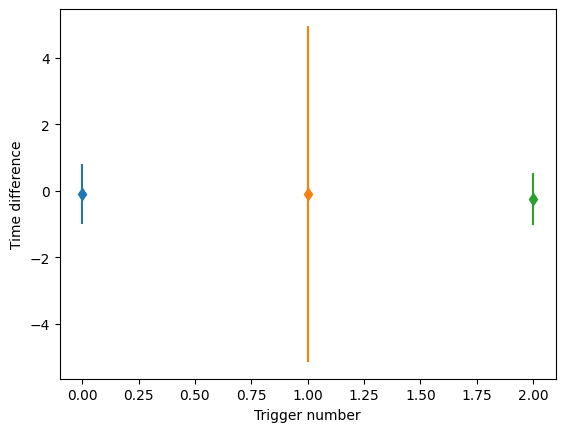

In [443]:
plt.figure()
_, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=200)
# for i in range(0, 5):
#     avg_diff = jnp.nanmean(average_measured_adc[:, i] - adc_avg[i, :])
#     std_diff = jnp.nanstd(average_measured_adc[:, i] - adc_avg[i, :])
#     plt.errorbar(i, avg_diff, yerr=std_diff, marker='d')
# plt.xlabel("Trigger number")
# plt.ylabel("ADC difference")

# _, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_local_old(wfs, threshold=th, Nvalues_scaling=20)

plt.figure()
for i in range(0, 3):
    avg_diff = jnp.nanmean(tick_avg[:, i] - mc_tick_avg[:, i] - 1)
    std_diff = jnp.nanstd(tick_avg[:, i] - mc_tick_avg[:, i] - 1)
    plt.errorbar(i, avg_diff, yerr=std_diff, marker='d')
plt.xlabel("Trigger number")
plt.ylabel("Time difference")

# plt.figure()
# for i in range(0, 5):
#     avg_diff = jnp.nanmean(no_hit_prob[i, :] - measured_no_hit_prob[:, i])
#     std_diff = jnp.nanstd(no_hit_prob[i, :] - measured_no_hit_prob[:, i])
#     plt.errorbar(i, avg_diff, yerr=std_diff, marker='d')
# plt.xlabel("Trigger number")
# plt.ylabel("No-hit probability difference")

Fraction discarded: 0.0%
Fraction discarded: 7.208001989056356e-06%
Fraction discarded: 1.3382443285081536e-05%
Fraction discarded: -1.9066395907429978e-05%
Fraction discarded: 0.0008000571397133172%


Text(0, 0.5, 'Time difference')

<Figure size 640x480 with 0 Axes>

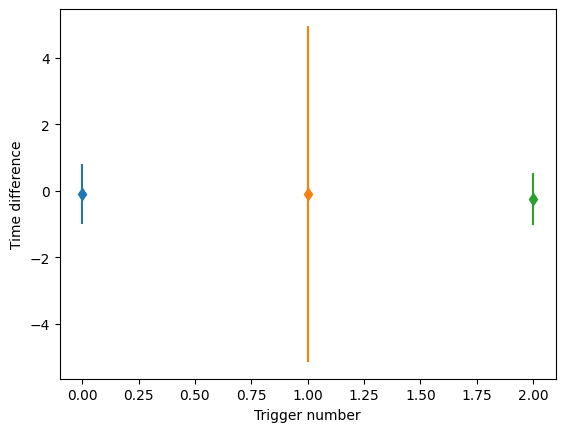

In [444]:
plt.figure()
_, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_local(wfs, threshold=th, Nvalues_scaling=200)
# for i in range(0, 5):
#     avg_diff = jnp.nanmean(average_measured_adc[:, i] - adc_avg[i, :])
#     std_diff = jnp.nanstd(average_measured_adc[:, i] - adc_avg[i, :])
#     plt.errorbar(i, avg_diff, yerr=std_diff, marker='d')
# plt.xlabel("Trigger number")
# plt.ylabel("ADC difference")

# _, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_local_old(wfs, threshold=th, Nvalues_scaling=20)

plt.figure()
for i in range(0, 3):
    avg_diff = jnp.nanmean(tick_avg[:, i] - mc_tick_avg[:, i] - 1)
    std_diff = jnp.nanstd(tick_avg[:, i] - mc_tick_avg[:, i] - 1)
    plt.errorbar(i, avg_diff, yerr=std_diff, marker='d')
plt.xlabel("Trigger number")
plt.ylabel("Time difference")

# plt.figure()
# for i in range(0, 5):
#     avg_diff = jnp.nanmean(no_hit_prob[i, :] - measured_no_hit_prob[:, i])
#     std_diff = jnp.nanstd(no_hit_prob[i, :] - measured_no_hit_prob[:, i])
#     plt.errorbar(i, avg_diff, yerr=std_diff, marker='d')
# plt.xlabel("Trigger number")
# plt.ylabel("No-hit probability difference")

(250.0, 380.0)

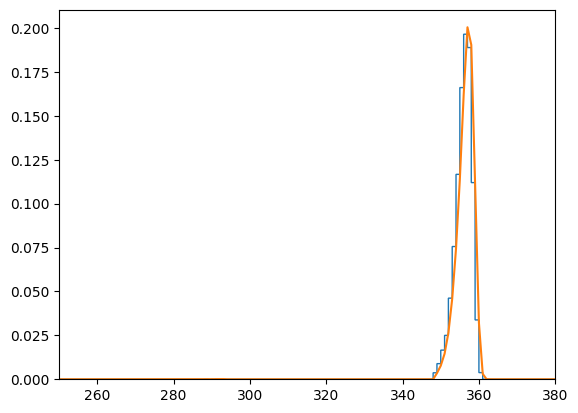

In [341]:
import matplotlib.pyplot as plt

hitid = 1

for ipix in range(1309, 1310):
    plt.hist(mc_ticks[:, ipix, hitid], bins=np.arange(0, 2000), histtype='step', density=True);
    # plt.plot(estimated[ipix, :])
    plt.plot(prob_distrib[:, ipix, hitid])
    # plt.axvline(tick_avg[ipix, 0])
plt.xlim(250, 380)
# plt.xlim(670, 950)
# plt.ylim(0, 0.25)

In [60]:
pixid = 160
adcs_avg, tick_avg, no_hit_prob, prob_distrib = get_adc_values_average_noise_test(wfs, threshold=th, Nvalues_scaling=100)
plt.plot(np.cumsum(wfs[pixid, :])*0.1, linestyle='none', marker='*')

plt.xlim(700, 750)
# plt.ylim(0, 14000)
plt.axhline(th, linestyle='--', color='red')
plt.twinx()
for hitid in range(3):
    plt.hist(mc_ticks[:, pixid, hitid], bins=np.arange(0, 2000), histtype='step', density=True);
    plt.plot(prob_distrib[:, pixid, hitid])
plt.ylim(0, 0.01)

NameError: name 'get_adc_values_average_noise_test' is not defined

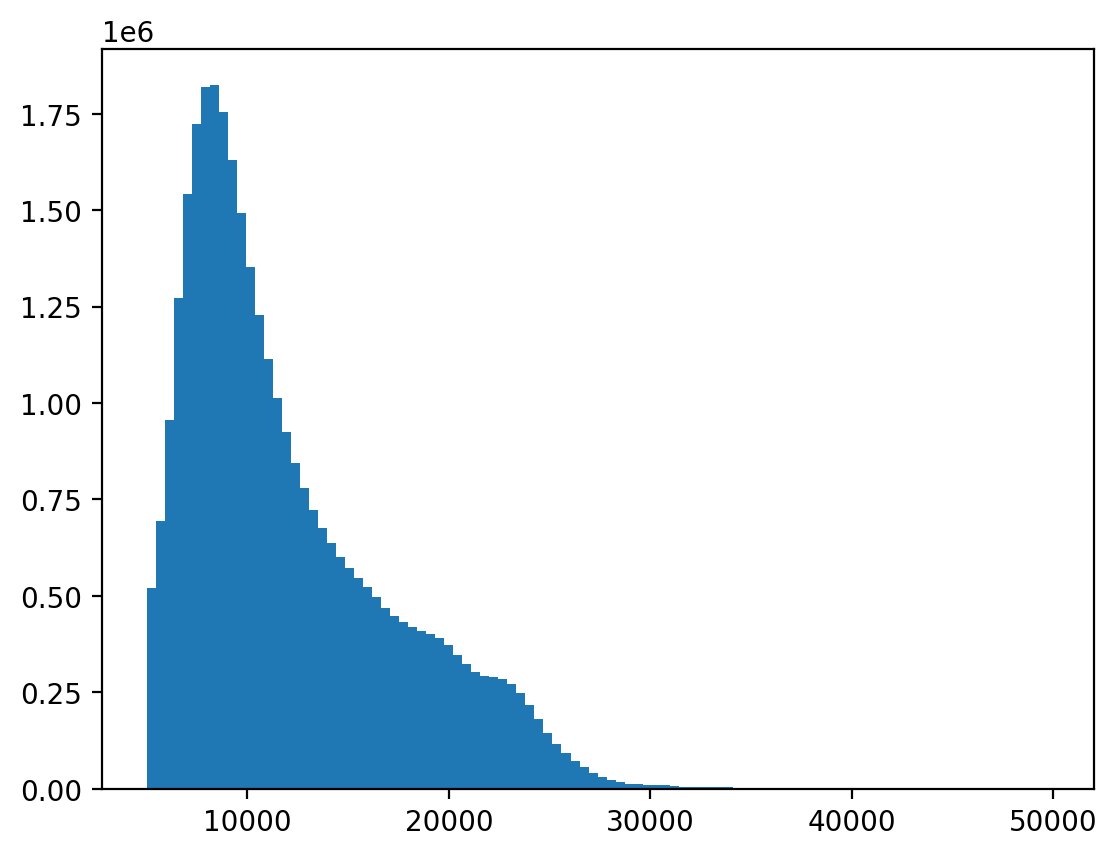

In [85]:
plt.hist(mc_adcs[mc_ticks < 1998].flatten(), bins=100);

In [ ]:
import sys
!{sys.executable} -m pip install -e .

## Debugging: Difference in charge conversion

The issue is in the charge conversion factor:
- `get_adc_values_average_noise_test` uses: `q = wfs * 0.1` (hardcoded)
- `get_adc_values_average_noise_vmap` uses: `q = wfs * params.t_sampling` (parameter)

Let's check what `params.t_sampling` actually is:

In [ ]:
print(f"params.t_sampling = {params.t_sampling}")
print(f"Hardcoded value in get_adc_values_average_noise_test = 0.1")
print(f"Ratio: {params.t_sampling / 0.1}")

In [ ]:
# Compare the charge sums from both approaches
q_test = wfs * 0.1  # As used in get_adc_values_average_noise_test
q_vmap = wfs * params.t_sampling  # As used in get_adc_values_average_noise_vmap

q_sum_test = q_test.cumsum(axis=-1)
q_sum_vmap = q_vmap.cumsum(axis=-1)

print(f"Mean difference in q_sum: {jnp.mean(jnp.abs(q_sum_test - q_sum_vmap))}")
print(f"Max difference in q_sum: {jnp.max(jnp.abs(q_sum_test - q_sum_vmap))}")
print(f"Relative difference: {jnp.mean(jnp.abs(q_sum_test - q_sum_vmap)) / jnp.mean(jnp.abs(q_sum_test))}")

## Fix

To make both functions consistent, you should update `get_adc_values_average_noise_test` to use `params.t_sampling` instead of the hardcoded `0.1` value. 

Alternatively, if `0.1` is the correct value, then `get_adc_values_average_noise_vmap` should be updated to use that hardcoded value instead of `params.t_sampling`.

The key difference is on these lines:
- Line ~469 in `get_adc_values_average_noise_test`: `q = wfs * 0.1`
- Line ~707 in `get_adc_values_average_noise_vmap`: `q = wfs * params.t_sampling`

## Summary of All Differences

There are **THREE key differences** between the two functions:

### 1. Charge conversion factor
- **`get_adc_values_average_noise_test`**: `q = wfs * 0.1` (hardcoded)
- **`get_adc_values_average_noise_vmap`**: `q = wfs * params.t_sampling`

### 2. Interval calculation
- **`get_adc_values_average_noise_test`**: `interval = 18` (hardcoded)
- **`get_adc_values_average_noise_vmap`**: `interval = round((3 * params.CLOCK_CYCLE + params.ADC_HOLD_DELAY * params.CLOCK_CYCLE) / params.t_sampling)`

### 3. Noise sigma
- **`get_adc_values_average_noise_test`**: Uses `sigma` parameter (default 900)
- **`get_adc_values_average_noise_vmap`**: Uses `params.RESET_NOISE_CHARGE`

These differences will cause significantly different results. You need to make them consistent!

In [20]:
# Check all the parameter values
print("=== Parameter Comparison ===\n")

print("1. Charge conversion:")
print(f"   Hardcoded in test: 0.1")
print(f"   params.t_sampling: {params.t_sampling}")
print(f"   Ratio: {params.t_sampling / 0.1}\n")

print("2. Interval:")
print(f"   Hardcoded in test: 18")
interval_vmap = round((3 * params.CLOCK_CYCLE + params.ADC_HOLD_DELAY * params.CLOCK_CYCLE) / params.t_sampling)
print(f"   Calculated in vmap: {interval_vmap}")
print(f"   Difference: {interval_vmap - 18}\n")

print("3. Noise sigma:")
print(f"   Default in test: 900")
print(f"   params.RESET_NOISE_CHARGE: {params.RESET_NOISE_CHARGE}")
print(f"   Ratio: {params.RESET_NOISE_CHARGE / 900}")

=== Parameter Comparison ===

1. Charge conversion:
   Hardcoded in test: 0.1
   params.t_sampling: 0.1
   Ratio: 1.0

2. Interval:
   Hardcoded in test: 18
   Calculated in vmap: 18
   Difference: 0

3. Noise sigma:
   Default in test: 900
   params.RESET_NOISE_CHARGE: 900
   Ratio: 1.0


In [21]:
# Check the number of iterations
print(f"params.MAX_ADC_VALUES = {params.MAX_ADC_VALUES}")
print(f"Hardcoded in test function = 10")
print(f"\nThis means the vmap version runs {params.MAX_ADC_VALUES} iterations")
print(f"while the test version runs only 10 iterations!")

params.MAX_ADC_VALUES = 10
Hardcoded in test function = 10

This means the vmap version runs 10 iterations
while the test version runs only 10 iterations!


In [38]:
# Let's run both functions and compare their outputs directly
print("Running get_adc_values_average_noise_test...")
adcs_avg_test, tick_avg_test, no_hit_prob_test, prob_distrib_test = get_adc_values_average_noise_test(
    wfs, threshold=th, Nvalues_scaling=100, preselection_factor=30
)

print("Running get_adc_values_average_noise_vmap...")
local_params = params.replace(DISCRIMINATION_THRESHOLD=th, fee_paths_scaling=100)
adcs_avg_vmap, tick_avg_vmap, no_hit_prob_vmap, prob_distrib_vmap = get_adc_values_average_noise_vmap(
    local_params, wfs
)

print("\n=== Shape Comparison ===")
print(f"adcs_avg_test shape: {adcs_avg_test.shape}")
print(f"adcs_avg_vmap shape: {adcs_avg_vmap.shape}")
print(f"\ntick_avg_test shape: {tick_avg_test.shape}")
print(f"tick_avg_vmap shape: {tick_avg_vmap.shape}")
print(f"\nno_hit_prob_test shape: {no_hit_prob_test.shape}")
print(f"no_hit_prob_vmap shape: {no_hit_prob_vmap.shape}")

Running get_adc_values_average_noise_test...
Running get_adc_values_average_noise_vmap...



=== Shape Comparison ===
adcs_avg_test shape: (2064, 10)
adcs_avg_vmap shape: (2064, 10)

tick_avg_test shape: (2064, 10)
tick_avg_vmap shape: (2064, 10)

no_hit_prob_test shape: (2064, 10)
no_hit_prob_vmap shape: (2064, 10)


In [39]:
# Compare the actual values
print("=== Value Comparison ===\n")

print("ADC averages:")
print(f"  Mean difference: {jnp.mean(jnp.abs(adcs_avg_test - adcs_avg_vmap))}")
print(f"  Max difference: {jnp.max(jnp.abs(adcs_avg_test - adcs_avg_vmap))}")
print(f"  Relative difference: {jnp.mean(jnp.abs(adcs_avg_test - adcs_avg_vmap)) / jnp.mean(jnp.abs(adcs_avg_test))}\n")

print("Tick averages:")
print(f"  Mean difference: {jnp.mean(jnp.abs(tick_avg_test - tick_avg_vmap))}")
print(f"  Max difference: {jnp.max(jnp.abs(tick_avg_test - tick_avg_vmap))}")
print(f"  Relative difference: {jnp.nanmean(jnp.abs(tick_avg_test - tick_avg_vmap)) / jnp.nanmean(jnp.abs(tick_avg_test))}\n")

print("No-hit probabilities:")
print(f"  Mean difference: {jnp.mean(jnp.abs(no_hit_prob_test - no_hit_prob_vmap))}")
print(f"  Max difference: {jnp.max(jnp.abs(no_hit_prob_test - no_hit_prob_vmap))}")
print(f"  Relative difference: {jnp.mean(jnp.abs(no_hit_prob_test - no_hit_prob_vmap)) / jnp.mean(jnp.abs(no_hit_prob_test))}\n")

# Check some specific examples
print("First pixel, first few hits:")
print(f"  adcs_avg_test: {adcs_avg_test[0, :5]}")
print(f"  adcs_avg_vmap: {adcs_avg_vmap[0, :5]}")
print(f"  Difference: {adcs_avg_test[0, :5] - adcs_avg_vmap[0, :5]}")

=== Value Comparison ===

ADC averages:
  Mean difference: 62.54582214355469
  Max difference: 11678.796875
  Relative difference: 0.023644043132662773

Tick averages:
  Mean difference: 4.738711833953857
  Max difference: 809.7279052734375
  Relative difference: 0.03785619139671326

No-hit probabilities:
  Mean difference: 2.0176742054900387e-06
  Max difference: 0.038759149610996246
  Relative difference: 2.2841659301775508e-06

First pixel, first few hits:
  adcs_avg_test: [11339.457  9951.603  9114.477     0.        0.   ]
  adcs_avg_vmap: [11339.456  9951.604  9114.477     0.        0.   ]
  Difference: [ 0.00097656 -0.00097656  0.          0.          0.        ]


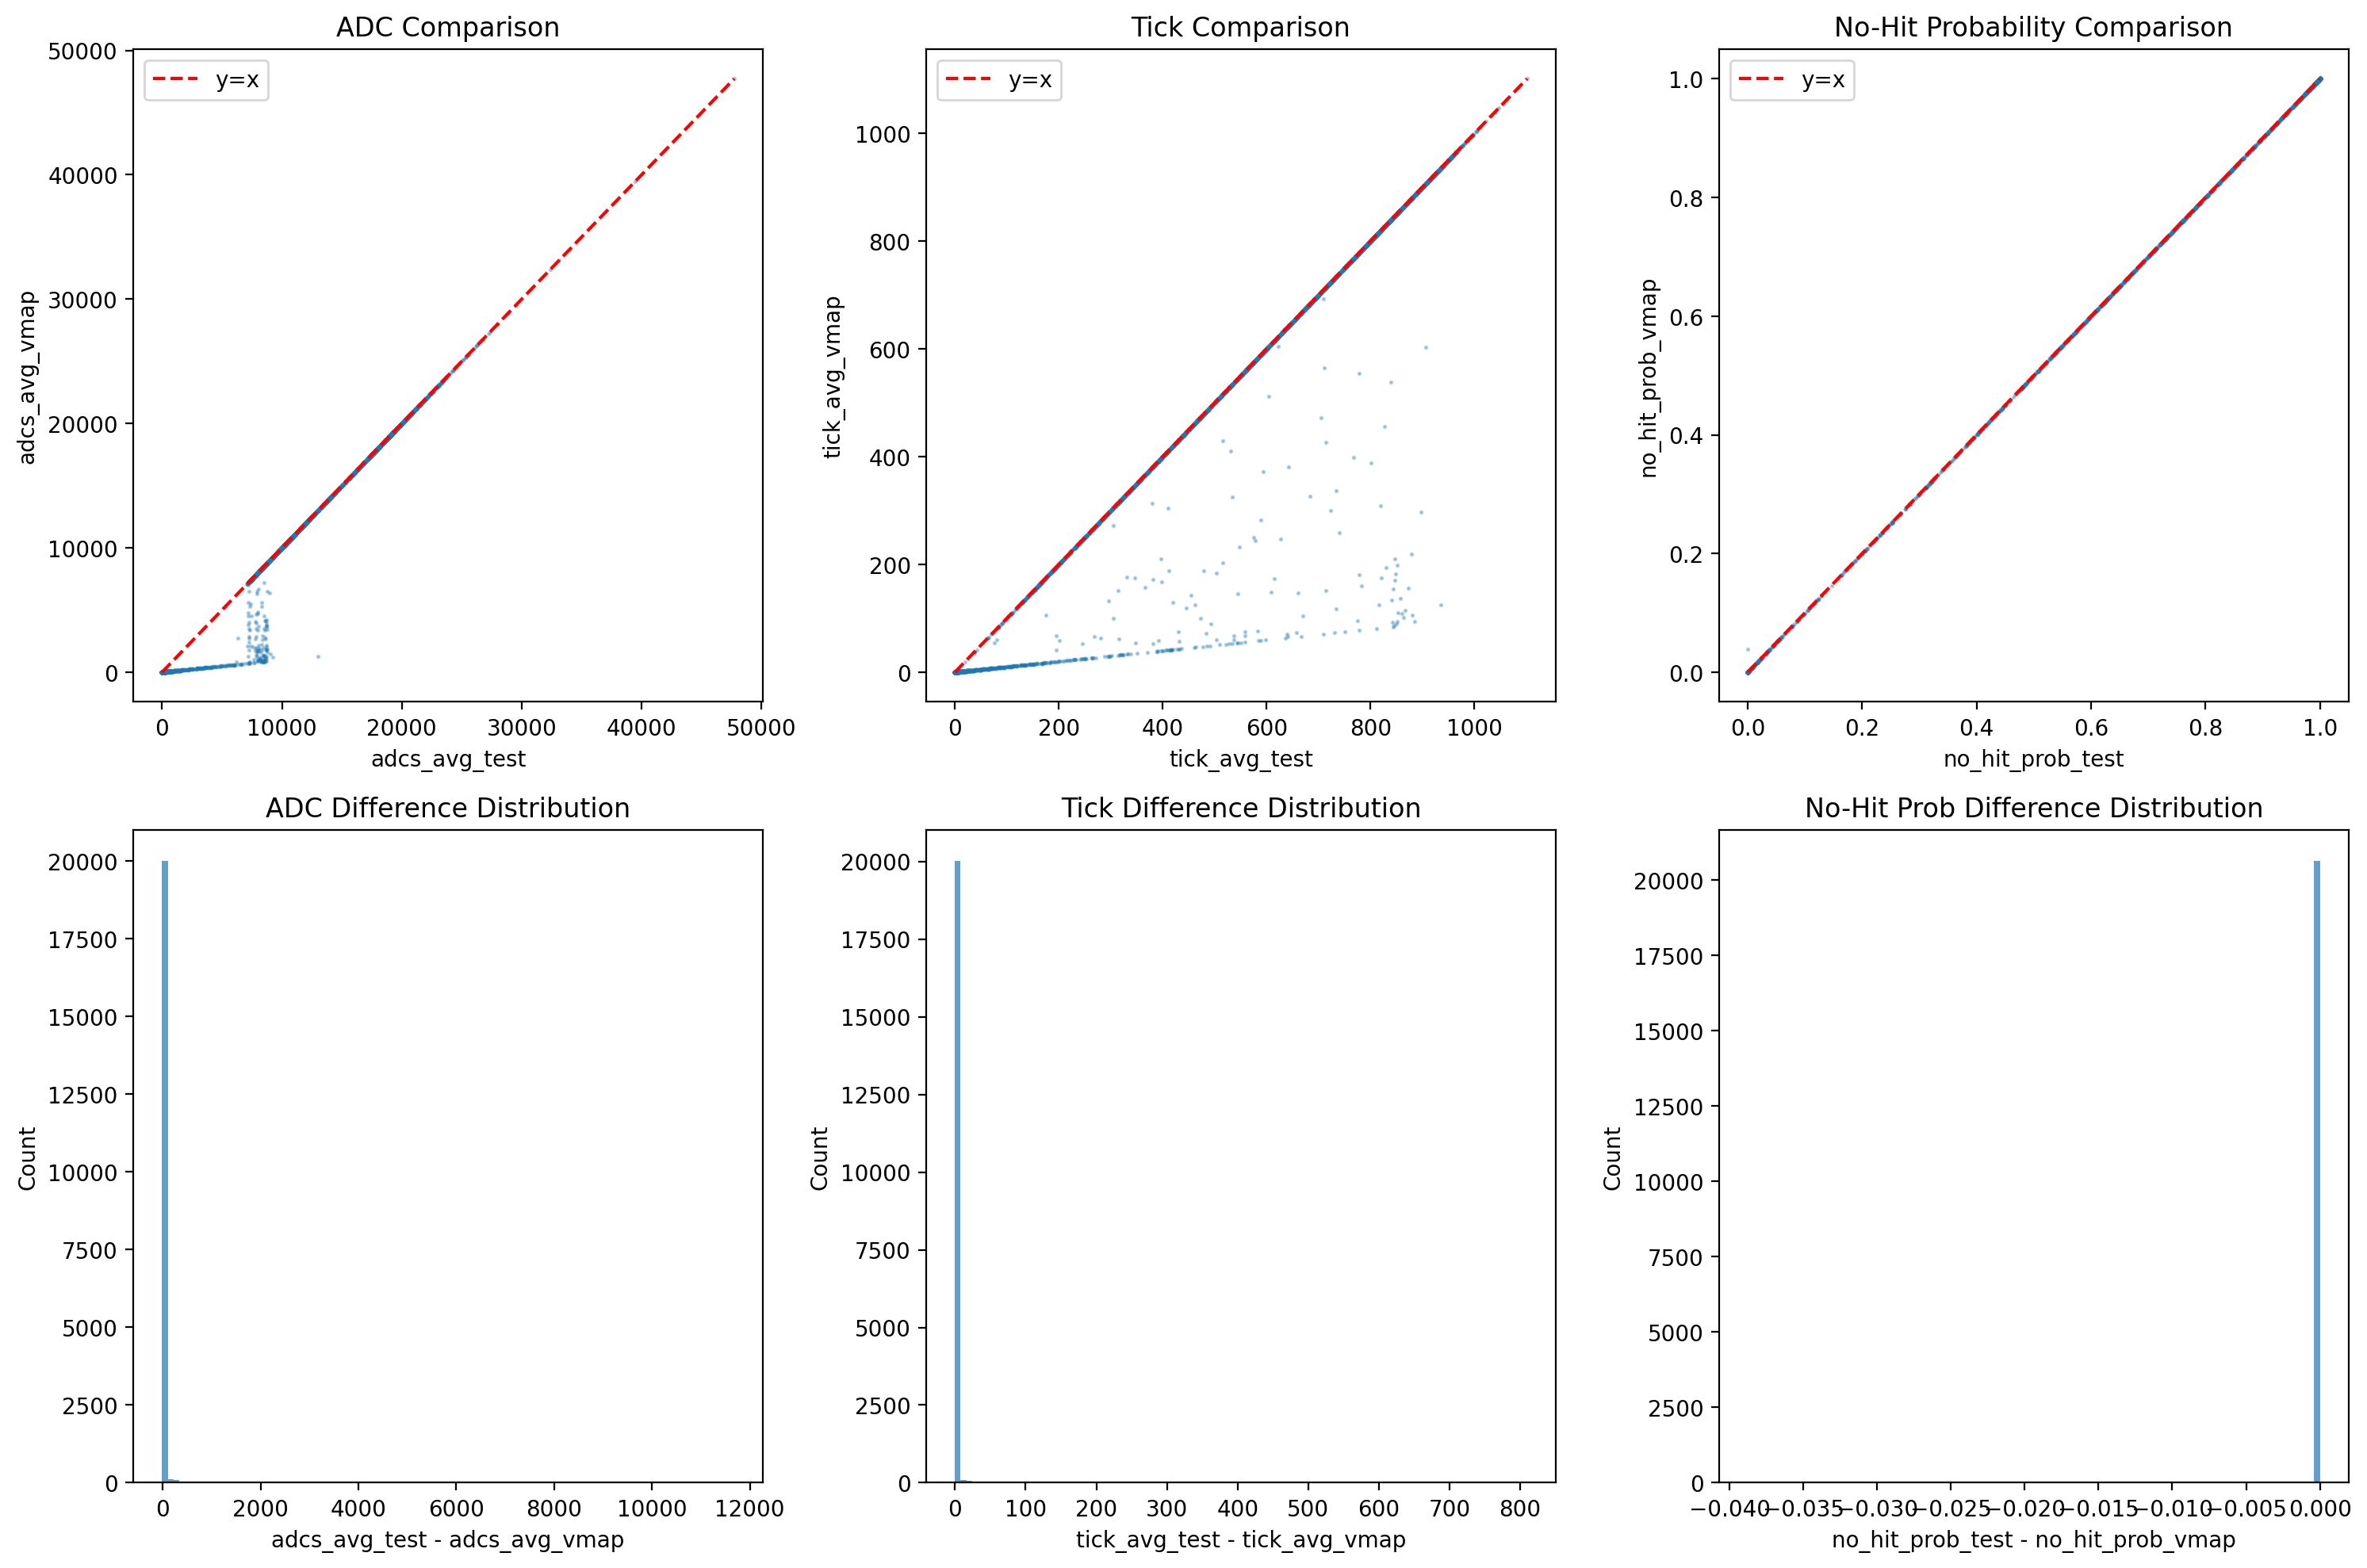

In [40]:
# Visualize the differences
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

# ADC comparison
axs[0, 0].scatter(adcs_avg_test.flatten(), adcs_avg_vmap.flatten(), s=1, alpha=0.3)
axs[0, 0].plot([0, adcs_avg_test.max()], [0, adcs_avg_test.max()], 'r--', label='y=x')
axs[0, 0].set_xlabel('adcs_avg_test')
axs[0, 0].set_ylabel('adcs_avg_vmap')
axs[0, 0].set_title('ADC Comparison')
axs[0, 0].legend()

axs[1, 0].hist((adcs_avg_test - adcs_avg_vmap).flatten(), bins=100, alpha=0.7)
axs[1, 0].set_xlabel('adcs_avg_test - adcs_avg_vmap')
axs[1, 0].set_ylabel('Count')
axs[1, 0].set_title('ADC Difference Distribution')

# Tick comparison
axs[0, 1].scatter(tick_avg_test.flatten(), tick_avg_vmap.flatten(), s=1, alpha=0.3)
axs[0, 1].plot([0, tick_avg_test.max()], [0, tick_avg_test.max()], 'r--', label='y=x')
axs[0, 1].set_xlabel('tick_avg_test')
axs[0, 1].set_ylabel('tick_avg_vmap')
axs[0, 1].set_title('Tick Comparison')
axs[0, 1].legend()

axs[1, 1].hist((tick_avg_test - tick_avg_vmap).flatten(), bins=100, alpha=0.7)
axs[1, 1].set_xlabel('tick_avg_test - tick_avg_vmap')
axs[1, 1].set_ylabel('Count')
axs[1, 1].set_title('Tick Difference Distribution')

# No-hit probability comparison
axs[0, 2].scatter(no_hit_prob_test.flatten(), no_hit_prob_vmap.flatten(), s=1, alpha=0.3)
axs[0, 2].plot([0, 1], [0, 1], 'r--', label='y=x')
axs[0, 2].set_xlabel('no_hit_prob_test')
axs[0, 2].set_ylabel('no_hit_prob_vmap')
axs[0, 2].set_title('No-Hit Probability Comparison')
axs[0, 2].legend()

axs[1, 2].hist((no_hit_prob_test - no_hit_prob_vmap).flatten(), bins=100, alpha=0.7)
axs[1, 2].set_xlabel('no_hit_prob_test - no_hit_prob_vmap')
axs[1, 2].set_ylabel('Count')
axs[1, 2].set_title('No-Hit Prob Difference Distribution')

plt.tight_layout()